> **TL;DR**
>
> - The payoff: a NumPy-only training library that reaches about 98% test accuracy on MNIST and matches an identical PyTorch model step for step, from the same initial weights on the same batches.
> - A neural network is a stack of linear maps with non-linear activations in between. Without the activations, the whole stack collapses into a single linear map.
> - Training means finding weights that make a loss small. For classification the loss is cross-entropy, computed straight from the logits (log-softmax) so it never overflows or takes $\log 0$.
> - Backpropagation is the chain rule run backwards. Each layer turns the gradient it receives into a gradient for its weights and one for its input: three matrix products per layer.
> - Stochastic gradient descent takes small steps against the gradient, estimated on mini-batches. We build all of it in NumPy, check every gradient against finite differences, and train on a 3-class spiral.
> - Each layer multiplies the variance of its signal by $n_{in}\mathrm{Var}(w)$, so initial weights must have variance $2/n_{in}$ under ReLU (Kaiming) to keep activations and gradients from exploding or vanishing.
> - Large weights let a network memorise noise; weight decay (L2 or L1) makes them expensive. BatchNorm re-standardises every layer at every step, which widens the usable learning-rate range about 30-fold and smooths the loss landscape of deep networks. AdamW gives every parameter its own step size.
>
> **After reading**, you will be able to derive every piece of a training loop, implement it yourself, and tell why a run fails when it does.

---

# Introduction

> *"If you cannot explain something in simple terms, you don't understand it."* (by Richard Feynman)

This post is an attempt to explain, in simple terms, how a basic neural network is trained, by building one with only NumPy.

Neural networks are *universal function approximators*: with enough hidden units, even a single hidden layer can approximate any continuous function on a bounded region as closely as we like ([Cybenko, 1989](https://doi.org/10.1007/BF02551274); [Hornik et al., 1989](https://doi.org/10.1016/0893-6080(89)90020-8)). This theorem promises that good weights exist, and to find them we do *training*. In this post, we build it piece by piece: the forward pass, the loss, backpropagation and stochastic gradient descent, then the tricks that make it stable (initialisation, weight decay, batch normalisation, Adam), finishing on MNIST. Each idea gets its math, then its code, then a test run. By the end of this post, you will be able to reason through the math of training a basic neural network and implement it yourself.

This post assumes basic calculus (derivatives, the chain rule), linear algebra (matrix products) and Python.

> **How to read this post.** It's long, but it's meant to be read in parts, not in one sitting. Each idea is explained in prose and math first and the code comes after, so on a first read you can skim the code and still follow along. Plot code is folded away.
>
> 1.  **Build it**: [Forward Pass](#forward-pass) and [Backward Pass](#backward-pass). About 25 min (40 with code). You end with a network that computes its own gradients, every one checked.
> 2.  **Train it**: [Optimiser](#optimiser-stochastic-gradient-descent). About 5 min (10 with code). You end with a trained classifier on the spiral.
> 3.  **Train it well**: [Weight Initialisation](#weight-initialisation) and [Weight Decay](#weight-decay). About 12 min (25 with code). Why networks explode, vanish or overfit, and the fixes.
> 4.  **Make it robust**: [Batch Normalisation](#batch-normalisation) and [Adam and AdamW](#adam-and-adamw). About 15 min (30 with code). A much wider range of learning rates that work, and a step size for every parameter.
> 5.  **Prove it**: [From Spirals to MNIST](#from-spirals-to-mnist). About 2 min (6 with code). 98% on MNIST, matching PyTorch step for step.
>
> Parts 1 and 2 are a complete story: stop there and you have trained a neural network from scratch. Parts 3 to 5 build on each other, so read them in order, one sitting each. Every part ends with a ✓ checkpoint.
>
> Already train networks in PyTorch and familiar with back-propagation? Skim Parts 1 and 2 and start at Part 3. Only want the Pytorch comparison result? Jump to Part 5.

We start with a simple non-linear classification task, build every concept from the ground up on it, and finally transfer everything to MNIST.

The task: classify points on three interleaved spiral arms, 300 points per arm. A point of class $k$ is $(r\sin t,\ r\cos t)$: the radius $r$ grows from 0 to 1 while the angle $t$ sweeps one full turn starting at $2\pi k/3$, with Gaussian noise on $t$. No straight line separates the arms, so the model must learn a curved boundary.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

In [2]:
#| echo: false
# plot helper: figure style for the blog (SVG output, light recessive chrome)
%config InlineBackend.figure_formats = ["svg"]
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8, "axes.axisbelow": True,
    "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2,
})
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]                  # categorical slots 1-3
CLASS_COLORS = plt.cm.Spectral(np.array([0.0, 0.5, 1.0]))   # the class colours plot_spiral uses
INK, INK_2, MUTED, HAIRLINE = "#0b0b0b", "#52514e", "#898781", "#c3c2b7"

### The dataset

`make_spiral` generates the arms and `plot_spiral` draws them.

In [3]:
def make_spiral(n_per_class=300, K=3, noise=0.2, turns=1.0, seed=0):
    rng = np.random.default_rng(seed)
    X = np.zeros((n_per_class * K, 2)); y = np.zeros(n_per_class * K, dtype=int)
    for k in range(K):
        idx = slice(n_per_class * k, n_per_class * (k + 1))
        r = np.linspace(0.0, 1.0, n_per_class)
        t = np.linspace(k * 2*np.pi/K, k * 2*np.pi/K + turns * 2*np.pi, n_per_class) \
            + rng.normal(0, noise, n_per_class)
        X[idx] = np.c_[r * np.sin(t), r * np.cos(t)]
        y[idx] = k
    return X, y

In [4]:
def plot_spiral(X, Y):
    plt.figure(figsize=(6, 6))
    plt.scatter(X[:, 0], X[:, 1], c=Y, s=40, cmap=plt.cm.Spectral)
    plt.xlim(-1, 1); plt.ylim(-1, 1)
    plt.show()

In [5]:
X, Y = make_spiral()

In [6]:
X[:5]

array([[ 0.00000000e+00,  0.00000000e+00],
       [-1.80834402e-05,  3.34443272e-03],
       [ 1.13239633e-03,  6.59241287e-03],
       [ 8.42038692e-04,  9.99804910e-03],
       [-3.08706829e-04,  1.33743641e-02]])

In [7]:
Y[:5]

array([0, 0, 0, 0, 0])

In [8]:
# demo: a quick look at the data
r = np.linalg.norm(X, axis=1)
print("X:", X.shape, "  Y:", Y.shape)
print("points per class:", np.bincount(Y))
print(f"x1 in [{X[:, 0].min():.2f}, {X[:, 0].max():.2f}],  x2 in [{X[:, 1].min():.2f}, {X[:, 1].max():.2f}],  radius in [{r.min():.2f}, {r.max():.2f}]")

X: (900, 2)   Y: (900,)
points per class: [300 300 300]
x1 in [-0.94, 0.98],  x2 in [-0.90, 0.99],  radius in [0.00, 1.00]


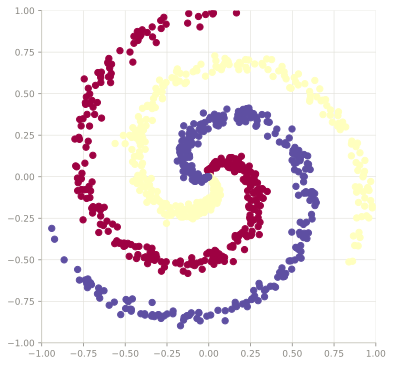

In [9]:
#| fig-alt: "Scatter plot of 900 points forming three interleaved spiral arms that start at the origin and wind outward to radius 1, coloured dark red, pale yellow and purple by class."
plot_spiral(X, Y)

*Figure 1: The three spiral arms, 300 points each. Near the centre the classes crowd together, which is the hardest region to separate.*
{.caption}

### Train/test split

We hold out 20% of the points as a test set that is never trained on.

In [10]:
def split_train_test(X, Y, split_ratio=0.8, seed=42):
    rnd = np.random.default_rng(seed=seed)
    idx = np.arange(X.shape[0])
    idx = rnd.choice(idx, size=idx.shape[0], replace=False)
    train_len = int(idx.shape[0] * split_ratio)
    train_x, test_x = X[idx[:train_len]], X[idx[train_len:]]
    train_y, test_y = Y[idx[:train_len]], Y[idx[train_len:]]
    return train_x, train_y, test_x, test_y

In [11]:
train_X, train_Y, test_X, test_Y = split_train_test(X, Y)

In [12]:

train_X.shape, test_X.shape, train_Y.shape, test_Y.shape

((720, 2), (180, 2), (720,), (180,))

---

## Notation

Every symbol is defined where it first appears; the table is for reference. Class indices start at 0, as in the code.

<details>
<summary><strong>Symbol table</strong> (click to expand)</summary>

| Symbol | Meaning | Shape |
|---|---|---|
| $B$ | batch size: number of samples processed together | scalar |
| $C$ | number of classes ($C = 3$) | scalar |
| $x$, $X$ | one input sample; a batch of inputs stacked as rows | $(n_{in},)$, $(B, n_{in})$ |
| $W_l$, $b_l$ | weight matrix and bias of layer $l$ | $(n_{out}, n_{in})$, $(n_{out},)$ |
| $Z_l$ | pre-activations of layer $l$ (`z` in the code) | $(B, n_{out})$ |
| $A_l$ | activations $\mathrm{ReLU}(Z_l)$, with $A_0 = X$ (`activation` in the code) | $(B, n_{out})$ |
| $z$, $p$ | logits and softmax probabilities of one sample | $(C,)$ |
| $P$, $Y$ | probabilities and one-hot labels of a batch | $(B, C)$ |
| $y_n$ | integer label of sample $n$ | scalar |
| $L$ | loss, a single number | scalar |
| $\theta$ | all trainable parameters $\{W_l, b_l\}$ | |
| $\delta$ | error signal $\partial L/\partial z$ of one sample | $(n_{out},)$ |
| $dW$, $dZ$, ... | shorthand for $\partial L/\partial W$, $\partial L/\partial Z$, ...; same shape as $W$, $Z$, ... | |
| $\mathbb{1}\{\cdot\}$ | indicator: $1$ if the condition holds, else $0$ | |
| $\odot$ | element-wise product | |
| $\eta$ | learning rate | scalar |
| $n_{in}$, $n_{out}$ | fan-in and fan-out of a layer (its input and output widths) | scalar |
| $\lambda$ | weight-decay strength | scalar |
| $\mu_B$, $\sigma_B^2$ | BatchNorm's per-feature batch mean and variance | $(n_{out},)$ |
| $\gamma$, $\beta$ | BatchNorm's learnable scale and shift | $(n_{out},)$ |
| $m_t$, $v_t$ | Adam's running averages of the gradient and the squared gradient | same as the parameter |
| $\beta_1$, $\beta_2$ | Adam's averaging rates (not BatchNorm's $\beta$) | scalar |

</details>

### The network at a glance

The figure below puts the notation together. A mini-batch of $B$ samples enters on the left as $X$. Each layer takes the previous layer's output, applies its weights $W_l$ and bias $b_l$ (and a ReLU, except in the last layer), and hands its output to the next. The last layer outputs one score (logit) per class, and the loss compares those scores with the labels. Every piece is built and explained in the sections that follow.

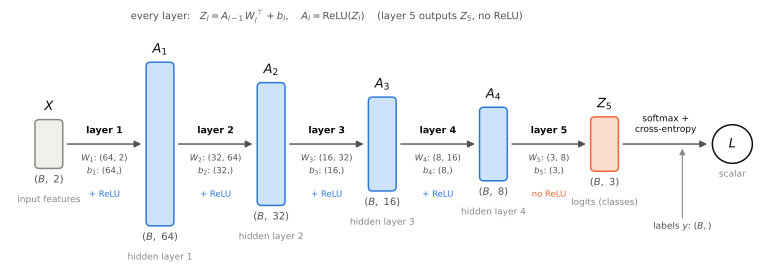

In [13]:
#| echo: false
#| fig-alt: "Diagram of the network as a chain of tensors from left to right: input X of shape (B, 2), then hidden activations A1 (B, 64), A2 (B, 32), A3 (B, 16), A4 (B, 8), drawn as columns whose heights grow with the number of features, then logits Z5 (B, 3), then the scalar loss L. Each arrow between columns is one layer, labelled with its weight shape W (n_out, n_in) and bias shape b (n_out,), and with + ReLU for layers 1 to 4 and no ReLU for layer 5. Labels y of shape (B,) join the last arrow, which applies softmax and cross-entropy."
# plot helper: the network we build, as a chain of tensors; each arrow is one layer
from matplotlib.patches import FancyBboxPatch, Circle

widths = [2, 64, 32, 16, 8, 3]                            # features in X, A_1 ... A_4, Z_5 (layers = [64, 32, 16, 8, 3])
names = ["$X$", "$A_1$", "$A_2$", "$A_3$", "$A_4$", "$Z_5$"]
roles = ["input features", "hidden layer 1", "hidden layer 2", "hidden layer 3", "hidden layer 4", "logits (classes)"]
fills = ["#f0efec"] + ["#cde2fb"] * 4 + ["#fbdccd"]       # input grey, hidden activations blue, logits orange
edges = [MUTED] + [SERIES[0]] * 4 + [SERIES[1]]

fig, ax = plt.subplots(figsize=(11, 4.0))
ax.set_xlim(-0.75, 13.1); ax.set_ylim(-2.4, 2.55); ax.axis("off")
xs = np.arange(len(widths)) * 2.0
col_w = 0.5
heights = [0.45 + 2.6 * np.sqrt(n / 64) for n in widths]  # column height grows with the number of features

for x, h, n, name, role, fc, ec in zip(xs, heights, widths, names, roles, fills, edges):
    ax.add_patch(FancyBboxPatch((x - col_w / 2, -h / 2), col_w, h, boxstyle="round,pad=0,rounding_size=0.08", fc=fc, ec=ec, lw=1.5))
    ax.text(x, h / 2 + 0.12, name, ha="center", va="bottom", fontsize=13)
    ax.text(x, -h / 2 - 0.12, f"$(B,\\ {n})$", ha="center", va="top", fontsize=10, color=INK_2)
    ax.text(x, -h / 2 - 0.5, role, ha="center", va="top", fontsize=9, color=MUTED)

n_layers_fig = len(widths) - 1
for l, (x0, x1) in enumerate(zip(xs[:-1], xs[1:]), start=1):
    ax.annotate("", xy=(x1 - col_w / 2 - 0.05, 0), xytext=(x0 + col_w / 2 + 0.05, 0),
                arrowprops=dict(arrowstyle="-|>", color=INK_2, lw=1.4, mutation_scale=14))
    mid = (x0 + x1) / 2
    ax.text(mid, 0.16, f"layer {l}", ha="center", va="bottom", fontsize=9.5, fontweight="bold")
    ax.text(mid, -0.14, f"$W_{l}$: ({widths[l]}, {widths[l - 1]})\n$b_{l}$: ({widths[l]},)", ha="center", va="top",
            fontsize=8.5, color=INK_2, linespacing=1.5)
    ax.text(mid, -0.86, "+ ReLU" if l < n_layers_fig else "no ReLU", ha="center", va="top", fontsize=8.5,
            color=SERIES[0] if l < n_layers_fig else SERIES[1])

# loss: softmax + cross-entropy against the labels
x_loss = xs[-1] + 2.3
ax.annotate("", xy=(x_loss - 0.42, 0), xytext=(xs[-1] + col_w / 2 + 0.05, 0),
            arrowprops=dict(arrowstyle="-|>", color=INK_2, lw=1.4, mutation_scale=14))
ax.text((xs[-1] + x_loss) / 2 - 0.05, 0.16, "softmax +\ncross-entropy", ha="center", va="bottom", fontsize=9, linespacing=1.3)
ax.add_patch(Circle((x_loss, 0), 0.36, fc="white", ec=INK, lw=1.5))
ax.text(x_loss, 0, "$L$", ha="center", va="center", fontsize=13)
ax.text(x_loss, -0.48, "scalar", ha="center", va="top", fontsize=9, color=MUTED)
ax.annotate("labels $y$: $(B,)$", xy=((xs[-1] + x_loss) / 2 + 0.25, -0.05), xytext=((xs[-1] + x_loss) / 2 + 0.25, -1.45),
            ha="center", va="top", fontsize=9, color=INK_2, arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.1, mutation_scale=12))

# the rule every layer follows
ax.text(xs[2] + 1.0, 2.5, "every layer:   $Z_l = A_{l-1}\\,W_l^{\\top} + b_l$,    $A_l = \\mathrm{ReLU}(Z_l)$    (layer 5 outputs $Z_5$, no ReLU)",
        ha="center", va="top", fontsize=10, color=INK_2)
fig.tight_layout()
plt.show()

*Figure 2: The network we build, with the input and output of every layer and their shapes ($B$ = batch size). (The column heights grow with the number of features)* $\text {Hidden layer -> blue boxes, Hidden units -> each neuron in a hidden layer.}$
{.caption}

---

## Forward Pass

The forward pass turns an input into a prediction. Our network maps $2 \ \text {(input feat)} \to 64 \ \text {(hidden layer 1)} \to 32 \ \text {(hidden layer 2)} \to 16 \ \text {(hidden layer 3)} \to 8 \ \text {(hidden layer 4)} \to 3 \ \text {(output class)}$: each layer applies a linear map followed by an activation, and the last layer outputs one score per class. We build each piece, test it, then chain them together.

A small helper draws Gaussian random arrays. We use it for test inputs and, later, to initialise the weights.

In [14]:
def get_dummy_inputs(input_dim, seed=42, mean=0, std=1):
    rng = np.random.default_rng(seed)
    return rng.normal(size=input_dim, loc=mean, scale=std)

### Linear layer

**Intuition.** A linear layer takes $n_{in}$ numbers and produces $n_{out}$ new ones. Each output is a weighted sum of all the inputs plus an offset. Geometrically, the matrix rotates, stretches and projects the input into an $n_{out}$-dimensional space, and the bias shifts the result.

> **Definition: linear layer.** For an input $x\in\mathbb{R}^{n_{in}}$, weights $W\in\mathbb{R}^{n_{out}\times n_{in}}$ and bias $b\in\mathbb{R}^{n_{out}}$:
>
> $$z = Wx + b, \qquad z_i = \sum_{j=1}^{n_{in}} W_{ij}\,x_j + b_i\quad(i = 1,\dots,n_{out}).\tag{1}$$

Row $i$ of $W$ holds the weights of output $i$, so $W$ has shape `(n_out, n_in)`. That is the same convention as PyTorch's [`nn.Linear`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html).

**From one sample to a batch.** We process $B$ samples at once by stacking them as the rows of $X\in\mathbb{R}^{B\times n_{in}}$, so row $n$ is $x_n^\top$. Transposing equation (1) for sample $n$ turns it into a row:

$$z_n^\top = (Wx_n + b)^\top = x_n^\top W^\top + b^\top.$$

Stacking the $B$ rows gives

$$Z = XW^\top + \mathbf{1}b^\top,\tag{2}$$

where $\mathbf{1}$ is a column of $B$ ones, so $\mathbf{1}b^\top$ repeats $b^\top$ on every row. NumPy does that repetition for us: adding a `(n_out,)` array to a `(B, n_out)` array *broadcasts* it across the rows.

| Math | Code | Shape |
|---|---|---|
| $X$ | `x` | `(B, n_in)` |
| $W$ | `w` | `(n_out, n_in)` |
| $b$ | `b` | `(n_out,)` |
| $Z = XW^\top + \mathbf{1}b^\top$ | `out` | `(B, n_out)` |

**Worked example.** Take $W = \begin{bmatrix}1 & 2\\ -1 & 0.5\end{bmatrix}$, $b = \begin{bmatrix}0.5\\ -1\end{bmatrix}$ and $x = \begin{bmatrix}3\\ -1\end{bmatrix}$. By equation (1),

$$z_0 = 1\cdot 3 + 2\cdot(-1) + 0.5 = 1.5,\qquad z_1 = -1\cdot 3 + 0.5\cdot(-1) - 1 = -4.5.$$

A second sample $x = [0,\ 2]^\top$ gives $z = [4.5,\ 0]^\top$. Equation (2) should return both results as the rows of one matrix.

In [15]:
def linear(x, w, b):
    # z = x @ W.T + b
    out = np.matmul(x, np.transpose(w)) + b   # (B, n_out)
    return out

In [16]:
# demo: the worked example (expect [[1.5, -4.5], [4.5, 0.0]])
W_ex = np.array([[1.0, 2.0], [-1.0, 0.5]])
b_ex = np.array([0.5, -1.0])
X_ex = np.array([[3.0, -1.0], [0.0, 2.0]])
Z_ex = linear(X_ex, W_ex, b_ex)
Z_ex

array([[ 1.5, -4.5],
       [ 4.5,  0. ]])

In [17]:
# demo: shapes on a random batch, B = 4, n_in = 2, n_out = 3
linear(get_dummy_inputs((4, 2)), get_dummy_inputs((3, 2), seed=1), get_dummy_inputs(3, seed=2)).shape

(4, 3)

### Why we need activations

**Intuition.** Stacking linear layers does not make a model more expressive, because a linear map of a linear map is still a linear map.

**Derivation.** Two linear layers with nothing in between:

$$\begin{aligned} z^{(2)} &= W_2\,(W_1x + b_1) + b_2 \\ &= (W_2W_1)\,x + (W_2b_1 + b_2) \\ &= W'x + b'. \end{aligned}\tag{3}$$

Any number of linear layers collapses the same way into one layer with $W' = W_L\cdots W_2W_1$, so a deep *linear* network can still only draw straight decision boundaries. A non-linear **activation** between the layers breaks the collapse. We use the **rectified linear unit** ([Nair & Hinton, 2010](https://www.cs.toronto.edu/~hinton/absps/reluICML.pdf); [Glorot et al., 2011](https://proceedings.mlr.press/v15/glorot11a.html)), applied element-wise:

$$\mathrm{ReLU}(z) = \max(0,\ z).\tag{4}$$

It passes positive values unchanged and sets negative values to zero. First element by element, then as a function:

In [18]:
d = get_dummy_inputs(5, std=2); d

array([ 0.60943416, -2.07996821,  1.50090239,  1.88112943, -3.90207038])

In [19]:
np.where(d > 0, d, 0)

array([0.60943416, 0.        , 1.50090239, 1.88112943, 0.        ])

In [20]:
def relu(x):
    return np.where(x > 0, x, 0)

In [21]:
relu(d)

array([0.60943416, 0.        , 1.50090239, 1.88112943, 0.        ])

In [22]:
# demo: ReLU on the worked example's Z. -4.5 is blocked, and so is 0 (z > 0 is False at 0)
relu(Z_ex)

array([[1.5, 0. ],
       [4.5, 0. ]])

In [23]:
# demo: eq. (3) - two linear layers equal one linear layer, unless a ReLU sits between them
W1, b1 = get_dummy_inputs((4, 2), seed=1), get_dummy_inputs(4, seed=2)
W2, b2 = get_dummy_inputs((3, 4), seed=3), get_dummy_inputs(3, seed=4)
x_demo = get_dummy_inputs((5, 2), seed=5)

two_linear = linear(linear(x_demo, W1, b1), W2, b2)
one_linear = linear(x_demo, W2 @ W1, W2 @ b1 + b2)               # W' and b' from eq. (3)
with_relu = linear(relu(linear(x_demo, W1, b1)), W2, b2)
print("linear -> linear  ==  one linear layer:", np.allclose(two_linear, one_linear))
print("linear -> ReLU -> linear  ==  one linear layer:", np.allclose(with_relu, one_linear))

linear -> linear  ==  one linear layer: True
linear -> ReLU -> linear  ==  one linear layer: False


**Why many hidden units?** A single ReLU is a hinge: flat, then a straight line. A weighted sum of shifted hinges,

$$g(x) = c_0 + \sum_{k=1}^{K} c_k\,\mathrm{ReLU}(x - t_k),\tag{5}$$

is a piecewise-linear curve that can bend at every knot $t_k$. Each term $\mathrm{ReLU}(x - t_k)$ is exactly one hidden unit with weight 1 and bias $-t_k$, and the $c_k$ are the output layer's weights. With enough knots, $g$ can follow any continuous curve as closely as we like. That is the intuition behind the universal approximation theorem for ReLU networks ([Leshno et al., 1993](https://doi.org/10.1016/S0893-6080(05)80131-5)). Below we fit equation (5) to $\sin(2x)$ by least squares with $K = 1$, $3$ and $10$ hidden units.

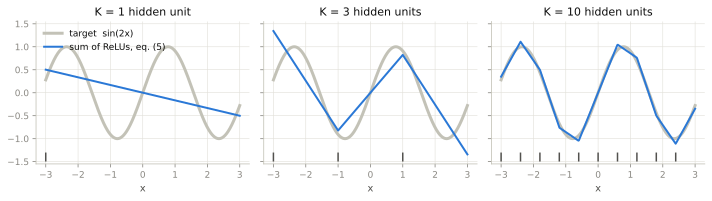

In [24]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Three panels fitting sin(2x) on [-3, 3]. With 1 ReLU the fit is a straight line; with 3 it is a coarse zig-zag; with 10 it follows the sine curve closely. Tick marks on the bottom show the knot positions."
# plot helper: least-squares fit of eq. (5) to sin(2x) with K hidden units
xs = np.linspace(-3, 3, 400)
target = np.sin(2 * xs)
fig, axes = plt.subplots(1, 3, figsize=(10, 2.9), sharey=True)
for ax, K in zip(axes, [1, 3, 10]):
    knots = np.linspace(-3, 3, K + 1)[:-1]                       # one knot per hidden unit
    features = np.column_stack([np.ones_like(xs)] + [relu(xs - t) for t in knots])
    coef, *_ = np.linalg.lstsq(features, target, rcond=None)
    ax.plot(xs, target, color=HAIRLINE, lw=3, label="target  sin(2x)")
    ax.plot(xs, features @ coef, color=SERIES[0], lw=2, label="sum of ReLUs, eq. (5)")
    ax.plot(knots, np.full(K, -1.4), "|", color=INK_2, ms=9, mew=1.5)
    ax.set_title(f"K = {K} hidden unit{'s' if K > 1 else ''}")
    ax.set_xlabel("x")
axes[0].set_ylim(-1.55, 1.55)
axes[0].legend(loc="upper left")
fig.tight_layout()
plt.show()

*Figure 3: A sum of $K$ shifted ReLUs (equation 5) fitted to $\sin(2x)$. One unit gives a straight line, three bend it twice, and ten follow the curve closely. Each tick marks a knot, that is, one hidden unit.*
{.caption}

**Why many layers?** More hidden units in a layer add capacity, but only one knot at a time: each ReLU unit contributes one bend, so $K$ units in a single layer give at most $K+1$ linear pieces (Figure 3). Depth multiplies them: each layer can fold the regions created by the layer before, so the number of linear pieces a ReLU network can represent grows exponentially with depth but only polynomially with width ([Montúfar et al., 2014](https://arxiv.org/abs/1402.1869)). Layers also build features in stages, with early layers detecting simple patterns and later layers combining them, so a deep network can match what a single wide layer would need far more hidden units to express. That is why we stack several hidden layers instead of one very wide one.


### The weights are what we learn

Equations (1)–(4) fix the *form* of the network. What they leave open are the numbers in every $W_l$ and $b_l$. We collect them into $\theta = \{W_1, b_1, \dots, W_5, b_5\}$ and write the whole network as a function $f(x;\theta)$. Training is the search for a $\theta$ that makes $f(x;\theta)$ predict the right class, and the *loss* (below) is the number that tells us how good a given $\theta$ is.

Layer $l$ has $n_{out}\cdot n_{in}$ weights and $n_{out}$ biases:

| Layer | $W_l$ shape | Weights | Biases |
|---|---|---|---|
| 1 | $64\times 2$ | 128 | 64 |
| 2 | $32\times 64$ | 2,048 | 32 |
| 3 | $16\times 32$ | 512 | 16 |
| 4 | $8\times 16$ | 128 | 8 |
| 5 | $3\times 8$ | 24 | 3 |
| **Total** | | **2,840** | **123** |

So training searches a 2,963-dimensional space. For now, every parameter starts as a draw from a standard normal distribution, $\mathcal{N}(0, 1)$. That choice matters more than it looks, and we will see why at the end of this section.

`Parameters` holds one weight matrix (when `n_in > 1`) or one bias vector (when `n_in == 1`):

In [25]:
layers = [64, 32, 16, 8, 3]

In [26]:
class Parameters:
    def __init__(self, n_in, n_out, mean=0, std=1, seed=42):
        self.n = (n_out, n_in) if n_in > 1 else n_out
        self.mean = mean
        self.std = std
        self.seed = seed
        self.weights = self.set_weights(self.n, mean, std, seed)
    
    @staticmethod
    def set_weights(n, mean, std, seed):
        wt = get_dummy_inputs(n, seed, mean, std)
        return wt

    def __repr__(self):
        return f"Parameter: w -> {self.n}; w_dist -> mean - {self.mean}, std - {self.std}; seed -> {self.seed}"

In [27]:
w = Parameters(3,2)
w

Parameter: w -> (2, 3); w_dist -> mean - 0, std - 1; seed -> 42

In [28]:
w.weights

array([[ 0.30471708, -1.03998411,  0.7504512 ],
       [ 0.94056472, -1.95103519, -1.30217951]])

In [29]:
b = Parameters(1, 2)
b

Parameter: w -> 2; w_dist -> mean - 0, std - 1; seed -> 42

In [30]:
b.weights

array([ 0.30471708, -1.03998411])

In [ ]:
# count the parameters of layers = [64, 32, 16, 8, 3] with 2 input features
n_in = [2] + layers[:-1]
n_weights = sum(i * o for i, o in zip(n_in, layers))
n_biases = sum(layers)
print(f"weights: {n_weights:,}   biases: {n_biases:,}   total: {n_weights + n_biases:,}")

weights: 2,840   biases: 123   total: 2,963


`LayerOutput` stores each layer's pre-activation $Z_l$ and activation $A_l$, because the backward pass will need both. `weight_init` and `bias_init` create the parameters of every layer.

In [32]:
class LayerOutput:
    def __init__(self, z=np.array([]), act=np.array([]), nm=""):
        self.z = z
        self.activation = act
        self.nm = nm

    def __repr__(self):
        return f"LayerOutput: z -> {self.z.shape}; activation -> {self.activation.shape}; type -> {self.nm}"

In [33]:
def weight_init(feat_in, layers):
    nn_wt = {}
    for l_i in range(len(layers)):
        if l_i == 0:
            nn_wt[l_i + 1] =  Parameters(feat_in, layers[l_i], seed=42+l_i)
        else:
            nn_wt[l_i + 1] =  Parameters(layers[l_i - 1], layers[l_i], seed=42+l_i)
    return nn_wt

def bias_init(layers):
    nn_b = {}
    for l_i in range(len(layers)):
        nn_b[l_i + 1] =  Parameters(1, layers[l_i], seed=1000+l_i)
    return nn_b

### Softmax: from scores to probabilities

**Intuition.** The last layer outputs $C = 3$ real numbers, one *logit* per class. Logits can be negative or larger than 1, so they are not probabilities. We need a map from $\mathbb{R}^C$ to probability vectors (non-negative, summing to 1) that keeps the ranking of the logits.

> **Definition: softmax.** For logits $z\in\mathbb{R}^C$:
>
> $$p_i = \mathrm{softmax}(z)_i = \frac{e^{z_i}}{\sum_{j=0}^{C-1} e^{z_j}}.\tag{6}$$

**Why the exponential?** Each property follows from equation (6) in a line (see also [Goodfellow et al., 2016, §6.2.2.3](https://www.deeplearningbook.org/contents/mlp.html)):

1. **Positive.** $e^{z} \gt 0$ for every real $z$, so every $p_i \gt 0$, even for negative logits. Simply dividing logits by their sum would fail: $[1, -1]$ sums to 0.
2. **Sums to 1.** $\sum_i p_i = \sum_i e^{z_i} \big/ \sum_j e^{z_j} = 1$.
3. **Keeps the ranking.** $e^{z}$ is strictly increasing, so a larger logit always gets a larger probability.
4. **Depends only on differences.** The ratio of two outputs cancels the denominator:

   $$\frac{p_i}{p_j} = \frac{e^{z_i}}{e^{z_j}} = e^{\,z_i - z_j}.\tag{7}$$

   A logit gap of 1 always means a probability ratio of $e \approx 2.72$; a gap of 5 means about 148. The exponential *amplifies* differences, which makes softmax a smooth version of argmax.

5. **Shift-invariant.** Adding the same constant $c$ to every logit changes nothing:

   $$\mathrm{softmax}(z + c)_i = \frac{e^{z_i + c}}{\sum_j e^{z_j + c}} = \frac{e^{c}\,e^{z_i}}{e^{c}\sum_j e^{z_j}} = \mathrm{softmax}(z)_i.\tag{8}$$

   This is the property that will rescue us from overflow below.

<details>
<summary><strong>Why exp and not another positive function?</strong> (click to expand)</summary>

Squares $z^2$ or absolute values $|z|$ are positive too, but not monotonic: they would rank a logit of $-5$ above a logit of $1$. Among continuous positive functions, the exponential is essentially the *only* one whose normalised output is shift-invariant. If $f(z + c)/f(z)$ must not depend on $z$, then $f(z) = A e^{\lambda z}$ for constants $A$ and $\lambda$. The constant $\lambda$ acts as an inverse *temperature*: $\mathrm{softmax}(z/T)$ approaches a one-hot argmax as $T \to 0$ and the uniform distribution as $T \to \infty$. Softmax is also the Boltzmann distribution of statistical physics, the maximum-entropy distribution with a fixed expected score.

</details>

**Worked example.** For $z = [2,\ 1,\ 0.1]$: $e^{z} = [7.389,\ 2.718,\ 1.105]$, which sum to $11.213$. Dividing,

$$p = [0.659,\ 0.242,\ 0.099].$$

The ratio $p_0/p_1 = 0.659/0.242 = 2.72 = e^{2-1}$, as equation (7) says. First element by element, then as a function:

In [34]:
np.exp(d) / np.exp(d).sum(axis=-1)

array([0.14115312, 0.00958733, 0.34423118, 0.50347824, 0.00155013])

In [35]:
def softmax(x):
    return np.exp(x) / np.exp(x).sum(axis=-1, keepdims=True)

In [ ]:
# the worked example, then properties (7) and (8)
z_ex = np.array([2.0, 1.0, 0.1])
p_ex = softmax(z_ex)
print("p              :", p_ex.round(3), "  sum =", p_ex.sum())
print("p[0] / p[1]    :", (p_ex[0] / p_ex[1]).round(4), "  e^(2-1) =", round(np.e, 4))
print("softmax(z+100) :", softmax(z_ex + 100).round(3))

p              : [0.659 0.242 0.099]   sum = 1.0
p[0] / p[1]    : 2.7183   e^(2-1) = 2.7183
softmax(z+100) : [0.659 0.242 0.099]


**Bottleneck: overflow and underflow.** NumPy stores real numbers as 64-bit floats (`float64`), whose largest value is about $1.8\times10^{308}$. Since $\ln(1.8\times10^{308}) \approx 709.78$, $e^{z}$ **overflows** to `inf` for any $z \gt 709.78$. In the other direction, $e^{z}$ **underflows** to exactly 0 for $z$ below about $-745$. In `float32`, the format GPUs usually train in, overflow starts at $z \gt 88.7$, and our untrained network will produce logits of about 129 in a moment.

In [ ]:
# where exp breaks
with np.errstate(over="ignore"):
    print("float64:  exp(709)  =", np.exp(709.0), "   exp(710)  =", np.exp(710.0))
    print("float64:  exp(-745) =", np.exp(-745.0), "   exp(-746) =", np.exp(-746.0))
    print("float32:  exp(88)   =", np.exp(np.float32(88.0)), "   exp(89)   =", np.exp(np.float32(89.0)))

float64:  exp(709)  = 8.218407461554972e+307    exp(710)  = inf
float64:  exp(-745) = 5e-324    exp(-746) = 0.0
float32:  exp(88)   = 1.6516363e+38    exp(89)   = inf


Large logits break `softmax` the same way: $e^{1000} = \infty$, and $\infty/\infty$ is `nan`.

In [ ]:
# softmax on large logits, without and with the max-shift of eq. (8)
z_big = np.array([[1000.0, 0.0, -1000.0]])
with np.errstate(over="ignore", invalid="ignore"):
    print("softmax(z)           :", softmax(z_big))
print("softmax(z - max(z))  :", softmax(z_big - z_big.max(axis=-1, keepdims=True)))

softmax(z)           : [[nan  0.  0.]]
softmax(z - max(z))  : [[1. 0. 0.]]


**The fix comes from equation (8).** Subtract the largest logit, $m = \max_j z_j$, before exponentiating. The result is mathematically identical, every exponent is now $\le 0$ so nothing can overflow, and the largest term is $e^{0} = 1$, so the denominator is at least 1. Underflow still happens: the two small probabilities above became exactly 0. That is harmless for softmax itself, but it becomes a real problem the moment we take a logarithm, which is exactly what the loss does. We keep `softmax` in its plain form here so the failure stays visible. The loss below applies the shift.

### Cross-entropy: measuring how wrong we are

**Why a loss?** To improve $\theta$ we need one number that says how bad the current predictions are, so that "better weights" means "smaller number". That number is the **loss**, and training becomes a minimisation problem: find the $\theta$ that minimises it.

**Where cross-entropy comes from: maximum likelihood.** The network outputs a probability for every class. A natural goal is to make the probability it assigns to the labels we actually observed as large as possible. Treating the $B$ samples as independent, that probability, the *likelihood*, is a product with one factor per sample:

$$\mathcal{L}(\theta) = \prod_{n=1}^{B} p_{n,y_n},$$

where $y_n$ is the true class of sample $n$ and $p_{n,y_n}$ is the probability the network gives it. A product of many numbers below 1 quickly underflows, and products are awkward to differentiate. So we take the log, which is increasing and keeps the same maximiser. Then we flip the sign to get something to *minimise* and average over the samples:

$$L(\theta) = -\frac{1}{B}\sum_{n=1}^{B}\log p_{n,y_n}.\tag{9}$$

This is the **cross-entropy loss**, also called the *negative log-likelihood*. (An [earlier post on this blog](/posts/gen-vs-disc-ml/) covers maximum likelihood and its link to the KL divergence in depth.) If we write the label as a one-hot vector $y$, with a 1 at the true class and 0 elsewhere, the per-sample loss is $-\sum_k y_k\log p_k$, and only the true class's term survives.

**Why cross-entropy for classification?** It looks only at the probability of the correct class, and it punishes confident mistakes without limit:

- correct and confident, $p = 0.99$: $-\log 0.99 = 0.01$;
- an uninformed guess, $p = 1/3$: $\ln 3 \approx 1.10$;
- a confident mistake, $p = 0.001$: $6.9$; and $-\log p \to \infty$ as $p \to 0$.

A squared-error loss $\tfrac12\sum_k (p_k - y_k)^2$ never exceeds 1, so it barely separates a mild mistake from a confident one. Worse, its gradient vanishes exactly when the model is confidently wrong. We prove this in the backward pass (Figure 8).

**Computing $\log p$ safely: log-softmax.** Substitute equation (6) into $\log p_i$ and apply the max-shift of equation (8) with $m = \max_j z_j$:

$$\log p_i = \log\frac{e^{z_i - m}}{\sum_j e^{z_j - m}} = (z_i - m) - \log\sum_j e^{z_j - m}.\tag{10}$$

Every exponent is $\le 0$, so nothing overflows. The sum contains $e^{0} = 1$ (the largest logit's term), so the log is applied to a number $\ge 1$ and is never $\log 0$. And because we never form $p$ and then take its log, underflow in $p$ no longer matters. The last term is the *log-sum-exp*, a smooth version of $\max_j z_j$.

**Worked example.** With $z = [2,\ 1,\ 0.1]$ and $p = [0.659,\ 0.242,\ 0.099]$: if the true class is 0, the loss is $-\log 0.659 = 0.417$; if it is 2, the loss is $-\log 0.099 = 2.317$. A batch containing both samples has loss $(0.417 + 2.317)/2 = 1.367$.

Let's walk through equation (10) on a batch of 5 samples with 5 classes and deliberately large logits (mean 5, standard deviation 10):

In [39]:
d_ce = get_dummy_inputs((5,5), mean=5, std = 10); d_ce

array([[  8.0471708 ,  -5.39984106,  12.50451196,  14.40564716,
        -14.51035189],
       [ -8.02179507,   6.27840403,   1.83757408,   4.83198842,
         -3.53043928],
       [ 13.79397975,  12.77791935,   5.66030698,  16.27241207,
          9.67509342],
       [ -3.59292463,   8.68750784,  -4.58882601,  13.78450301,
          4.50074089],
       [  3.15137636,  -1.80929544,  17.22541339,   3.45470518,
          0.71672178]])

In [40]:
d_y = np.arange(d_ce.shape[0]); d_y      # one label per sample: 0, 1, 2, 3, 4

array([0, 1, 2, 3, 4])

The largest and smallest $e^{z}$ in each row before the shift:

In [41]:
np.exp(d_ce.max(axis=-1)), np.exp(d_ce.min(axis=-1))

(array([1.80423487e+06, 5.32937433e+02, 1.16686004e+07, 9.69468259e+05,
        3.02623035e+07]),
 array([4.99153643e-07, 3.28230298e-04, 2.87236804e+02, 1.01647847e-02,
        1.63769481e-01]))

After subtracting each row's maximum, every exponential lies in $(0, 1]$:

In [42]:
d_ce = d_ce - d_ce.max(axis=-1, keepdims=True)

In [43]:
np.exp(d_ce.max(axis=-1)), np.exp(d_ce.min(axis=-1))

(array([1., 1., 1., 1., 1.]),
 array([2.76656688e-13, 6.15888990e-07, 2.46162173e-05, 1.04849072e-08,
        5.41166607e-09]))

Equation (10), row by row:

In [44]:
log_p = d_ce - np.log(np.exp(d_ce).sum(axis=-1, keepdims=True)); log_p

array([[-6.49922124e+00, -1.99462331e+01, -2.04188008e+00,
        -1.40744877e-01, -2.90567439e+01],
       [-1.45211437e+01, -2.20944592e-01, -4.66177455e+00,
        -1.66736020e+00, -1.00297879e+01],
       [-2.58784925e+00, -3.60390965e+00, -1.07215220e+01,
        -1.09416933e-01, -6.70673558e+00],
       [-1.73836165e+01, -5.10318404e+00, -1.83795179e+01,
        -6.18886296e-03, -9.28995099e+00],
       [-1.40740389e+01, -1.90347107e+01, -1.89108496e-06,
        -1.37707101e+01, -1.65086935e+01]])

`log_p[np.arange(B), y]` picks entry $(n, y_n)$ from each row, which is $\log p_{n,y_n}$ in equation (9). Their negative mean is the loss:

In [45]:
-log_p[np.arange(d_ce.shape[0]), d_y].mean()

np.float64(6.791314045016191)

In [46]:
def cross_entropy(x, y):
    # x -> logits (B,L); y -> labels (B,)
    B = x.shape[0]
    x = x - x.max(axis=-1, keepdims=True)   # bound to prevent exp overflow (underflow persists but doesnt matter in log_p)
    log_p = x - np.log(np.exp(x).sum(axis=-1, keepdims=True))   # B,L
    ce = log_p[np.arange(B), y].mean()   # mean over B elements
    return -ce

In [ ]:
# the worked example (expect 0.417, 2.317, 1.367), and the 5x5 batch from above
z_two = np.array([[2.0, 1.0, 0.1], [2.0, 1.0, 0.1]])
print(cross_entropy(z_two[:1], np.array([0])), cross_entropy(z_two[1:], np.array([2])), cross_entropy(z_two, np.array([0, 2])))
print(cross_entropy(d_ce, d_y))    # same value as above: d_ce is already shifted, and eq. (8) says shifting changes nothing

0.41703001627783354 2.3170300162778332 1.3670300162778335
6.791314045016191


**Bottleneck: why the loss must start from logits.** Compare taking $-\log$ of a softmax output with the fused log-softmax of equation (10), on logits $[1000,\ 0]$ where the true class is 1. The correct loss is $-\log p_1 = 1000 + \log(1 + e^{-1000}) \approx 1000$.

In [ ]:
# naive -log(softmax) vs the fused log-softmax of eq. (10), true class = 1
z_bad, y_bad = np.array([[1000.0, 0.0]]), np.array([1])
with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
    naive = -np.log(softmax(z_bad)[0, 1])
    shifted = -np.log(softmax(z_bad - z_bad.max())[0, 1])
print("-log(softmax(z)[y])        :", naive)
print("-log(softmax(z - max)[y])  :", shifted, "  <- max-shift fixes overflow, but p underflows to 0 and log(0) = -inf")
print("cross_entropy(z, y)        :", cross_entropy(z_bad, y_bad))

-log(softmax(z)[y])        : inf
-log(softmax(z - max)[y])  : inf   <- max-shift fixes overflow, but p underflows to 0 and log(0) = -inf
cross_entropy(z, y)        : 1000.0


### The full forward pass

We now chain everything. For layers $l = 1,\dots,5$, starting from $A_0 = X$:

$$Z_l = A_{l-1}W_l^\top + \mathbf{1}b_l^\top,\qquad A_l = \mathrm{ReLU}(Z_l)\quad(l \lt 5),\tag{11}$$

and the loss is the cross-entropy (9) of the last layer's logits $Z_5$. The last layer has no ReLU because logits must be free to be negative, and softmax happens inside the loss. Every $Z_l$ and $A_l$ is stored in a `LayerOutput`. We run it on the first 8 training samples.

In [49]:
nn_weights = weight_init(train_X.shape[-1], layers)
nn_bias = bias_init(layers)
nn_layer_out = {0: LayerOutput(z=train_X[:8], act=train_X[:8], nm="input")}

In [50]:
nn_bias

{1: Parameter: w -> 64; w_dist -> mean - 0, std - 1; seed -> 1000,
 2: Parameter: w -> 32; w_dist -> mean - 0, std - 1; seed -> 1001,
 3: Parameter: w -> 16; w_dist -> mean - 0, std - 1; seed -> 1002,
 4: Parameter: w -> 8; w_dist -> mean - 0, std - 1; seed -> 1003,
 5: Parameter: w -> 3; w_dist -> mean - 0, std - 1; seed -> 1004}

In [51]:
nn_weights

{1: Parameter: w -> (64, 2); w_dist -> mean - 0, std - 1; seed -> 42,
 2: Parameter: w -> (32, 64); w_dist -> mean - 0, std - 1; seed -> 43,
 3: Parameter: w -> (16, 32); w_dist -> mean - 0, std - 1; seed -> 44,
 4: Parameter: w -> (8, 16); w_dist -> mean - 0, std - 1; seed -> 45,
 5: Parameter: w -> (3, 8); w_dist -> mean - 0, std - 1; seed -> 46}

In [52]:
nn_layer_out

{0: LayerOutput: z -> (8, 2); activation -> (8, 2); type -> input}

In [53]:
n_layers = len(layers)

for l_i in range(len(layers)):
    l_key = l_i + 1
    w = nn_weights[l_key].weights
    x = nn_layer_out[l_key - 1].activation
    b = nn_bias[l_key].weights
    z = np.matmul(x, np.transpose(w)) + b
    if l_key < n_layers:
        out = relu(z)
        nn_layer_out[l_key] = LayerOutput(z=z, act=out, nm=f"{l_key}_output")
    else:
        nn_layer_out[l_key] = LayerOutput(z=z, nm=f"{l_key}_output")
    

In [54]:
nn_layer_out

{0: LayerOutput: z -> (8, 2); activation -> (8, 2); type -> input,
 1: LayerOutput: z -> (8, 64); activation -> (8, 64); type -> 1_output,
 2: LayerOutput: z -> (8, 32); activation -> (8, 32); type -> 2_output,
 3: LayerOutput: z -> (8, 16); activation -> (8, 16); type -> 3_output,
 4: LayerOutput: z -> (8, 8); activation -> (8, 8); type -> 4_output,
 5: LayerOutput: z -> (8, 3); activation -> (0,); type -> 5_output}

In [55]:
final_out = nn_layer_out[len(layers)].z
loss = cross_entropy(final_out, train_Y[:8])
loss

np.float64(36.53459138399113)

**A suspicious number.** Before training, the network knows nothing about spirals. A sensible starting point would spread probability evenly, $p = 1/3$ per class, which costs $\ln 3 \approx 1.10$. Our loss is **36.5**, more than 30 times that. The logits show why:

In [56]:
nn_layer_out[len(layers)].z

array([[ -27.05645851,  -82.81111515,  -86.85661299],
       [  79.11293109,  -51.77821443,   88.48475265],
       [  27.66355488,  -55.92142801,   -6.21474434],
       [ -24.06011996,  -65.91595538,  -12.53815002],
       [   6.97099143,  -83.71618362,   21.64822998],
       [ -31.57385422,  -87.36898947,  -16.37417704],
       [ -31.00156829,  -90.51360521,  -53.15093859],
       [ -60.65642641, -102.82246299, -129.31869577]])

In [ ]:
# how the scale of Z grows layer by layer under N(0, 1) weights
for l in range(1, n_layers + 1):
    print(f"layer {l}:  std of Z = {nn_layer_out[l].z.std():7.2f}")

layer 1:  std of Z =    1.04
layer 2:  std of Z =    6.35
layer 3:  std of Z =   24.85
layer 4:  std of Z =   91.89
layer 5:  std of Z =   53.36


The logits reach $\pm 129$, so softmax is essentially one-hot and the network is *confidently wrong* on most samples, paying $-\log p$ for a tiny $p$. The cause is the $\mathcal{N}(0, 1)$ initialisation: each layer amplifies the scale of its input. The standard deviation of $Z$ grows four- to sixfold per layer, from about 1 in layer 1 to about 92 in layer 4 (layer 5 sums only 8 inputs, so it grows less). (In `float32`, $e^{129}$ would already overflow.) We will diagnose and fix this in the weight-initialisation section. For now, keep it in mind.

---

## Backward Pass

### Why we need gradients

The loss is a function of all 2,963 parameters, $L(\theta)$. Picture it as a landscape: each point is one setting of the weights, and the height is the loss. Training means walking downhill to a low point, and to know which way is downhill we need the slope in every direction.

- The **partial derivative** $\partial L/\partial\theta_i$ is the slope along parameter $\theta_i$ alone, with every other parameter held fixed.
- The **gradient** $\nabla_\theta L$ collects all these slopes, one entry per parameter. So $dW_l = \partial L/\partial W_l$ has the same shape as $W_l$.

**Why the gradient points uphill.** For a small step $\Delta$, the first-order Taylor expansion says

$$L(\theta + \Delta) \approx L(\theta) + \nabla_\theta L^\top\Delta.\tag{12}$$

Among all steps of a fixed length $\lVert\Delta\rVert$, the Cauchy–Schwarz inequality $\nabla L^\top\Delta \ge -\lVert\nabla L\rVert\,\lVert\Delta\rVert$ says the change is most negative when $\Delta$ points along $-\nabla_\theta L$. The negative gradient is the direction of *steepest descent*; the optimiser section turns this into an algorithm.

**How do we test a gradient?** The definition of the derivative gives a slow but reliable check: nudge one parameter up and down by a tiny $\epsilon$,

$$\frac{\partial L}{\partial\theta_i} \approx \frac{L(\theta + \epsilon e_i) - L(\theta - \epsilon e_i)}{2\epsilon},\tag{13}$$

where $e_i$ is the unit vector for parameter $i$. This *central difference* has error $O(\epsilon^2)$. It needs two forward passes per parameter, so 5,926 forward passes for a single gradient of our small network. Backpropagation gets all 2,963 entries for roughly the cost of one forward and one backward pass. We use equation (13) only to *check* every backward function we write.

To check a backward function we need a scalar loss. We use $L = \sum(\text{output}\odot G)$ for a random array $G$: then $\partial L/\partial\,\text{output} = G$ exactly, so the input gradient must equal `backward(G, ...)`.

In [ ]:
# central finite differences, eq. (13)
def numerical_grad(f, x, eps=1e-6):
    g = np.zeros_like(x)
    for idx in np.ndindex(x.shape):
        x_plus, x_minus = x.copy(), x.copy()
        x_plus[idx] += eps
        x_minus[idx] -= eps
        g[idx] = (f(x_plus) - f(x_minus)) / (2 * eps)
    return g

def rel_error(analytic, numeric):
    # largest absolute difference, relative to the largest gradient entry
    return np.abs(analytic - numeric).max() / (np.abs(numeric).max() + 1e-12)

# demo helper: the MLP loss for the current parameters (same maths as the forward loop, eq. 11)
def mlp_loss(weights, bias, x, y):
    a = x
    for l_key in range(1, len(weights) + 1):
        z_l = linear(a, weights[l_key].weights, bias[l_key].weights)
        a = relu(z_l) if l_key < len(weights) else z_l
    return cross_entropy(a, y)

def loss_with(l_key, new_value, which="weights", x=train_X[:8], y=train_Y[:8]):
    # loss on the 8 samples with one layer's weights (or biases) temporarily replaced
    params = nn_weights if which == "weights" else nn_bias
    saved = params[l_key].weights
    params[l_key].weights = new_value
    try:
        return mlp_loss(nn_weights, nn_bias, x, y)
    finally:
        params[l_key].weights = saved

print("loss from mlp_loss:", mlp_loss(nn_weights, nn_bias, train_X[:8], train_Y[:8]))

loss from mlp_loss: 36.53459138399113


Here is the landscape along a single weight of the output layer, with the slope from equation (13):

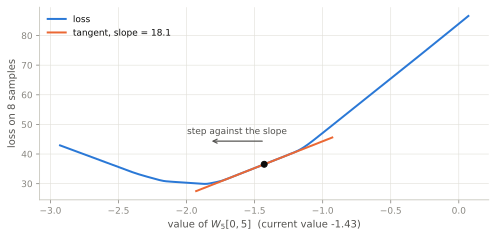

In [59]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Loss on 8 samples plotted against the value of one output-layer weight. The curve is convex, made of nearly straight pieces joined by smooth bends. An orange tangent line touches it at the current value, and an arrow above the point shows a step to the left, against the slope."
# plot helper: the loss along one weight of W_5 (the one with the steepest slope), and its tangent (eq. 12)
W5 = nn_weights[5].weights
slopes = numerical_grad(lambda w_: loss_with(5, w_), W5)
i, j = np.unravel_index(np.abs(slopes).argmax(), W5.shape)
w0, slope, L0 = W5[i, j], slopes[i, j], loss_with(5, W5)

def W5_with(v):
    w_ = W5.copy(); w_[i, j] = v
    return w_

vs = w0 + np.linspace(-1.5, 1.5, 301)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(vs, [loss_with(5, W5_with(v)) for v in vs], color=SERIES[0], lw=2, label="loss")
tv = w0 + np.linspace(-0.5, 0.5, 2)
ax.plot(tv, L0 + slope * (tv - w0), color=SERIES[1], lw=2, label=f"tangent, slope = {slope:.1f}")
ax.plot([w0], [L0], "o", color=INK, ms=6, zorder=3)
step = -0.4 * np.sign(slope)                                       # a step against the slope
y_arrow = L0 + 0.12 * (ax.get_ylim()[1] - ax.get_ylim()[0])
ax.annotate("", xy=(w0 + step, y_arrow), xytext=(w0, y_arrow),
            arrowprops=dict(arrowstyle="->", color=INK_2, lw=1.2))
ax.annotate("step against the slope", (w0 + step / 2, y_arrow), xytext=(0, 5), textcoords="offset points",
            color=INK_2, fontsize=9, ha="center", va="bottom")
ax.set_xlabel(f"value of $W_5[{i},{j}]$  (current value {w0:.2f})")
ax.set_ylabel("loss on 8 samples")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

*Figure 4: The loss as one weight of the output layer moves while the other 2,962 stay fixed. The tangent at the current value has the slope given by equation (13), and stepping against that slope lowers the loss. Along this weight the curve is convex, because the logits are linear in it and cross-entropy is convex in the logits. Its bends are where the most likely class of one of the 8 samples changes.*
{.caption}

### The chain rule

The loss depends on a weight in layer 1 only *through* everything after it: $W_1 \to Z_1 \to A_1 \to Z_2 \to \cdots \to Z_5 \to L$. The chain rule tells us how to differentiate through such a chain.

**One path.** If $L = f(v)$ and $v = g(u)$, then $\dfrac{dL}{du} = \dfrac{dL}{dv}\,\dfrac{dv}{du}$.

**Many paths.** If $u$ affects $L$ through several intermediate variables $v_1,\dots,v_m$, we add up the contribution of each path:

$$\frac{\partial L}{\partial u} = \sum_{k=1}^{m}\frac{\partial L}{\partial v_k}\,\frac{\partial v_k}{\partial u}.\tag{14}$$

We can imagine this as a *computational graph*. Take $e = (a + b)(b + 1)$ with intermediate nodes $c = a + b$ and $d = b + 1$, and label each edge with its local derivative:

<img src="https://colah.github.io/posts/2015-08-Backprop/img/tree-eval-derivs.png" alt="Computational graph for e = (a + b)(b + 1) with a = 2 and b = 1. Nodes a = 2 and b = 1 feed c = a + b = 3 and d = b + 1 = 2, which feed e = c times d = 6. Edge labels: dc/da = 1, dc/db = 1, dd/db = 1, de/dc = 2, de/dd = 3." width="560">

*Figure 5: A computational graph with the local derivative on each edge. Source: [Olah (2015)](https://colah.github.io/posts/2015-08-Backprop/).*
{.caption}

With $a = 2$ and $b = 1$: $c = 3$, $d = 2$, $e = 6$. The input $b$ reaches $e$ along two paths, through $c$ and through $d$, so by equation (14):

$$\frac{\partial e}{\partial b} = \underbrace{\frac{\partial e}{\partial c}\,\frac{\partial c}{\partial b}}_{d\,\cdot\,1\;=\;2} + \underbrace{\frac{\partial e}{\partial d}\,\frac{\partial d}{\partial b}}_{c\,\cdot\,1\;=\;3} = 5.$$

**Reverse mode: why "back"-propagation.** We could start at an input and push derivatives *forward* (forward-mode differentiation), but each forward sweep gives the derivative of every node with respect to *one* input, so we would need 2,963 sweeps, one per parameter. Starting at the loss and moving *backward* (reverse mode) gives the derivative of *one* output with respect to *every* node in a single sweep. A loss is one number and the parameters are many, so reverse mode wins by a factor of the number of parameters.

<img src="https://colah.github.io/posts/2015-08-Backprop/img/tree-backprop.png" alt="The same graph traversed in reverse. Starting from de/de = 1 at the top, multiplying by edge derivatives gives de/dc = 2 and de/dd = 3, then de/da = 2 and de/db = 2 + 3 = 5 at the inputs." width="560">

*Figure 6: Reverse mode starts at the output with $\partial e/\partial e = 1$ and moves backward, multiplying by each edge's local derivative and summing where paths meet. One sweep gives the derivative of $e$ with respect to every node. Source: [Olah (2015)](https://colah.github.io/posts/2015-08-Backprop/).*
{.caption}

**The pattern every layer follows.** In a network, each node is a whole layer or operation. The backward pass hands each one the gradient of the loss with respect to its *output*, the **upstream gradient**. The node multiplies it by its own **local** derivative and passes the result on as the gradient with respect to its *input*:

$$\underbrace{\frac{\partial L}{\partial\,\text{input}}}_{\text{passed back}} = \underbrace{\frac{\partial L}{\partial\,\text{output}}}_{\text{upstream: } \texttt{grad\_out}}\cdot\underbrace{\frac{\partial\,\text{output}}{\partial\,\text{input}}}_{\text{local}}.\tag{15}$$

That is exactly the signature of every backward function below, such as `relu_backward(grad_out, x)`, `softmax_backward(grad_out, out=...)` and `cross_entropy_backward(grad_out, x, label)`. Each receives `grad_out`, applies its local derivative, and returns the gradient for its input. For each one we derive the local derivative element by element, write the code, and check it against equation (13).

### ReLU

From equation (4), $\mathrm{ReLU}(z) = z$ when $z \gt 0$ and $0$ when $z \lt 0$, so

$$\frac{\partial\,\mathrm{ReLU}(z)}{\partial z} = \mathbb{1}\{z \gt 0\}.\tag{16}$$

At exactly $z = 0$ there is a kink and no derivative. We use 0 there, one of the valid *subgradients*, and in practice it almost never matters. ReLU acts element by element, so by equation (15) the backward pass is an element-wise product, $dZ = dA\odot\mathbb{1}\{Z \gt 0\}$. In words: the gradient passes through where the unit was active and is blocked where it was not.

In [60]:
np.where(d > 0, 1, 0)

array([1, 0, 1, 1, 0])

In [61]:
def relu_backward(grad_out, x, out=None):
    grad = np.where(x > 0, 1, 0)
    grad = grad * grad_out
    return grad
    

In [ ]:
# finite-difference check of relu_backward (eq. 16). L = sum(relu(x) * G), so dL/dx = relu_backward(G, x)
rng = np.random.default_rng(0)
x_t, G = rng.normal(size=(4, 5)), rng.normal(size=(4, 5))
err = rel_error(relu_backward(G, x_t), numerical_grad(lambda x_: (relu(x_) * G).sum(), x_t))
print(f"relu_backward: max relative error vs finite differences = {err:.1e}")
assert err < 1e-6

relu_backward: max relative error vs finite differences = 1.7e-10


### Linear layer

Start with one sample and one weight. From equation (1), $z_i = \sum_j W_{ij}x_j + b_i$. Write $\delta_i = \partial L/\partial z_i$ for the upstream gradient (the *error signal*, `dz` in the code).

**Weights.** $W_{ij}$ appears in only one output, $z_i$, with coefficient $x_j$. So $\partial z_k/\partial W_{ij} = x_j$ if $k = i$ and 0 otherwise, and only one path in equation (14) survives:

$$\frac{\partial L}{\partial W_{ij}} = \sum_k\frac{\partial L}{\partial z_k}\,\frac{\partial z_k}{\partial W_{ij}} = \delta_i\,x_j.$$

Collecting all $(i, j)$ gives an outer product, $\partial L/\partial W = \delta\,x^\top$, with shape $(n_{out}, n_{in})$, the same as $W$.

**Bias.** $\partial z_k/\partial b_i = \mathbb{1}\{k = i\}$, so $\partial L/\partial b_i = \delta_i$.

**Input.** Every output depends on $x_j$, through $W_{ij}$, so every path counts:

$$\frac{\partial L}{\partial x_j} = \sum_i\frac{\partial L}{\partial z_i}\,\frac{\partial z_i}{\partial x_j} = \sum_i \delta_i\,W_{ij},\qquad\text{i.e.}\qquad \frac{\partial L}{\partial x} = W^\top\delta.$$

**The batch.** All $B$ samples use the same $W$ and $b$, so their gradients add up over the batch: by equation (14), each sample is one more path. Stacking the per-sample $\delta_n^\top$ as the rows of $dZ\in\mathbb{R}^{B\times n_{out}}$:

$$dW = \sum_{n=1}^{B}\delta_n x_n^\top = dZ^\top X,\tag{17}$$

$$db = \sum_{n=1}^{B}\delta_n = \mathbf{1}^\top dZ\quad\text{(sum over the rows)},\tag{18}$$

$$dX = dZ\,W\quad\text{(row } n \text{ is } (W^\top\delta_n)^\top = \delta_n^\top W\text{)}.\tag{19}$$

**Shape check.** A gradient always has the shape of the thing it differentiates, and that usually leaves only one way to multiply the available matrices. $dW$ must be $(n_{out}, n_{in})$; the only product of $dZ$ $(B, n_{out})$ and $X$ $(B, n_{in})$ with that shape is $dZ^\top X$.

The same two results, $\partial L/\partial W = \delta\otimes x$ and $\delta_{\text{prev}} = W^\top\delta$, appear in J. Rosser's diagram of the backward pass through two linear layers:

<img src="https://jrosser.co.uk/knowledge_base/_images/mlp_backward.png" alt="Backward pass through two linear layers x to a0 = W0 x to a1 = W1 a0 to a scalar loss L with target y. Red arrows run right to left: delta1 = a1 - y, delta0 = W1 transpose delta1, dL/dx = W0 transpose delta0, and upward arrows give dL/dW1 = delta1 outer a0 and dL/dW0 = delta0 outer x. Boxes at the bottom note which values PyTorch hooks capture." width="560">

*Figure 7: Each weight gradient is the outer product of the layer's error signal and its input (equation 17), and the error signal is passed back through the transposed weights (equation 19). The "hooks" boxes refer to PyTorch's hook mechanism, which the source post explains. Source: [J. Rosser, "Forward, backward, and hooks in PyTorch"](https://jrosser.co.uk/knowledge_base/content/ml/hooks_explainer.html).*
{.caption}

**Worked example.** Take the 2→2 layer from before, with $X = \begin{bmatrix}3 & -1\\ 0 & 2\end{bmatrix}$ and an upstream gradient $dZ = \begin{bmatrix}1 & -1\\ 2 & 0\end{bmatrix}$:

$$dW = dZ^\top X = \begin{bmatrix}1 & 2\\ -1 & 0\end{bmatrix}\begin{bmatrix}3 & -1\\ 0 & 2\end{bmatrix} = \begin{bmatrix}3 & 3\\ -3 & 1\end{bmatrix},\qquad db = [3,\ -1].$$

`linear_backward` returns $dW$ and $db$. Equation (19), the gradient handed to the previous layer, appears directly in the backward loop further down.

In [63]:
def linear_backward(dz, a_prev):
    # z = a_prev @ W.T + b  →  dW = dz.T @ a_prev,  db = Σ_batch dz
    dw = np.matmul(np.transpose(dz), a_prev)   # (n_out, n_in), same shape as W
    db = dz.sum(axis=0)                        # (n_out,)
    return dw, db

In [ ]:
# the worked example (expect dW = [[3, 3], [-3, 1]], db = [3, -1]), then finite-difference checks of eqs. (17)-(19)
dZ_ex = np.array([[1.0, -1.0], [2.0, 0.0]])
dW_ex, db_ex = linear_backward(dZ_ex, X_ex)
print("dW =", dW_ex.tolist(), "  db =", db_ex.tolist())

rng = np.random.default_rng(1)
Xt, Wt, bt, G = rng.normal(size=(6, 4)), rng.normal(size=(3, 4)), rng.normal(size=3), rng.normal(size=(6, 3))
dW, db = linear_backward(G, Xt)
errs = {
    "dW (17)": rel_error(dW, numerical_grad(lambda w_: (linear(Xt, w_, bt) * G).sum(), Wt)),
    "db (18)": rel_error(db, numerical_grad(lambda b_: (linear(Xt, Wt, b_) * G).sum(), bt)),
    "dX (19)": rel_error(G @ Wt, numerical_grad(lambda x_: (linear(x_, Wt, bt) * G).sum(), Xt)),
}
for k, v in errs.items():
    print(f"{k}: max relative error vs finite differences = {v:.1e}")
assert max(errs.values()) < 1e-6

dW = [[3.0, 3.0], [-3.0, 1.0]]   db = [3.0, -1.0]
dW (17): max relative error vs finite differences = 3.6e-10
db (18): max relative error vs finite differences = 2.5e-10
dX (19): max relative error vs finite differences = 2.2e-10


### Softmax

Softmax is not element-wise: every $p_i$ depends on every logit $z_k$ through the shared denominator $S = \sum_j e^{z_j}$. Its derivative is therefore a full $C\times C$ matrix, the **Jacobian** $J_{ik} = \partial p_i/\partial z_k$. We apply the quotient rule to $p_i = e^{z_i}/S$, using $\partial S/\partial z_k = e^{z_k}$.

**Case $i = k$**, a logit's effect on its own probability:

$$\frac{\partial p_i}{\partial z_i} = \frac{e^{z_i}S - e^{z_i}e^{z_i}}{S^2} = \frac{e^{z_i}}{S}\Big(1 - \frac{e^{z_i}}{S}\Big) = p_i(1 - p_i).$$

**Case $i \neq k$**, another logit's effect (the numerator $e^{z_i}$ does not contain $z_k$):

$$\frac{\partial p_i}{\partial z_k} = \frac{0\cdot S - e^{z_i}e^{z_k}}{S^2} = -p_i\,p_k.$$

Both cases in one formula, with the indicator $\mathbb{1}\{i = k\}$ (often written as the Kronecker delta $\delta_{ik}$):

$$J_{ik} = \frac{\partial p_i}{\partial z_k} = p_i\big(\mathbb{1}\{i = k\} - p_k\big),\qquad J = \mathrm{diag}(p) - pp^\top.\tag{20}$$

The diagonal is positive (raising a logit raises its own probability) and the off-diagonal entries are negative (raising it takes probability from every other class). By equation (14), the gradient for each logit sums over all the probabilities it affects:

$$\frac{\partial L}{\partial z_k} = \sum_i\frac{\partial L}{\partial p_i}\,J_{ik},\qquad\text{i.e.}\qquad \frac{\partial L}{\partial z} = J^\top\frac{\partial L}{\partial p}.\tag{21}$$

($J$ is symmetric, so $J^\top = J$.)

**Worked example.** For $p = [0.659,\ 0.242,\ 0.099]$: $J_{00} = 0.659\times0.341 = 0.225$ and $J_{01} = -0.659\times0.242 = -0.160$.

On the 5-logit vector `d` from earlier, first the outer product $pp^\top$, then $J$:

In [65]:
d_softmax = softmax(d); d_softmax

array([0.14115312, 0.00958733, 0.34423118, 0.50347824, 0.00155013])

In [66]:
np.matmul(np.expand_dims(d_softmax, axis=-1), np.expand_dims(d_softmax, axis=0)).shape

(5, 5)

In [67]:
J = d_softmax[:, None] * np.eye(d_softmax.shape[0]) - np.matmul(d_softmax[:, None], d_softmax[None, :]); J

array([[ 1.21228913e-01, -1.35328206e-03, -4.85893028e-02,
        -7.10675222e-02, -2.18806092e-04],
       [-1.35328206e-03,  9.49541702e-03, -3.30025926e-03,
        -4.82701406e-03, -1.48616421e-05],
       [-4.85893028e-02, -3.30025926e-03,  2.25736074e-01,
        -1.73312907e-01, -5.33604081e-04],
       [-7.10675222e-02, -4.82701406e-03, -1.73312907e-01,
         2.49987902e-01, -7.80458201e-04],
       [-2.18806092e-04, -1.48616421e-05, -5.33604081e-04,
        -7.80458201e-04,  1.54773002e-03]])

Each column of $J$ sums to (numerically) zero:

In [68]:
grad = J.sum(axis=0); grad

array([-8.91756287e-18, -3.30342849e-19, -4.03323208e-17, -3.68628739e-17,
        0.00000000e+00])

That is no accident. The probabilities always sum to 1, so $\sum_i \partial p_i/\partial z_k = \partial(\sum_i p_i)/\partial z_k = \partial(1)/\partial z_k = 0$: nudging one logit only moves probability around and never creates it. (Each row sums to zero as well; that is the shift-invariance of equation (8). Raising every logit by the same amount changes nothing.)

For a batch, `softmax_backward` builds one $C\times C$ Jacobian per sample, an array of shape $(B, C, C)$, and applies equation (21):

In [69]:
def softmax_backward(grad_out, x=None, out=None):
    B, S = out.shape
    J = out[:, :, None] * np.eye(S) - np.matmul(out[:, :, None], out[:, None, :])
    grad = J * grad_out[:, :, None]
    grad = grad.sum(axis=1)
    return grad

In [ ]:
# J for the worked example (eq. 20), then a finite-difference check of eq. (21)
p_ex = softmax(np.array([2.0, 1.0, 0.1]))
print("J =\n", (np.diag(p_ex) - np.outer(p_ex, p_ex)).round(3))

rng = np.random.default_rng(2)
zt, G = rng.normal(size=(4, 3)), rng.normal(size=(4, 3))
err = rel_error(softmax_backward(G, out=softmax(zt)), numerical_grad(lambda z_: (softmax(z_) * G).sum(), zt))
print(f"softmax_backward: max relative error vs finite differences = {err:.1e}")
assert err < 1e-6

J =
 [[ 0.225 -0.16  -0.065]
 [-0.16   0.184 -0.024]
 [-0.065 -0.024  0.089]]
softmax_backward: max relative error vs finite differences = 1.4e-10


### Cross-entropy, through log-softmax

Now the gradient of the loss with respect to the logits. Take one sample with one-hot label $y$, so $L = -\sum_i y_i\log p_i$. Equation (10) gives $\log p_i = z_i - \log\sum_j e^{z_j}$ (the shift by $m$ cancels, so we can drop it). Differentiate with respect to $z_k$, one term at a time:

- $\dfrac{\partial z_i}{\partial z_k} = \mathbb{1}\{i = k\}$;
- $\dfrac{\partial}{\partial z_k}\log\sum_j e^{z_j} = \dfrac{e^{z_k}}{\sum_j e^{z_j}} = p_k$.

So $\dfrac{\partial\log p_i}{\partial z_k} = \mathbb{1}\{i = k\} - p_k$, and

$$\begin{aligned} \frac{\partial L}{\partial z_k} &= -\sum_i y_i\big(\mathbb{1}\{i = k\} - p_k\big) \\ &= -\underbrace{\sum_i y_i\,\mathbb{1}\{i = k\}}_{=\,y_k} + p_k\underbrace{\sum_i y_i}_{=\,1} \\ &= p_k - y_k. \end{aligned}$$

The indicator *sifts* out the single term $i = k$, and a one-hot label sums to 1. With the batch mean of equation (9), each sample's loss carries a factor $1/B$:

$$\boxed{\frac{\partial L}{\partial Z} = \frac{1}{B}\,(P - Y)}\tag{22}$$

where $P$ stacks the probabilities and $Y$ the one-hot labels, both of shape $(B, C)$.

**What it means.** For a wrong class the gradient is $+p_k/B$, so gradient descent lowers that logit in proportion to the probability it took. For the true class it is $(p_k - 1)/B \lt 0$, so descent raises that logit, harder the further $p_k$ is from 1. When the prediction is perfect, $P = Y$, the gradient is zero. Every entry lies in $[-1/B,\ 1/B]$, however extreme the logits are.

**Worked example.** For $z = [2,\ 1,\ 0.1]$ with true class 0 and $B = 1$: $p - y = [0.659 - 1,\ 0.242,\ 0.099] = [-0.341,\ 0.242,\ 0.099]$.

In the code, `probs[np.arange(B), label] -= 1` subtracts the one-hot $Y$ without ever building it, and `/ B` is the batch mean.

In [71]:
def cross_entropy_backward(grad_out, x, label, out=None):
    B = x.shape[0]
    x = x - x.max(axis=-1, keepdims=True)
    probs = np.exp(x) / np.exp(x).sum(axis=-1, keepdims=True)   # B,L
    probs[np.arange(B), label] -= 1    # p-1 for correct label and p for incorrect label
    return (probs / B) * grad_out   # split the gradient across batch

In [ ]:
# the worked example (expect [-0.341, 0.242, 0.099]), then a finite-difference check of eq. (22)
print("p - y =", cross_entropy_backward(1.0, np.array([[2.0, 1.0, 0.1]]), np.array([0])).round(3))

rng = np.random.default_rng(3)
zt, yt = rng.normal(size=(8, 3)) * 3, rng.integers(0, 3, size=8)
err = rel_error(cross_entropy_backward(1.0, zt, yt), numerical_grad(lambda z_: cross_entropy(z_, yt), zt))
print(f"cross_entropy_backward: max relative error vs finite differences = {err:.1e}")
assert err < 1e-6

p - y = [[-0.341  0.242  0.099]]
cross_entropy_backward: max relative error vs finite differences = 1.3e-09


On our network's logits from the forward pass (8 samples), most rows are $\pm 1/8 = \pm 0.125$. The network puts all its probability on one class: where that class is wrong the gradient is as large as it can be, and rows near zero are samples it already gets right.

In [73]:
cross_entropy_backward(np.array([1]), nn_layer_out[len(layers)].z, train_Y[:8])

array([[ 1.25000000e-01,  7.63783537e-26, -1.25000000e-01],
       [-1.24989365e-01,  1.51858967e-62,  1.24989365e-01],
       [ 1.25000000e-01,  6.25767745e-38, -1.25000000e-01],
       [ 1.23873310e-06,  8.22658110e-25, -1.23873310e-06],
       [ 5.28039144e-08, -1.25000000e-01,  1.24999947e-01],
       [-1.24999969e-01,  1.83761540e-32,  1.24999969e-01],
       [-3.00303671e-11,  1.78303870e-27,  3.00303720e-11],
       [ 1.25000000e-01,  6.08741632e-20, -1.25000000e-01]])

**Why not squared error?** Now we can prove the earlier claim. Take $L_{\text{MSE}} = \tfrac12\sum_i(p_i - y_i)^2$, so $\partial L/\partial p = p - y$, and by equation (21) its gradient with respect to the logits is $J^\top(p - y)$. Suppose the model is confidently wrong, with nearly all probability on a wrong class $j$, so $p \approx e_j$ (one-hot at $j$). Then

$$J = \mathrm{diag}(p) - pp^\top \approx \mathrm{diag}(e_j) - e_je_j^\top = 0.$$

The Jacobian itself vanishes, so the squared-error gradient goes to zero even though the prediction is as wrong as it can be. Cross-entropy's gradient $p - y \approx e_j - y$ stays at full size. Below, one sample with true class 0 and logits $[s,\ -s,\ 0]$ is swept from confidently wrong ($s = -8$) to confidently right ($s = 8$); both gradients are computed with the backward functions above.

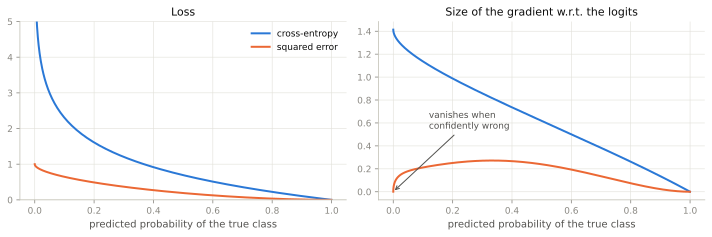

In [74]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Two panels against the predicted probability of the true class, from 0 to 1. Left: cross-entropy loss rises steeply toward the left while squared error stays below 1. Right: gradient size with respect to the logits; cross-entropy's gradient is largest (about 1.4) when the true class has probability near 0, while squared error's gradient falls to 0 there."
# plot helper: one sample, true class 0, logits z = [s, -s, 0] for s from -8 to 8
s_vals = np.linspace(-8, 8, 400)
y0, onehot = np.array([0]), np.array([[1.0, 0.0, 0.0]])
rows = []
for s in s_vals:
    zs = np.array([[s, -s, 0.0]])
    ps = softmax(zs)
    rows.append((ps[0, 0],
                 cross_entropy(zs, y0), 0.5 * ((ps - onehot) ** 2).sum(),
                 np.linalg.norm(cross_entropy_backward(1.0, zs, y0)),               # eq. (22)
                 np.linalg.norm(softmax_backward(ps - onehot, out=ps))))            # eq. (21) with dL/dp = p - y
p_true, ce_l, mse_l, ce_g, mse_g = np.array(rows).T

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
ax1.plot(p_true, ce_l, color=SERIES[0], label="cross-entropy")
ax1.plot(p_true, mse_l, color=SERIES[1], label="squared error")
ax1.set_ylim(0, 5); ax1.set_title("Loss")
ax2.plot(p_true, ce_g, color=SERIES[0], label="cross-entropy")
ax2.plot(p_true, mse_g, color=SERIES[1], label="squared error")
ax2.set_title("Size of the gradient w.r.t. the logits")
ax2.annotate("vanishes when\nconfidently wrong", xy=(p_true[5], mse_g[5]), xytext=(0.12, 0.55),
             arrowprops=dict(arrowstyle="->", color=INK_2, lw=1), color=INK_2, fontsize=9)
for ax in (ax1, ax2):
    ax.set_xlabel("predicted probability of the true class")
ax1.legend(loc="upper right")
fig.tight_layout()
plt.show()

*Figure 8: One sample, swept from confidently wrong (left) to confidently right (right). Left: cross-entropy grows without bound for confident mistakes, while squared error stays below 1. Right: the size of the gradient with respect to the logits. Squared error's gradient fades to zero for confident mistakes, so the model barely learns from them; cross-entropy's is largest exactly there.*
{.caption}

### The softmax bottleneck

There are two ways to get $\partial L/\partial Z$ for cross-entropy:

- **Path A, separate:** compute $P = \mathrm{softmax}(Z)$, then $L = -\frac1B\sum_n\log p_{n,y_n}$. Backward: $\partial L/\partial p_{n,y_n} = -1/(B\,p_{n,y_n})$, then multiply by the softmax Jacobian, equation (21).
- **Path B, fused:** compute $\log P$ directly with log-softmax, equation (10), and pick out the true-class entries. Backward: equation (22), $(P - Y)/B$.

On paper they agree. In Path A, the $1/p$ from the log cancels the factor $p_i$ in the Jacobian:

$$\sum_i\Big(-\frac{y_i}{p_i}\Big)\,p_i\big(\mathbb{1}\{i = k\} - p_k\big) = p_k - y_k.$$

In floating point, that cancellation only works if $p$ has not already underflowed to 0. Path A computes $1/p$ first and multiplies by $p$ afterwards; once $p = 0$, that is $\infty\times 0 =$ `nan`. Below, both paths run on logits of growing scale, with the lowest logit on the true class so that the model is confidently wrong.

In [ ]:
# Path A (softmax -> log, backward through the Jacobian) vs Path B (fused, eq. 22)
def path_a(z, y):
    B = z.shape[0]
    p = softmax(z)                                               # plain softmax, no max-shift
    loss = -np.log(p[np.arange(B), y]).mean()
    dL_dp = np.zeros_like(p)
    dL_dp[np.arange(B), y] = -1.0 / (B * p[np.arange(B), y])     # d(-log p)/dp = -1/p
    return loss, softmax_backward(dL_dp, out=p)                  # eq. (21)

def path_b(z, y):
    return cross_entropy(z, y), cross_entropy_backward(1.0, z, y)

base, y_t = np.array([[1.0, -0.5, 0.2]]), np.array([1])          # true class has the lowest logit
print(f"{'scale':>6} | {'A: loss':>9} {'A: |grad|':>10} | {'B: loss':>9} {'B: |grad|':>10}")
with np.errstate(all="ignore"):
    for scale in [1, 10, 100, 500, 1000]:
        (la, ga), (lb, gb) = path_a(base * scale, y_t), path_b(base * scale, y_t)
        print(f"{scale:>6} | {la:>9.4g} {np.linalg.norm(ga):>10.4g} | {lb:>9.4g} {np.linalg.norm(gb):>10.4g}")

 scale |   A: loss  A: |grad| |   B: loss  B: |grad|
     1 |     2.014      1.087 |     2.014      1.087
    10 |        15      1.414 |        15      1.414
   100 |       150      1.414 |       150      1.414
   500 |       inf        nan |       750      1.414
  1000 |       inf        nan |      1500      1.414


Both paths agree up to a scale of 100. At 500, $p_{y}$ underflows to 0, so Path A's loss becomes `inf` and its gradient `nan` ($\infty\times0$). At 1000, $e^{1000}$ overflows inside softmax as well. Path B stays finite and exact. Its loss is essentially $z_{\max} - z_y$ (at scale 500: $500 - (-250) = 750$), and its gradient norm settles at $\sqrt{2}\approx 1.414$, because $p - y \approx [1,\ -1,\ 0]$.

**The compute bottleneck.** Path A also builds a full $C\times C$ Jacobian for every sample, which costs $O(BC^2)$ time and memory. Path B needs one subtraction per entry, $O(BC)$. For our 3 classes that makes no difference. For a language model with a 50,000-token vocabulary, a single sample's Jacobian would hold $2.5\times10^{9}$ entries (20 GB in `float64`). This is why PyTorch's [`F.cross_entropy`](https://pytorch.org/docs/stable/generated/torch.nn.functional.cross_entropy.html) takes raw logits and fuses log-softmax with the negative log-likelihood.

In [ ]:
# time both backward passes as the number of classes C grows (batch of 64, best of 3 runs)
import time

def best_time(fn, repeats=3):
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); times.append(time.perf_counter() - t0)
    return min(times)

rng = np.random.default_rng(4)
for C in [10, 100, 500]:
    z_c, y_c, g_c = rng.normal(size=(64, C)), rng.integers(0, C, size=64), rng.normal(size=(64, C))
    p_c = softmax(z_c)
    t_a = best_time(lambda: softmax_backward(g_c, out=p_c))
    t_b = best_time(lambda: cross_entropy_backward(1.0, z_c, y_c))
    print(f"C = {C:>3}:  Jacobian path {t_a * 1e3:8.2f} ms   fused path {t_b * 1e3:6.3f} ms   ({t_a / t_b:,.0f}x slower)")

C =  10:  Jacobian path     0.03 ms   fused path  0.012 ms   (2x slower)


C = 100:  Jacobian path     1.10 ms   fused path  0.044 ms   (25x slower)


C = 500:  Jacobian path    29.43 ms   fused path  0.178 ms   (166x slower)


### The backward pass in matrix form

Now we chain the pieces, from the loss back to layer 1.

**Output layer** ($l = 5$), from equation (22):

$$dZ_5 = \frac{1}{B}\,(P - Y).\tag{23}$$

**Every layer** $l$, from equations (17) and (18), with $A_{l-1}$ as the layer's input:

$$dW_l = dZ_l^\top A_{l-1},\qquad db_l = \mathbf{1}^\top dZ_l.\tag{24}$$

**Passing back to layer $l - 1$.** Equation (19) gives the gradient for the layer's input, and the ReLU rule (16) gates it:

$$dA_{l-1} = dZ_l\,W_l,\tag{25}$$

$$dZ_{l-1} = dA_{l-1}\odot\mathbb{1}\{Z_{l-1} \gt 0\}.\tag{26}$$

That is three matrix products per layer. Note that equation (25) uses $W_l$, the weights of the layer *above*: the gradient for layer $l - 1$ is routed back through the same weights the forward pass used.

**Shapes** for our batch of $B = 8$:

| $l$ | $W_l$ and $dW_l$ | $A_{l-1}$ (layer input) | $Z_l$ and $dZ_l$ |
|---|---|---|---|
| 5 | `(3, 8)` | `(8, 8)` | `(8, 3)` |
| 4 | `(8, 16)` | `(8, 16)` | `(8, 8)` |
| 3 | `(16, 32)` | `(8, 32)` | `(8, 16)` |
| 2 | `(32, 64)` | `(8, 64)` | `(8, 32)` |
| 1 | `(64, 2)` | `(8, 2)` | `(8, 64)` |

**Equation → code.** The loop below runs `l_i` from 5 down to 1:

| Equation | Code |
|---|---|
| (23) | `dz = cross_entropy_backward(1.0, z, y)` |
| (25) | `d_act = np.matmul(nn_layer_grad[l_i + 1].dz, W_next)`, where `W_next` is $W_{l+1}$, so this is equation (25) one layer up |
| (26) | `dz = relu_backward(d_act, z)` |
| (24) | `dw, db = linear_backward(dz, a_prev)`, where `a_prev` is $A_{l-1}$ |

`LayerGrad` stores $dW_l$, $db_l$, $dZ_l$ and $dA_l$ for every layer. The loop only *computes* gradients. Updating the weights is the optimiser's job, and it has to wait until every gradient exists; the next section explains why.

In [77]:
class LayerGrad:
    def __init__(self, dw=np.array([]) , db=np.array([]), dz=np.array([]), d_act=np.array([]), nm=""):
        self.dw = dw
        self.db = db
        self.dz = dz
        self.d_act = d_act
        self.nm = nm

    def __repr__(self):
        return f"LayerGrad: dw -> {self.dw.shape}; db -> {self.db.shape}; dz -> {self.dz.shape}; d_act -> {self.d_act.shape}; type -> {self.nm}"


In [78]:
nn_layer_grad = {}
y = train_Y[:8]
l_i = n_layers

while l_i > 0:
    z = nn_layer_out[l_i].z               # this layer's pre-activation
    a_prev = nn_layer_out[l_i - 1].activation  # input to this layer
    d_act  = np.array([])

    if l_i == n_layers:
        # output layer: loss → logits
        dz = cross_entropy_backward(1.0, z, y)                       # (B, n_out)
    else:
        # hidden layer: next layer's dz → this layer's activation → z
        W_next = nn_weights[l_i + 1].weights                         # (n_next, n_out)
        d_act  = np.matmul(nn_layer_grad[l_i + 1].dz, W_next)        # (B, n_out)
        dz     = relu_backward(d_act, z)                             # (B, n_out)

    dw, db = linear_backward(dz, a_prev)
    nn_layer_grad[l_i] = LayerGrad(dw, db, dz, d_act, nm=f"{l_i}_gradients")

    l_i -= 1


In [79]:
nn_layer_grad

{5: LayerGrad: dw -> (3, 8); db -> (3,); dz -> (8, 3); d_act -> (0,); type -> 5_gradients,
 4: LayerGrad: dw -> (8, 16); db -> (8,); dz -> (8, 8); d_act -> (8, 8); type -> 4_gradients,
 3: LayerGrad: dw -> (16, 32); db -> (16,); dz -> (8, 16); d_act -> (8, 16); type -> 3_gradients,
 2: LayerGrad: dw -> (32, 64); db -> (32,); dz -> (8, 32); d_act -> (8, 32); type -> 2_gradients,
 1: LayerGrad: dw -> (64, 2); db -> (64,); dz -> (8, 64); d_act -> (8, 64); type -> 1_gradients}

**Checking all 2,963 gradients.** The final test runs the whole chain: compare every entry of every $dW_l$ and $db_l$ with equation (13). That takes 5,926 forward passes, which illustrates nicely what backpropagation saves us.

In [ ]:
# finite-difference check (eq. 13) of every weight and bias gradient from the loop above
worst = 0.0
for l_key in range(1, n_layers + 1):
    err_w = rel_error(nn_layer_grad[l_key].dw, numerical_grad(lambda w_: loss_with(l_key, w_, "weights"), nn_weights[l_key].weights))
    err_b = rel_error(nn_layer_grad[l_key].db, numerical_grad(lambda b_: loss_with(l_key, b_, "bias"), nn_bias[l_key].weights))
    worst = max(worst, err_w, err_b)
    print(f"layer {l_key}:  dW max relative error {err_w:.1e}   db max relative error {err_b:.1e}")
assert worst < 1e-6

layer 1:  dW max relative error 1.2e-09   db max relative error 6.2e-10


layer 2:  dW max relative error 1.7e-09   db max relative error 2.9e-09
layer 3:  dW max relative error 5.4e-10   db max relative error 3.8e-09
layer 4:  dW max relative error 1.4e-10   db max relative error 8.2e-09
layer 5:  dW max relative error 3.2e-10   db max relative error 3.9e-09


Every weight and bias gradient matches finite differences to a relative error below $10^{-8}$. The backward pass is correct.

**✓ End of Part 1: Build it.** The network now computes its loss and the gradient of every weight and bias, all checked against finite differences. Part 2 uses those gradients to train it.
{.checkpoint}

---

## Optimiser: Stochastic Gradient Descent

### Gradient descent

Equation (12) told us that $-\nabla_\theta L$ is the steepest way down. **Gradient descent** takes a small step in that direction, recomputes the gradient at the new point, and repeats:

$$\theta \leftarrow \theta - \eta\,\nabla_\theta L.\tag{27}$$

The step size $\eta \gt 0$ is the **learning rate**. Plugging $\Delta = -\eta\nabla L$ into equation (12) shows why this works:

$$L(\theta - \eta\nabla L) \approx L(\theta) - \eta\,\lVert\nabla L\rVert^2 \le L(\theta),$$

so the loss goes down, *as long as $\eta$ is small enough* for the linear approximation to hold.

**How small is small enough?** Take the simplest landscape, a 1-D bowl $L(w) = a\,w^2$ with $a \gt 0$ and its minimum at $w = 0$. The gradient is $2aw$, so equation (27) becomes

$$w_{t+1} = w_t - \eta\cdot 2a\,w_t = (1 - 2\eta a)\,w_t\quad\Longrightarrow\quad w_t = (1 - 2\eta a)^t\,w_0.\tag{28}$$

The iterates shrink to 0 if and only if $\lvert 1 - 2\eta a\rvert \lt 1$, that is, $0 \lt \eta \lt 1/a$:

- $\eta$ small: the factor is just below 1, so progress is slow;
- $\eta = 1/(2a)$: the factor is 0, so we land on the minimum in one step;
- $1/(2a) \lt \eta \lt 1/a$: the factor is negative, so $w$ overshoots and zig-zags but still converges;
- $\eta \gt 1/a$: $\lvert 1 - 2\eta a\rvert \gt 1$, so every step overshoots by more than the last and $w$ diverges.

A steeper bowl (larger $a$, higher curvature) forces a smaller learning rate. A network's landscape has very different curvature in different directions, yet one learning rate must suit them all. That limitation motivates the Adam optimiser, later in this series.

Our parameter update, equation (27) applied to one array at a time:

In [81]:
def sgd(w, grad, lr=0.001):
    w = w - lr * grad
    return w

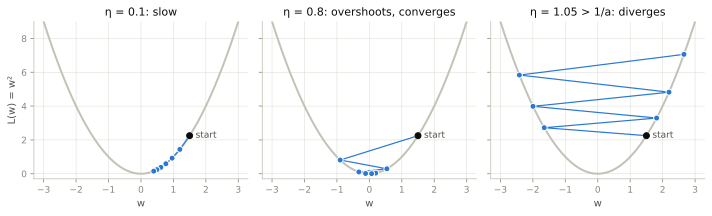

In [82]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Three panels of gradient descent on the parabola L(w) = w squared, starting at w = 1.5. With learning rate 0.1 the points creep slowly down one side; with 0.8 they zig-zag across the bottom and converge; with 1.05 they zig-zag outward and climb the parabola."
# plot helper: gradient descent on L(w) = a w^2 with a = 1 (eq. 28), using sgd() with gradient 2aw
a, w_start, n_steps = 1.0, 1.5, 6
grid = np.linspace(-3.0, 3.0, 300)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.1), sharey=True)
for ax, (lr, title) in zip(axes, [(0.1, "η = 0.1: slow"), (0.8, "η = 0.8: overshoots, converges"),
                                  (1.05, "η = 1.05 > 1/a: diverges")]):
    path = [w_start]
    for _ in range(n_steps):
        path.append(sgd(path[-1], 2 * a * path[-1], lr=lr))
    path = np.array(path)
    ax.plot(grid, a * grid ** 2, color=HAIRLINE, lw=2)
    ax.plot(path, a * path ** 2, "-o", color=SERIES[0], lw=1.2, ms=6, mec="white", mew=1, zorder=3)
    ax.plot(path[:1], a * path[:1] ** 2, "o", color=INK, ms=6, zorder=4)
    ax.annotate("start", (path[0], a * path[0] ** 2), xytext=(6, -2), textcoords="offset points", fontsize=9, color=INK_2)
    ax.set_title(title)
    ax.set_xlabel("w")
axes[0].set_ylabel("L(w) = w²")
axes[0].set_ylim(-0.3, 9)
fig.tight_layout()
plt.show()

*Figure 9: Gradient descent on $L(w) = w^2$ ($a = 1$) from $w_0 = 1.5$, for three learning rates. By equation (28), the iterates converge only when $\eta \lt 1/a = 1$.*
{.caption}

### Stochastic: mini-batches

Our loss is an average over all $N = 720$ training samples, $L(\theta) = \frac1N\sum_{n=1}^{N}\ell_n(\theta)$, where $\ell_n$ is sample $n$'s cross-entropy. So the gradient is an average too, $\nabla L = \frac1N\sum_n\nabla\ell_n$. Computing it exactly needs a pass over the whole dataset for *every* step. That is affordable for 720 points but not for millions.

**Stochastic gradient descent (SGD)** ([Robbins & Monro, 1951](https://doi.org/10.1214/aoms/1177729586); [Bottou, 2010](https://doi.org/10.1007/978-3-7908-2604-3_16)) estimates the gradient from a small random **mini-batch** $\mathcal{B}$ of $B$ samples:

$$\nabla L_{\mathcal{B}} = \frac{1}{B}\sum_{n\in\mathcal{B}}\nabla\ell_n.$$

If every sample is equally likely to land in a given batch slot, each term has expectation $\mathbb{E}[\nabla\ell_n] = \frac1N\sum_m\nabla\ell_m = \nabla L$. By linearity of expectation:

$$\mathbb{E}\big[\nabla L_{\mathcal{B}}\big] = \frac1B\sum_{n\in\mathcal{B}}\mathbb{E}\big[\nabla\ell_n\big] = \nabla L.\tag{29}$$

So the mini-batch gradient is *unbiased*: on average it points the right way. It is noisy, though, with a variance that shrinks roughly like $1/B$, so bigger batches give smoother but more expensive steps. Each step costs $O(B)$ instead of $O(N)$, and in practice many cheap, noisy steps beat a few exact ones ([Bottou, 2010](https://doi.org/10.1007/978-3-7908-2604-3_16)).

**Vocabulary.** A forward pass, backward pass and update on one mini-batch is a **step**. One sweep through all $N$ training samples is an **epoch**. With $N = 720$ and $B = 32$, an epoch is $\lceil 720/32\rceil = 23$ steps, and the last batch holds 16 samples. The data are reshuffled every epoch so the batches differ.

**Update only after the full backward pass.** Equation (25) routes layer $l - 1$'s gradient through $W_l$. If we updated $W_l$ as soon as its own gradient was ready, the layers below would receive gradients computed with weights the forward pass never used, and the result would no longer be the gradient of the loss. So we compute every gradient first, then update all the parameters together.

### One step

The gradients from the backward pass above, applied to every layer once with $\eta = 0.001$, on the same 8 samples:

In [ ]:
# one SGD step (eq. 27) on the 8 samples from the forward pass, after the full backward pass
loss_before = mlp_loss(nn_weights, nn_bias, train_X[:8], train_Y[:8])
for l_key in range(1, n_layers + 1):
    nn_weights[l_key].weights = sgd(nn_weights[l_key].weights, nn_layer_grad[l_key].dw, lr=0.001)
    nn_bias[l_key].weights = sgd(nn_bias[l_key].weights, nn_layer_grad[l_key].db, lr=0.001)
loss_after = mlp_loss(nn_weights, nn_bias, train_X[:8], train_Y[:8])
print(f"loss before: {loss_before:.2f}   after one step: {loss_after:.2f}")

loss before: 36.53   after one step: 21.14


A single step cuts the loss from 36.5 to 21.1. The gradients are large (the logits are large), so even a small learning rate moves the weights a long way.

### Putting it together: the library

Everything so far, refactored into one class. First, `data_iterator` serves shuffled mini-batches:

In [84]:
def data_iterator(data, batch, shuffle=False, rng=None):
    x, y = data
    idx = np.arange(len(x))                 # len(x), not len(data) -> data is the (x, y) tuple
    if shuffle:
        rng = rng if rng is not None else np.random.default_rng(seed=42)
        rng.shuffle(idx)                    # in-place, returns None
    for i in range(0, len(x), batch):
        b_idx = idx[i : i+batch]
        yield x[b_idx], y[b_idx]

In [ ]:
# 10 samples in batches of 4 gives batch sizes 4, 4, 2; a fresh shuffle on every pass
toy = (np.arange(10), np.arange(10))
shared_rng = np.random.default_rng(0)
for epoch in range(2):
    print(f"epoch {epoch}:", [yb.tolist() for _, yb in data_iterator(toy, 4, shuffle=True, rng=shared_rng)])

epoch 0: [[4, 6, 2, 7], [3, 5, 9, 0], [8, 1]]
epoch 1: [[2, 9, 3, 6], [0, 4, 8, 7], [5, 1]]


`NeuralNetwork` bundles the forward pass, backward pass and update. Each method maps to a part of this post:

| Method | What it does | Equations |
|---|---|---|
| `weight_init`, `bias_init` | draw every $W_l$ and $b_l$ from $\mathcal{N}(0, 1)$ | |
| `forward_pass` | linear, then ReLU, for each layer; logits at the end | (2), (4), (11) |
| `backward_pass` | loss gradient, then back through every layer | (23)–(26) |
| `update_parameters` | one SGD step for every layer, after the full backward pass | (27) |
| `train_step` | forward, loss, backward and update on one mini-batch | (9), (27) |
| `train` | loop over epochs and shuffled mini-batches; log train and test loss and accuracy | (29) |
| `evaluate`, `predict` | forward pass only, on a whole set | (9) |

In [86]:
class NeuralNetwork:
    def __init__(self, layers):
        self.layers = layers
        self.n_layers = len(layers)
        self.weights = None
        self.bias = None
        self.lr = None
        self.batch = None


    @staticmethod
    def weight_init(layers, feat_in, mean=0, std=1, seed_factor=42):
        weights = {}
        for l_i in range(len(layers)):
            seed = seed_factor + l_i
            if l_i == 0:
                weights[l_i + 1] =  Parameters(n_in=feat_in, n_out=layers[l_i], mean=mean, std=std, seed=seed)
            else:
                weights[l_i + 1] =  Parameters(n_in=layers[l_i - 1], n_out=layers[l_i], mean=mean, std=std, seed=seed)
        return weights


    @staticmethod
    def bias_init(layers, mean=0, std=1, seed_factor=1042):
        bias = {}
        for l_i in range(len(layers)):
            seed = seed_factor + l_i
            bias[l_i + 1] =  Parameters(n_in=1, n_out=layers[l_i], mean=mean, std=std, seed=seed)
        return bias


    def update_parameters(self, grad):
        # layers are keyed 1..n_layers (0 is the input)
        for l_key in range(1, self.n_layers + 1):
            self.weights[l_key].weights = sgd(self.weights[l_key].weights, grad[l_key].dw, self.lr)
            self.bias[l_key].weights = sgd(self.bias[l_key].weights, grad[l_key].db, self.lr)
        

    def forward_pass(self, x):
        nn_layer_out = {0: LayerOutput(z=x, act=x, nm="input")}
        
        for l_i in range(self.n_layers):
            l_key = l_i + 1
            w = self.weights[l_key].weights
            x = nn_layer_out[l_key - 1].activation
            b = self.bias[l_key].weights
            z = linear(x, w, b)
            if l_key < self.n_layers:
                out = relu(z)
                nn_layer_out[l_key] = LayerOutput(z=z, act=out, nm=f"{l_key}_output")
            else:
                nn_layer_out[l_key] = LayerOutput(z=z, nm=f"{l_key}_output")
        return nn_layer_out


    def backward_pass(self, nn_layer_out, y):
        nn_layer_grad = {}
        l_i = self.n_layers

        while l_i > 0:
            z = nn_layer_out[l_i].z               # this layer's pre-activation
            a_prev = nn_layer_out[l_i - 1].activation  # input to this layer
            d_act  = np.array([])

            if l_i == self.n_layers:
                # output layer: loss → logits
                dz = cross_entropy_backward(1.0, z, y)                       # (B, n_out)
            else:
                # hidden layer: next layer's dz → this layer's activation → z
                W_next = self.weights[l_i + 1].weights                       # (n_next, n_out)
                d_act  = np.matmul(nn_layer_grad[l_i + 1].dz, W_next)        # (B, n_out)
                dz     = relu_backward(d_act, z)                             # (B, n_out)

            dw, db = linear_backward(dz, a_prev)
            nn_layer_grad[l_i] = LayerGrad(dw, db, dz, d_act, nm=f"{l_i}_gradients")
            l_i -= 1
        
        return nn_layer_grad


    def predict(self, x):
        logits = self.forward_pass(x)[self.n_layers].z
        return logits.argmax(axis=-1)


    def evaluate(self, x, y):
        # full-set forward pass, no weight update
        logits = self.forward_pass(x)[self.n_layers].z
        loss = cross_entropy(logits, y)
        acc = (logits.argmax(axis=-1) == y).mean()
        return acc, loss


    def train_step(self, x, y):
        out = self.forward_pass(x)
        logits = out[self.n_layers].z
        loss = cross_entropy(logits, y)
        grad = self.backward_pass(out, y)
        self.update_parameters(grad)
        return logits, loss


    def train(self, train_x, train_y, test_x, test_y, **kwargs):
        self.lr = kwargs.get("lr", 0.001)
        self.batch = kwargs.get("batch_size", 32)
        
        wt_mean = kwargs.get("weights_mean", 0)
        wt_std = kwargs.get("weights_std", 1)
        epochs = kwargs.get("epochs", 5)
        log_every = kwargs.get("log_every", 1)
        rng = np.random.default_rng(kwargs.get("seed", 42))
        feat_in = train_x.shape[-1]
        
        self.weights = self.weight_init(self.layers, feat_in, wt_mean, wt_std)
        self.bias = self.bias_init(self.layers, wt_mean, wt_std)

        history = defaultdict(list)
        for epoch in range(1, epochs + 1):
            epoch_loss, epoch_correct, n_seen = 0.0, 0, 0

            # new generator every epoch (a generator is exhausted after one pass); shared rng -> different shuffle each epoch
            for x, y in data_iterator((train_x, train_y), self.batch, shuffle=True, rng=rng):
                logits, loss = self.train_step(x, y)
                # loss is a batch mean -> weight by batch size so the smaller last batch counts correctly
                epoch_loss += loss * len(y)
                epoch_correct += (logits.argmax(axis=-1) == y).sum()
                n_seen += len(y)

            train_loss, train_acc = epoch_loss / n_seen, epoch_correct / n_seen
            test_acc, test_loss = self.evaluate(test_x, test_y)

            history["train_loss"].append(train_loss)
            history["train_acc"].append(train_acc)
            history["test_loss"].append(test_loss)
            history["test_acc"].append(test_acc)

            if epoch % log_every == 0 or epoch == epochs:
                print(f"epoch {epoch:>4}/{epochs} | train loss {train_loss:.4f} acc {train_acc:.3f} | test loss {test_loss:.4f} acc {test_acc:.3f}")

            if not np.isfinite(train_loss):
                print(f"epoch {epoch}: loss is {train_loss}, stopping")
                break

        return history

### Training for 3 epochs

We train for 3 epochs with learning rate $\eta = 0.01$ and batch size 32, evaluating on the held-out test set after every epoch.

In [87]:
model = NeuralNetwork(layers)
history = model.train(train_X, train_Y, test_X, test_Y, lr=0.01, epochs=3, log_every=1)

epoch    1/3 | train loss 1.9817 acc 0.406 | test loss 1.1202 acc 0.461
epoch    2/3 | train loss 1.1513 acc 0.433 | test loss 1.0434 acc 0.483
epoch    3/3 | train loss 1.0169 acc 0.497 | test loss 0.9054 acc 0.483


The loss goes down every epoch, on both the training and the test set. `train` only logs epoch averages, so to see individual steps we replay the same run (same seeds, so the same batches) and record every mini-batch loss:

In [ ]:
# replay model.train step by step (same init seeds and shuffle seed -> identical run)
replay = NeuralNetwork(layers)
replay.lr, replay.batch = 0.01, 32
replay.weights = replay.weight_init(layers, train_X.shape[-1])
replay.bias = replay.bias_init(layers)
init_acc, init_loss = replay.evaluate(train_X, train_Y)

rng = np.random.default_rng(42)
step_losses = []
for epoch in range(3):
    for xb, yb in data_iterator((train_X, train_Y), replay.batch, shuffle=True, rng=rng):
        step_losses.append(replay.train_step(xb, yb)[1])

print(f"before training: train loss {init_loss:.2f}, accuracy {init_acc:.2f}")
print(f"{len(step_losses)} steps; replay ends with the same weights as model.train:",
      all(np.allclose(replay.weights[k].weights, model.weights[k].weights) for k in model.weights))

before training: train loss 5.29, accuracy 0.35
69 steps; replay ends with the same weights as model.train: True


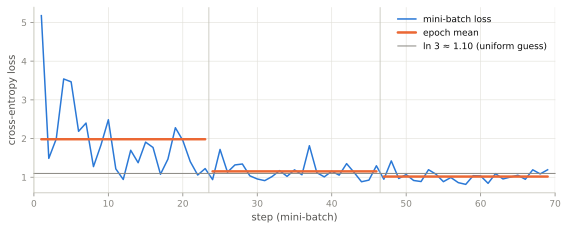

In [89]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Line chart of training loss for each of 69 mini-batch steps over 3 epochs. The loss starts near 5, drops quickly with large jumps, and settles near 1 by the third epoch. Horizontal orange segments mark each epoch's mean loss, falling from 1.98 to 1.15 to 1.02. A grey horizontal line marks ln 3."
# plot helper: per-step loss with epoch means
steps_per_epoch = int(np.ceil(len(train_X) / 32))
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.plot(np.arange(1, len(step_losses) + 1), step_losses, color=SERIES[0], lw=1.5, label="mini-batch loss")
for e, mean_loss in enumerate(history["train_loss"]):
    ax.plot([e * steps_per_epoch + 1, (e + 1) * steps_per_epoch], [mean_loss, mean_loss], color=SERIES[1], lw=2.5,
            label="epoch mean" if e == 0 else None, solid_capstyle="round")
    if e > 0:
        ax.axvline(e * steps_per_epoch + 0.5, color=HAIRLINE, lw=0.8)
ax.axhline(np.log(3), color=MUTED, lw=1, label="ln 3 ≈ 1.10 (uniform guess)")
ax.set_xlabel("step (mini-batch)")
ax.set_ylabel("cross-entropy loss")
ax.set_xlim(0, len(step_losses) + 1)
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

*Figure 10: Training loss on each of the 69 mini-batches (3 epochs of 23 steps), with each epoch's mean. The loss falls but is jagged, because every step sees a different batch (equation 29). The grey line is $\ln 3$, the loss of a uniform guess.*
{.caption}

Finally, what the network has learned: its predicted class at every point of the input plane, with the test points on top.

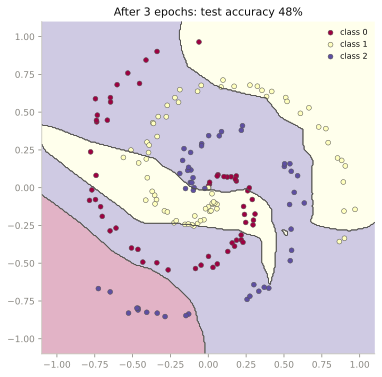

In [90]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Decision regions of the trained network over the square from -1.1 to 1.1, shaded by predicted class, with thin boundary lines and the 180 test points coloured by true class. The plane is split into a few broad, curved regions, mostly class 2, that cut across the spiral arms instead of following them."
# plot helper: decision regions after training, with the test points
g = np.linspace(-1.1, 1.1, 300)
gx, gy = np.meshgrid(g, g)
pred = model.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
test_acc, _ = model.evaluate(test_X, test_Y)

fig, ax = plt.subplots(figsize=(5.4, 5.4))
ax.contourf(gx, gy, pred, levels=[-0.5, 0.5, 1.5, 2.5], colors=CLASS_COLORS, alpha=0.3)
for k in range(3):
    ax.contour(gx, gy, (pred == k).astype(float), levels=[0.5], colors=INK_2, linewidths=0.8)
for k in range(3):
    m = test_Y == k
    ax.scatter(test_X[m, 0], test_X[m, 1], color=CLASS_COLORS[k], s=24, edgecolors=INK_2, linewidths=0.5, label=f"class {k}")
ax.set_aspect("equal")
ax.grid(False)
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
ax.set_title(f"After 3 epochs: test accuracy {test_acc:.0%}")
ax.legend(loc="upper right", fontsize=8, handletextpad=0.2)
fig.tight_layout()
plt.show()

*Figure 11: Decision regions after 3 epochs (shaded by predicted class), with the test points coloured by their true class. The network has carved the plane into a few broad regions that cut across the arms instead of following them.*
{.caption}

### Where we stand

In three epochs the training loss fell from 1.98 to 1.02 and the test loss from 1.12 to 0.91. The machinery works: the forward pass, backpropagation and SGD fit together, and every gradient matches finite differences. But two numbers say we are far from done:

1. **The starting loss is far above $\ln 3 \approx 1.10$**: 36.5 on our 8-sample batch, and 5.29 over the whole training set for the network we just trained. The $\mathcal{N}(0, 1)$ initialisation inflates the pre-activations layer after layer, so the untrained network starts out confidently wrong, with oversized gradients to match.
2. **Test accuracy is under 50%.** That beats chance (33%), but the boundary in Figure 11 is nowhere near a spiral.

The next section, **weight initialisation**, works out how the variance of each layer's output depends on the variance of its weights, and how Kaiming He initialisation keeps the signal at the right scale through every layer.

**✓ End of Part 2: Train it.** You have trained a neural network from scratch. This is a complete story and a good place to stop; Part 3 picks up from here whenever you are ready.
{.checkpoint}

---

## Weight Initialisation

The optimiser section ended with two warning signs: a starting loss of 36.5 where $\ln 3 \approx 1.10$ was expected, and pre-activations whose spread grows from layer to layer. Both trace back to a choice we made without thinking, drawing every weight from $\mathcal{N}(0, 1)$. In this section we push that choice to its extremes, look inside the network to see what breaks, derive the weight variance that keeps the signal stable, and add the fix (Kaiming He initialisation) to the library.

### When initialisation goes wrong

`train` already accepts the mean and standard deviation of the initial weights. Here are two runs that are identical except for that standard deviation: $\sigma = 3$ (weights too large) and $\sigma = 0.01$ (weights too small), each trained for 150 epochs at learning rate 0.01.

In [ ]:
# the same network and training run, with initial weights drawn from N(0, 3^2) and N(0, 0.01^2)
model_big, model_small = NeuralNetwork(layers), NeuralNetwork(layers)
history_big = model_big.train(train_X, train_Y, test_X, test_Y, lr=0.01, epochs=150, log_every=50, weights_std=3)
history_small = model_small.train(train_X, train_Y, test_X, test_Y, lr=0.01, epochs=150, log_every=50, weights_std=0.01)
print(f"first-epoch train loss:  sigma = 3 -> {history_big['train_loss'][0]:.1f},  sigma = 0.01 -> {history_small['train_loss'][0]:.4f}")

epoch   50/150 | train loss 1.1001 acc 0.349 | test loss 1.1037 acc 0.272
epoch  100/150 | train loss 1.0979 acc 0.349 | test loss 1.1054 acc 0.272


epoch  150/150 | train loss 1.0979 acc 0.349 | test loss 1.1054 acc 0.272
epoch   50/150 | train loss 1.0979 acc 0.349 | test loss 1.1051 acc 0.272


epoch  100/150 | train loss 1.0979 acc 0.349 | test loss 1.1055 acc 0.272
epoch  150/150 | train loss 1.0979 acc 0.349 | test loss 1.1054 acc 0.272
first-epoch train loss:  sigma = 3 -> 190.4,  sigma = 0.01 -> 1.0988


In [ ]:
# what the trained networks ended up doing
for name, model in [("sigma = 3", model_big), ("sigma = 0.01", model_small)]:
    out = model.forward_pass(train_X)
    dead = [np.mean((out[l].activation == 0).all(axis=0)) for l in range(1, n_layers)]   # units that are 0 for every input
    print(f"{name:13s} dead ReLU units per hidden layer: {np.round(dead, 2)}   predicted classes on the test set: {np.bincount(model.predict(test_X), minlength=3)}")

sigma = 3     dead ReLU units per hidden layer: [0.28 0.38 0.56 1.  ]   predicted classes on the test set: [  0   0 180]
sigma = 0.01  dead ReLU units per hidden layer: [0.17 0.38 0.5  0.5 ]   predicted classes on the test set: [  0   0 180]


Both runs fail, in opposite ways, and end in the same place:

- **$\sigma = 3$**: the first epoch's loss is about 190, because the logits are enormous and the network is extremely confident about wrong answers. The huge gradients that follow kill most ReLU units (every unit in layer 4 ends up outputting 0 for every input), and the network collapses to a constant output.
- **$\sigma = 0.01$**: the loss starts at $\ln 3$ and never moves.

Both end at a train loss of 1.0979, essentially $\ln 3$, predicting class 2 for every test point. Their test accuracy of 27% is just the fraction of class-2 points in the test set.

To see *why*, we look inside the network at initialisation: the spread of the pre-activations $Z_l$ on the way forward, and of the weight gradients $dW_l$ on the way back, layer by layer.

In [ ]:
# a network with given initial weights (no training), and its per-layer statistics on the training set
def init_model(cls, std=1.0):
    model = cls(layers)
    model.weights = model.weight_init(layers, train_X.shape[-1], 0, std)
    model.bias = model.bias_init(layers, 0, std)
    return model

def layer_stats(model, x, y):
    out = model.forward_pass(x)
    grad = model.backward_pass(out, y)
    act_std = [out[l].z.std() for l in range(1, model.n_layers + 1)]       # spread of Z_l, forward
    grad_std = [grad[l].dw.std() for l in range(1, model.n_layers + 1)]    # spread of dW_l, backward
    return act_std, grad_std

INIT_COLORS = {"N(0, 3²)": SERIES[1], "N(0, 1)": SERIES[0], "N(0, 0.01²)": SERIES[2], "Kaiming": "#eda100"}
for label, std in [("N(0, 3²)", 3.0), ("N(0, 1)", 1.0), ("N(0, 0.01²)", 0.01)]:
    model = init_model(NeuralNetwork, std)
    act_std, grad_std = layer_stats(model, train_X, train_Y)
    loss0 = cross_entropy(model.forward_pass(train_X)[n_layers].z, train_Y)
    print(f"{label:12s} loss {loss0:8.2f} | std of Z_l: {[f'{v:.2g}' for v in act_std]} | std of dW_l: {[f'{v:.2g}' for v in grad_std]}")

N(0, 3²)     loss  1502.96 | std of Z_l: ['3.4', '42', '4.4e+02', '3e+03', '3.2e+03'] | std of dW_l: ['34', '21', '29', '53', '2.5e+02']
N(0, 1)      loss     5.29 | std of Z_l: ['1.1', '4.9', '16', '41', '12'] | std of dW_l: ['0.41', '0.26', '0.43', '0.58', '2.8']
N(0, 0.01²)  loss     1.10 | std of Z_l: ['0.011', '0.011', '0.008', '0.009', '0.0055'] | std of dW_l: ['4e-09', '7.7e-10', '1.1e-08', '6.3e-07', '3.6e-05']


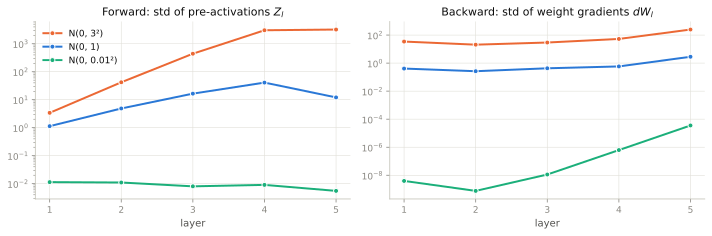

In [94]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Two log-scale line charts over layers 1 to 5. Left, spread of pre-activations: N(0, 9) climbs from about 3 to about 3000, N(0, 1) climbs from about 1 to about 40, N(0, 0.0001) stays flat near 0.01. Right, spread of weight gradients: N(0, 9) is large (20 to 250), N(0, 1) is near 0.3 to 3, N(0, 0.0001) falls from about 4e-5 at layer 5 to about 4e-9 at layer 1."
# plot helper: per-layer spread of Z_l (forward) and dW_l (backward), log scale
def plot_layer_stats(configs):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    for label, model in configs:
        act_std, grad_std = layer_stats(model, train_X, train_Y)
        for ax, vals in [(ax1, act_std), (ax2, grad_std)]:
            ax.plot(range(1, n_layers + 1), vals, "-o", color=INIT_COLORS[label], ms=5, mec="white", label=label)
    ax1.set_title("Forward: std of pre-activations $Z_l$")
    ax2.set_title("Backward: std of weight gradients $dW_l$")
    for ax in (ax1, ax2):
        ax.set_yscale("log"); ax.set_xlabel("layer"); ax.set_xticks(range(1, n_layers + 1))
    ax1.legend(loc="upper left")
    fig.tight_layout()
    plt.show()

plot_layer_stats([(label, init_model(NeuralNetwork, std)) for label, std in [("N(0, 3²)", 3.0), ("N(0, 1)", 1.0), ("N(0, 0.01²)", 0.01)]])

*Figure 12: Inside the network at initialisation, measured on the whole training set. With large weights the forward signal is multiplied up at every layer. With tiny weights the forward signal stays at the scale of the biases, and the gradients shrink by orders of magnitude on their way back to layer 1, so the first layers barely learn.*
{.caption}

### A ten-layer experiment

To isolate the effect, strip the network down: ten $5\times5$ linear layers, no activations and no biases, fed one random input. Each layer's weights come from $\mathcal{N}(0, \sigma^2)$, first with large $\sigma \in \{3, 6, 9\}$, then with small $\sigma \in \{0.1, 0.01, 0.001\}$.

In [95]:
x = get_dummy_inputs(5, seed=1)
wt_config_h = [(0, 3), (0, 6), (0, 9)]
wt_config_l = [(0, 0.1), (0, 0.01), (0, 0.001)]

In [96]:
def dummy_linear(c, x):
    res = []
    out = 0
    for i in range(10):
        w = get_dummy_inputs((5, 5), seed=42+i, mean=c[0], std=c[1])
        out = linear(x, w, b=0)
        x = out
        res.append(out)
    return res

In [97]:
res_h = [dummy_linear(c, x) for c in wt_config_h]


The output of each of the ten layers for $\sigma = 9$:

In [98]:
res_h[-1]

[array([-31.43945135, -10.79899839,  -0.72843489, -13.50715949,
         -3.65210539]),
 array([  44.75184854, -222.9497695 , -181.78803338,  103.86351187,
        -330.38239201]),
 array([-1546.00069173,  4534.89315638,  -729.78392005,  -904.68813391,
         8541.82497858]),
 array([-38226.4974159 ,  56819.8756368 , -94379.48952878,  76669.80483379,
         93340.36880772]),
 array([ 547675.31241125, 1362308.1768409 ,  -31231.81215646,
         965147.16219422,  364077.66217044]),
 array([-23030052.58100493, -17343227.8288478 ,  20867403.69388309,
         19608434.23411275,  26820259.2741052 ]),
 array([ 1.76696571e+08,  3.12196361e+08, -5.91031002e+08,  9.38654717e+07,
         6.59457075e+05]),
 array([ 2.23894287e+09,  7.16272296e+09, -1.23543075e+10,  1.19297324e+09,
         2.42509985e+09]),
 array([-7.39325995e+10, -4.91923133e+10, -3.73872215e+10, -1.05258781e+11,
         2.75308218e+11]),
 array([-1.35795307e+12, -2.11223643e+12, -2.26666109e+12, -1.70281536e+12,
       

And for the small weights:

In [99]:
x = get_dummy_inputs(5, seed=1)
res_l = [dummy_linear(c, x) for c in wt_config_l]

The ten layer outputs for $\sigma = 0.001$:

In [100]:
res_l[-1]

[array([-3.49327237e-03, -1.19988871e-03, -8.09372096e-05, -1.50079550e-03,
        -4.05789488e-04]),
 array([ 5.52491957e-07, -2.75246629e-06, -2.24429671e-06,  1.28226558e-06,
        -4.07879496e-06]),
 array([-2.12071425e-09,  6.22070392e-09, -1.00107534e-09, -1.24099881e-09,
         1.17171810e-08]),
 array([-5.82632181e-12,  8.66024625e-12, -1.43849245e-11,  1.16856889e-11,
         1.42265461e-11]),
 array([ 9.27492951e-15,  2.30708086e-14, -5.28913481e-16,  1.63448519e-14,
         6.16568718e-15]),
 array([-4.33351070e-17, -3.26343429e-17,  3.92657015e-17,  3.68967284e-17,
         5.04670495e-17]),
 array([ 3.69428635e-20,  6.52725035e-20, -1.23569900e-19,  1.96249383e-20,
         1.37876092e-22]),
 array([ 5.20119260e-23,  1.66394159e-22, -2.86997644e-22,  2.77134521e-23,
         5.63364595e-23]),
 array([-1.90832962e-25, -1.26973959e-25, -9.65029537e-26, -2.71691312e-25,
         7.10618633e-25]),
 array([-3.89457138e-28, -6.05783493e-28, -6.50072053e-28, -4.88362677e-2

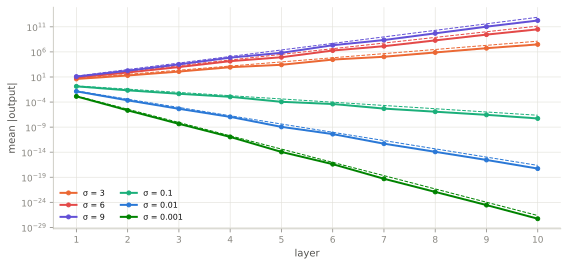

In [101]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Log-scale chart of the mean absolute output of each of 10 linear layers for six weight scales. Lines for sigma 3, 6 and 9 climb steeply to between 1e7 and 1e12; lines for sigma 0.1, 0.01 and 0.001 fall to between 1e-6 and 1e-28. Dashed lines show the prediction from equation (31) and track each measured line closely."
# plot helper: mean |output| per layer for the six weight scales, with the prediction of eq. (31)
fig, ax = plt.subplots(figsize=(8, 3.8))
colors = ["#eb6834", "#e34948", "#6250d6", "#1baf7a", "#2a78d6", "#008300"]
for c, res, color in zip(wt_config_h + wt_config_l, res_h + res_l, colors):
    measured = [np.abs(o).mean() for o in res]
    predicted = [np.abs(x).mean() * (np.sqrt(5) * c[1]) ** l for l in range(1, 11)]   # std grows by sqrt(n_in) * sigma per layer
    ax.plot(range(1, 11), measured, "-o", color=color, ms=4, label=f"σ = {c[1]}")
    ax.plot(range(1, 11), predicted, "--", color=color, lw=1)
ax.set_yscale("log"); ax.set_xlabel("layer"); ax.set_ylabel("mean |output|"); ax.set_xticks(range(1, 11))
ax.legend(ncol=2, loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

*Figure 13: The ten-layer linear stack. Solid lines are the measured outputs; dashed lines are the prediction of equation (31), a factor of $\sqrt{5}\,\sigma$ per layer. Only a factor of exactly 1 would keep the signal at its starting scale.*
{.caption}

### How the variance travels through a layer

**One layer.** Take one output of a linear layer with zero biases (a sensible starting point, as we will see): $y_i = \sum_{j=1}^{n_{in}} w_{ij}\,x_j$. Assume the weights are independent of each other and of the inputs, with mean 0 and variance $\mathrm{Var}(w)$, and the inputs are identically distributed. The variance of a sum of independent terms is the sum of their variances, so $\mathrm{Var}(y_i) = n_{in}\,\mathrm{Var}(wx)$. For independent $w$ and $x$,

$$\mathrm{Var}(wx) = \mathbb{E}[w^2x^2] - \big(\mathbb{E}[wx]\big)^2 = \mathbb{E}[w^2]\,\mathbb{E}[x^2] - \big(\mathbb{E}[w]\,\mathbb{E}[x]\big)^2 = \mathrm{Var}(w)\,\mathbb{E}[x^2],$$

because $\mathbb{E}[w] = 0$ makes $\mathbb{E}[w^2] = \mathrm{Var}(w)$ and kills the second term. Therefore

$$\boxed{\mathrm{Var}(y) = n_{in}\,\mathrm{Var}(w)\,\mathbb{E}[x^2]}\tag{30}$$

Note that it is $\mathbb{E}[x^2]$, not $\mathrm{Var}(x)$. The two are equal only when $x$ has mean zero, and that is exactly where ReLU will make a difference.

**Many layers, no activation.** Each layer's input is the previous layer's output, which has mean zero, so $\mathbb{E}[x^2] = \mathrm{Var}(x)$ and equation (30) chains:

$$\mathrm{Var}(y_L) = \mathrm{Var}(x_1)\prod_{l=1}^{L} n_{in}^{(l)}\,\mathrm{Var}(w_l).\tag{31}$$

Every layer multiplies the variance by $n_{in}\mathrm{Var}(w)$. Above 1 the signal explodes, below 1 it vanishes, and depth turns a small excess into an enormous one: in the experiment, $n_{in} = 5$ and $\sigma = 9$ give a factor of $5\cdot81 = 405$ in variance, so about 20 in standard deviation, per layer, and $20^{10} \approx 10^{13}$. The only stable choice is a factor of exactly 1, that is, $\mathrm{Var}(w) = 1/n_{in}$.

**With ReLU.** Now let $x_l = \mathrm{ReLU}(y_{l-1})$. If the weights are symmetric around 0, so is $y_{l-1}$; call its density $p$, with $p(y) = p(-y)$. ReLU keeps the positive half and zeroes the rest:

$$\mathbb{E}[x_l^2] = \int_0^{\infty} y^2\,p(y)\,dy = \frac12\int_{-\infty}^{\infty} y^2\,p(y)\,dy = \frac12\,\mathrm{Var}(y_{l-1}).\tag{32}$$

ReLU halves the second moment. Substituting into equation (30), $\mathrm{Var}(y_l) = \tfrac12\,n_{in}\mathrm{Var}(w_l)\,\mathrm{Var}(y_{l-1})$, and a factor of exactly 1 now requires

$$\boxed{\mathrm{Var}(w) = \frac{2}{n_{in}}},\qquad w \sim \mathcal{N}\Big(0,\ \frac{2}{n_{in}}\Big).\tag{33}$$

This is **Kaiming He initialisation** ([He et al., 2015](https://arxiv.org/abs/1502.01852)). The 2 exists only to cancel the half that ReLU removes; without an activation, the right choice is $1/n_{in}$.

**The backward pass.** By equation (19), the gradient for a layer's input is $dX = dZ\,W$, so $\partial L/\partial x_j = \sum_i \delta_i\,w_{ij}$ is a sum over $n_{out}$ terms, and ReLU's derivative lets half of them through. The same argument gives

$$\mathrm{Var}\Big(\frac{\partial L}{\partial x_l}\Big) = \frac12\,n_{out}\,\mathrm{Var}(w)\,\mathrm{Var}\Big(\frac{\partial L}{\partial x_{l+1}}\Big).\tag{34}$$

With $\mathrm{Var}(w) = 2/n_{in}$, each layer's backward factor is $n_{out}/n_{in}$. Layer $l$'s output width is layer $l+1$'s input width, so the product over all layers *telescopes* to $n_{out}^{(L)}/n_{in}^{(1)}$, the last width over the first. That is a constant that does not grow or shrink with depth, so fixing the forward pass keeps the gradients in range too. (He et al. call this the `fan_in` mode; choosing $2/n_{out}$ instead, `fan_out`, fixes the backward pass exactly and leaves the forward factor bounded.)

**Uniform version.** A uniform distribution $U[-a, a]$ has variance $a^2/3$. Setting $a^2/3 = 2/n_{in}$ gives the bound

$$a = \sqrt{\frac{6}{n_{in}}}.\tag{35}$$

<details>
<summary><strong>Xavier (Glorot) initialisation</strong> (click to expand)</summary>

Before ReLU took over, [Glorot & Bengio (2010)](https://proceedings.mlr.press/v9/glorot10a.html) derived the same conditions for activations that are roughly linear around 0, such as tanh. The forward pass needs $\mathrm{Var}(w) = 1/n_{in}$ and the backward pass needs $1/n_{out}$. Both can hold only if the layer is square, so they take the harmonic mean, $\mathrm{Var}(w) = 2/(n_{in} + n_{out})$. With ReLU, Xavier's factor per layer is about $\tfrac12$, so a deep ReLU network initialised this way still vanishes, at a rate of $2^{-L}$ in variance.

</details>

For our network, layer 2 has $n_{in} = 64$, so Kaiming's standard deviation is $\sqrt{2/64} \approx 0.18$. $\mathcal{N}(0, 1)$ is about 5.7 times too large, which by equation (33) multiplies the variance by $\tfrac12\cdot 64 = 32$ in that layer alone. That is the growth we saw in Figure 12.

### Code: the Kaiming standard deviation

`kaiming_weight_init` returns the standard deviation of equation (33) for the normal distribution, or the bound $a$ of equation (35) for the uniform one, from the layer's fan-in (`mode='n_in'`) or fan-out (`mode='n_out'`). A common slip is to write $2/\sqrt{n}$ instead of $\sqrt{2/n}$: that is the standard deviation squared in the wrong place, and it grows the variance by a factor of 2 per ReLU layer instead of 1. The square root must wrap the whole fraction.

In [102]:
def kaiming_weight_init(n, mode='n_in', dist='normal'):
    n_in, n_out = n
    num, denom = 0, 1
    if dist == 'normal':
        num = 2
    elif dist == 'uniform':
        num = 6

    if mode == 'n_in':
        denom = n_in
    elif mode == 'n_out':
        denom = n_out

    std = np.sqrt(num/denom)   # Var(w) = num / fan (eq. 33); for 'uniform' this is the bound a of eq. (35)
    return std

In [ ]:
# a 5x5 layer gives sqrt(2/5); a 64-input layer gives sqrt(2/64)
print(kaiming_weight_init((5, 5)), np.sqrt(2 / 5))
print(kaiming_weight_init((64, 32)), np.sqrt(2 / 64))
print(kaiming_weight_init((64, 32), dist="uniform"), np.sqrt(6 / 64))

0.6324555320336759 0.6324555320336759
0.1767766952966369 0.1767766952966369
0.30618621784789724 0.30618621784789724


The $5\times5$ stack above has no activation, so the right standard deviation there is $\sqrt{1/n_{in}}$, not Kaiming's. To test equation (33) properly we need ReLUs, and enough units and samples for the statistics to mean something. A single sample through five units dies quickly, since all five can be negative at once. So we use the same ten-layer stack, now 256 units wide, with a ReLU after every layer, fed 1000 random inputs. We compare four standard deviations, tracking the root mean square $\sqrt{\mathbb{E}[x^2]}$ of each layer's output, which is the quantity equation (30) propagates.

In [ ]:
# the same ten-layer stack, now with a ReLU after every layer, 256 units wide, fed a batch of 1000 inputs
def dummy_relu(c, x, width=256):
    res = []
    for i in range(10):
        w = get_dummy_inputs((width, x.shape[-1]), seed=42+i, mean=c[0], std=c[1])
        out = relu(linear(x, w, b=0))
        x = out
        res.append(out)
    return res

x_relu = get_dummy_inputs((1000, 256), seed=1)
relu_configs = {
    "N(0, 1)": 1.0,
    "2/√n (the slip)": 2 / np.sqrt(256),
    "√(1/n) (no ReLU correction)": np.sqrt(1 / 256),
    "Kaiming √(2/n)": kaiming_weight_init((256, 256)),
}
relu_rms = {name: [np.sqrt((o ** 2).mean()) for o in dummy_relu((0, std), x_relu)] for name, std in relu_configs.items()}
for name, rms in relu_rms.items():
    print(f"{name:28s} RMS after layer 1: {rms[0]:9.3g}   layer 5: {rms[4]:9.3g}   layer 10: {rms[9]:9.3g}")

N(0, 1)                      RMS after layer 1:      11.3   layer 5:  1.71e+05   layer 10:  2.85e+10
2/√n (the slip)              RMS after layer 1:      1.41   layer 5:      5.23   layer 10:      26.5
√(1/n) (no ReLU correction)  RMS after layer 1:     0.706   layer 5:     0.163   layer 10:    0.0259
Kaiming √(2/n)               RMS after layer 1:     0.998   layer 5:     0.925   layer 10:     0.829


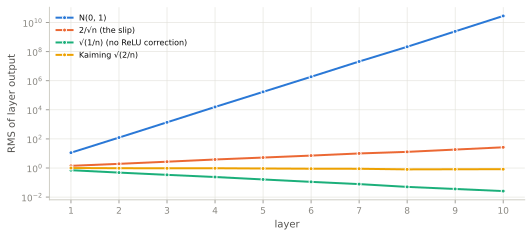

In [105]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Log-scale chart of the root mean square of each layer's output in a 10-layer, 256-wide ReLU stack, for four weight scales. N(0, 1) climbs to about 1e10; 2 over root n climbs about 30-fold; root of 1 over n falls about 30-fold; Kaiming stays flat near 1."
# plot helper: RMS of each layer's output in the ReLU stack
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for (name, rms), color in zip(relu_rms.items(), [SERIES[0], SERIES[1], SERIES[2], "#eda100"]):
    ax.plot(range(1, 11), rms, "-o", color=color, ms=4, mec="white", label=name)
ax.set_yscale("log"); ax.set_xlabel("layer"); ax.set_ylabel("RMS of layer output"); ax.set_xticks(range(1, 11))
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

*Figure 14: Ten ReLU layers, 256 wide. Only Kaiming's $\sqrt{2/n}$ keeps the signal at its starting scale. $\sqrt{1/n}$ forgets ReLU's halving and loses a factor of $\sqrt2$ per layer; $2/\sqrt n$ gains one.*
{.caption}

### Kaiming initialisation in the library

Only the two initialisers change. Each weight matrix gets the standard deviation from `kaiming_weight_init` for its own fan-in, and biases start at zero, because a bias does not need to break symmetry and any non-zero value only adds to the spread. Everything else is inherited from `NeuralNetwork` unchanged.

In [106]:
class NeuralNetworkKaiming(NeuralNetwork):
    @staticmethod
    def weight_init(layers, feat_in, mean=0, std=1, seed_factor=42):
        # mean / std are ignored: each layer's std comes from its fan-in, eq. (33)
        weights = {}
        for l_i in range(len(layers)):
            seed = seed_factor + l_i
            n_in = feat_in if l_i == 0 else layers[l_i - 1]
            std_k = kaiming_weight_init((n_in, layers[l_i]))
            weights[l_i + 1] = Parameters(n_in=n_in, n_out=layers[l_i], mean=0, std=std_k, seed=seed)
        return weights


    @staticmethod
    def bias_init(layers, mean=0, std=1, seed_factor=1042):
        # biases start at exactly 0
        bias = {}
        for l_i in range(len(layers)):
            seed = seed_factor + l_i
            bias[l_i + 1] = Parameters(n_in=1, n_out=layers[l_i], mean=0, std=0, seed=seed)
        return bias

In [107]:
# demo: the starting loss and per-layer statistics with Kaiming init
model = init_model(NeuralNetworkKaiming)
act_std, grad_std = layer_stats(model, train_X, train_Y)
print(f"loss at initialisation: {cross_entropy(model.forward_pass(train_X)[n_layers].z, train_Y):.4f}   (ln 3 = {np.log(3):.4f})")
print(f"std of Z_l: {[f'{v:.2g}' for v in act_std]} | std of dW_l: {[f'{v:.2g}' for v in grad_std]}")

loss at initialisation: 1.1033   (ln 3 = 1.0986)
std of Z_l: ['0.46', '0.42', '0.38', '0.36', '0.1'] | std of dW_l: ['0.0015', '0.0019', '0.0034', '0.0067', '0.0055']


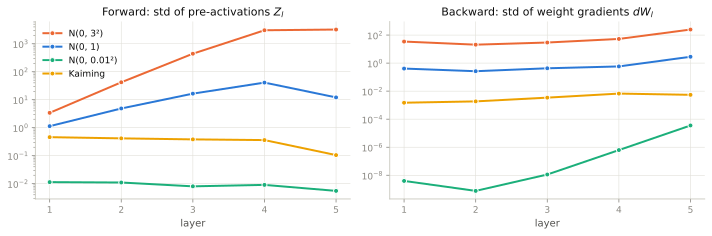

In [108]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "The same two log-scale charts as Figure 12 with a fourth line for Kaiming. Kaiming's pre-activation spread stays flat between about 0.1 and 0.5 across layers, and its gradient spread stays within one order of magnitude across layers."
# plot helper: Figure 12 again, with Kaiming added
plot_layer_stats([(label, init_model(NeuralNetwork, std)) for label, std in [("N(0, 3²)", 3.0), ("N(0, 1)", 1.0), ("N(0, 0.01²)", 0.01)]]
                 + [("Kaiming", init_model(NeuralNetworkKaiming))])

*Figure 15: Figure 12 with Kaiming initialisation added. The loss at initialisation is now $\ln 3$, the forward signal keeps its scale across layers, and the gradients of all layers are within a factor of about 5 of each other.*
{.caption}

### The full run

One more thing changes with the initialisation: the right learning rate. $\mathcal{N}(0, 1)$ weights produce huge gradients, so a learning rate of 0.01 already makes big steps. With Kaiming the gradients are about 100 times smaller (Figure 15), so the same learning rate crawls. A fair comparison gives each initialisation its best learning rate, so we sweep five, training each for 150 epochs.

In [ ]:
# learning-rate sweep for N(0, 1) and Kaiming initialisation, 150 epochs each
import io, contextlib

def quiet_train(model, *args, **kwargs):
    with contextlib.redirect_stdout(io.StringIO()):          # silence the per-epoch log
        return model.train(*args, **kwargs)

init_sweep = {}
print(f"{'init':8s} {'lr':>6s} | {'final train loss':>16s} | {'final test acc':>14s} | {'loss spikes':>11s}")
for name, cls in [("N(0, 1)", NeuralNetwork), ("Kaiming", NeuralNetworkKaiming)]:
    for lr in [0.003, 0.01, 0.03, 0.1, 0.3]:
        model = cls(layers)
        history = quiet_train(model, train_X, train_Y, test_X, test_Y, lr=lr, epochs=150)
        init_sweep[name, lr] = (model, history)
        tl = history["train_loss"]
        spikes = sum(1 for a, b in zip(tl, tl[1:]) if b - a > 0.2)        # epochs where the loss jumps up by > 0.2
        print(f"{name:8s} {lr:>6} | {tl[-1]:16.3f} | {history['test_acc'][-1]:14.3f} | {spikes:11d}")

init         lr | final train loss | final test acc | loss spikes


N(0, 1)   0.003 |            0.228 |          0.917 |           1


N(0, 1)    0.01 |            0.283 |          0.967 |           3


N(0, 1)    0.03 |            0.428 |          0.844 |          10


N(0, 1)     0.1 |            1.098 |          0.272 |           0


N(0, 1)     0.3 |            1.099 |          0.328 |           0


Kaiming   0.003 |            1.060 |          0.433 |           0


Kaiming    0.01 |            0.498 |          0.867 |           0


Kaiming    0.03 |            0.026 |          0.989 |           0


Kaiming     0.1 |            0.032 |          0.989 |           2


Kaiming     0.3 |            0.036 |          0.989 |           5


$\mathcal{N}(0, 1)$ has a narrow window: its best run (lr 0.01) reaches 96.7% test accuracy with a few loss spikes along the way, and from lr 0.1 upward it never learns. Kaiming learns at every learning rate from 0.03 to 0.3 and reaches 98.9% test accuracy, with a training loss 10 times lower. At lr 0.01, though, it is slower than $\mathcal{N}(0, 1)$: small weights mean small gradients, so it needs a larger step. Good initialisation makes larger learning rates *safe*; it does not make a small one fast.

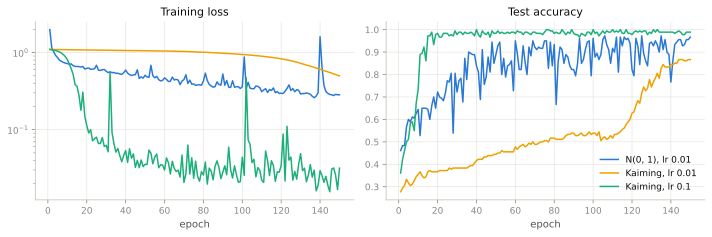

In [110]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Two line charts over 150 epochs. Left, training loss on a log scale: Kaiming at learning rate 0.1 drops fastest, to about 0.03; N(0, 1) at 0.01 falls to about 0.3 with spikes; Kaiming at 0.01 stays near 1 for 100 epochs before falling. Right, test accuracy: Kaiming at 0.1 reaches about 99% by epoch 20; N(0, 1) at 0.01 climbs to about 97% with dips; Kaiming at 0.01 rises late to about 87%."
# plot helper: training curves for N(0, 1) and Kaiming at their best learning rates
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
for (name, lr), color in [(("N(0, 1)", 0.01), SERIES[0]), (("Kaiming", 0.01), "#eda100"), (("Kaiming", 0.1), SERIES[2])]:
    history = init_sweep[name, lr][1]
    epochs = range(1, len(history["train_loss"]) + 1)
    ax1.plot(epochs, history["train_loss"], color=color, lw=1.5, label=f"{name}, lr {lr}")
    ax2.plot(epochs, history["test_acc"], color=color, lw=1.5, label=f"{name}, lr {lr}")
ax1.set_yscale("log"); ax1.set_title("Training loss"); ax2.set_title("Test accuracy")
for ax in (ax1, ax2):
    ax.set_xlabel("epoch")
ax2.legend(loc="lower right")
fig.tight_layout()
plt.show()

*Figure 16: Training curves at each initialisation's best learning rate, plus Kaiming at $\mathcal{N}(0, 1)$'s learning rate for reference. With Kaiming at lr 0.1 the loss ends about ten times lower; the occasional spike (a step that overshoots) is undone within an epoch or two, and test accuracy passes 95% within about 20 epochs.*
{.caption}

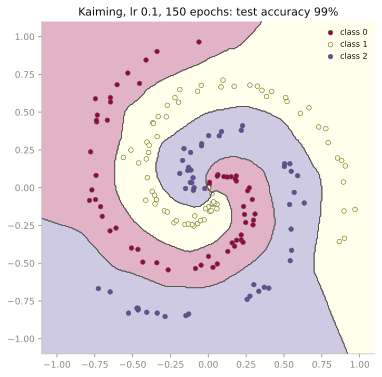

In [111]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Decision regions of the Kaiming-initialised network trained at learning rate 0.1, with the test points on top. Three spiral-shaped regions follow the three arms closely all the way to the centre."
# plot helper: decision regions of a trained model, with data points on top
def plot_boundary(ax, model, x, y, title="", highlight=None, lim=1.1, n=300):
    g = np.linspace(-lim, lim, n)
    gx, gy = np.meshgrid(g, g)
    pred = model.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx, gy, pred, levels=[-0.5, 0.5, 1.5, 2.5], colors=CLASS_COLORS, alpha=0.3)
    for k in range(3):
        ax.contour(gx, gy, (pred == k).astype(float), levels=[0.5], colors=INK_2, linewidths=0.8)
        m = y == k
        ax.scatter(x[m, 0], x[m, 1], color=CLASS_COLORS[k], s=22, edgecolors=INK_2, linewidths=0.5, label=f"class {k}")
    if highlight is not None:
        ax.scatter(x[highlight, 0], x[highlight, 1], s=90, facecolors="none", edgecolors=INK, linewidths=1.3, label="flipped label")
    ax.set_aspect("equal"); ax.grid(False)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_title(title)

fig, ax = plt.subplots(figsize=(5.4, 5.4))
model, history = init_sweep["Kaiming", 0.1]
plot_boundary(ax, model, test_X, test_Y, f"Kaiming, lr 0.1, 150 epochs: test accuracy {history['test_acc'][-1]:.0%}")
ax.legend(loc="upper right", fontsize=8, handletextpad=0.2)
fig.tight_layout()
plt.show()

*Figure 17: With Kaiming initialisation and a learning rate it can tolerate, the network learns the spiral itself. Compare Figure 11.*
{.caption}

---

## Weight Decay

Our spiral has 720 clean training points, and the network generalises well. Real data is rarely that kind: there is less of it, and some labels are wrong. A flexible enough network will then fit the wrong labels too. It *memorises* the training set instead of learning the pattern, a failure called **overfitting**.

### A run that overfits

We make the training set small and noisy: 90 points drawn from the training set, with about 15% of their labels flipped to a wrong class. To give the network room to memorise, we widen it to $2\to128\to128\to64\to3$, train it with Kaiming initialisation for 2000 epochs, and test it on the full, clean test set.

In [ ]:
# a small, noisy training set: 90 points, ~15% of labels flipped to a different class
def noisy_subset(x, y, n=90, flip=0.15, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(x), n, replace=False)
    x_s, y_s = x[idx], y[idx].copy()
    flipped = rng.random(n) < flip
    y_s[flipped] = (y_s[flipped] + rng.integers(1, 3, flipped.sum())) % 3    # move to one of the two other classes
    return x_s, y_s, flipped, idx

small_X, small_Y, flipped, small_idx = noisy_subset(train_X, train_Y)
wide_layers = [128, 128, 64, 3]
print(f"{len(small_Y)} training points, {flipped.sum()} with a flipped label")

90 training points, 14 with a flipped label


In [ ]:
# log the size of the weights once per epoch (train() calls evaluate() once per epoch)
def with_norm_log(cls):
    class Tracked(cls):
        def evaluate(self, x, y):
            ws = [self.weights[k].weights for k in self.weights]
            self.norm_log.append((np.sqrt(sum((w ** 2).sum() for w in ws)),          # ||W|| over all layers
                                  np.prod([np.linalg.norm(w, 2) for w in ws])))      # product of spectral norms, eq. (36)
            return super().evaluate(x, y)
    return Tracked

overfit = with_norm_log(NeuralNetworkKaiming)(wide_layers); overfit.norm_log = []
history_overfit = overfit.train(small_X, small_Y, test_X, test_Y, lr=0.05, epochs=2000, log_every=500)
print("flipped training points the network predicts with their (wrong) training label:",
      (overfit.predict(small_X[flipped]) == small_Y[flipped]).sum(), "of", flipped.sum())

epoch  500/2000 | train loss 0.3458 acc 0.822 | test loss 0.3534 acc 0.900


epoch 1000/2000 | train loss 0.2452 acc 0.878 | test loss 0.4240 acc 0.878


epoch 1500/2000 | train loss 0.1758 acc 0.922 | test loss 0.4148 acc 0.872


epoch 2000/2000 | train loss 0.1202 acc 0.978 | test loss 0.4882 acc 0.861
flipped training points the network predicts with their (wrong) training label: 13 of 14


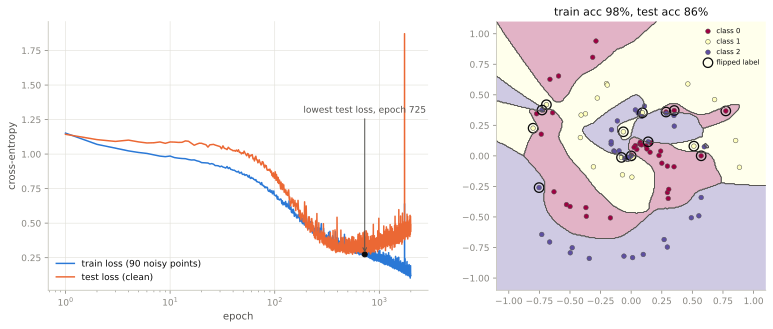

In [114]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Left: training and test loss over 2000 epochs on a log-scaled epoch axis. Training loss keeps falling; test loss falls to a minimum of about 0.27 near epoch 700 and then rises. Right: decision regions of the overfitted network with the 90 training points; circled points with flipped labels sit inside small pockets of their wrong class."
# plot helper: the overfitting signature, and the boundary it produces
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
epochs = np.arange(1, len(history_overfit["train_loss"]) + 1)
ax1.plot(epochs, history_overfit["train_loss"], color=SERIES[0], lw=1.5, label="train loss (90 noisy points)")
ax1.plot(epochs, history_overfit["test_loss"], color=SERIES[1], lw=1.5, label="test loss (clean)")
best = int(np.argmin(history_overfit["test_loss"]))
ax1.plot(best + 1, history_overfit["test_loss"][best], "o", color=INK, ms=5)
ax1.annotate(f"lowest test loss, epoch {best + 1}", (best + 1, history_overfit["test_loss"][best]), xytext=(best + 1, 1.3),
             textcoords="data", fontsize=9, color=INK_2, ha="center", arrowprops=dict(arrowstyle="->", color=INK_2, lw=1))
ax1.set_xscale("log"); ax1.set_xlabel("epoch"); ax1.set_ylabel("cross-entropy"); ax1.legend(loc="lower left")
plot_boundary(ax2, overfit, small_X, small_Y, f"train acc {history_overfit['train_acc'][-1]:.0%}, test acc {history_overfit['test_acc'][-1]:.0%}", highlight=flipped)
ax2.legend(loc="upper right", fontsize=7, handletextpad=0.2)
fig.tight_layout()
plt.show()

*Figure 18: The signature of overfitting. The training loss keeps falling, while the test loss bottoms out and then climbs: from that point on, everything the network learns is noise. On the right, the boundary bends around the flipped training points (circled) to give each one a small region of its wrong class.*
{.caption}

### How the weights make overfitting possible

To give a flipped point its own small region, the network's output has to swing from one class to another over a tiny distance in the input space. How fast can the output change? Each linear layer stretches distances by at most its *spectral norm* $\lVert W\rVert_2$ (its largest singular value): $\lVert Wx - Wx'\rVert \le \lVert W\rVert_2\,\lVert x - x'\rVert$, and the bias cancels in the difference. ReLU never stretches, since $\lvert\mathrm{ReLU}(a) - \mathrm{ReLU}(b)\rvert \le \lvert a - b\rvert$. Chaining the layers gives

$$\lVert f(x) - f(x')\rVert \le \Big(\prod_{l}\lVert W_l\rVert_2\Big)\,\lVert x - x'\rVert.\tag{36}$$

The product of spectral norms caps how sharply the logits can change across the input plane. Small weights force a smooth, slowly varying boundary; sharp detours around individual points need large weights. As a test, we train the same network on 90 *clean* points and compare.

In [ ]:
# the same 90 points with their true labels, same network and training
clean = with_norm_log(NeuralNetworkKaiming)(wide_layers); clean.norm_log = []
history_clean = quiet_train(clean, small_X, train_Y[small_idx], test_X, test_Y, lr=0.05, epochs=2000)
for name, model, history in [("clean labels", clean, history_clean), ("noisy labels", overfit, history_overfit)]:
    norm, lip = model.norm_log[-1]
    print(f"{name}: test acc {history['test_acc'][-1]:.3f} | ||W|| = {norm:.1f} | product of spectral norms = {lip:.0f}")

clean labels: test acc 0.944 | ||W|| = 26.8 | product of spectral norms = 667
noisy labels: test acc 0.861 | ||W|| = 28.1 | product of spectral norms = 995


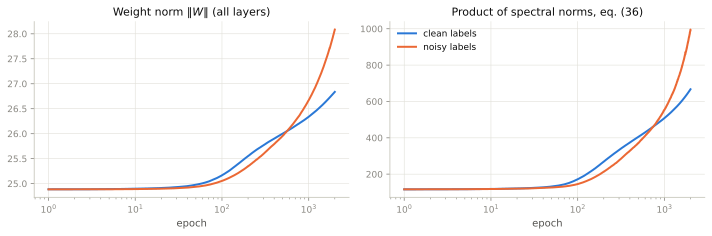

In [116]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Two line charts over 2000 epochs on a log-scaled epoch axis, comparing clean and noisy labels. Left, overall weight norm; right, product of spectral norms. Up to about epoch 800 the clean run's weights are slightly larger; after that the noisy run's grow much faster and end about 1.5 times higher on the right."
# plot helper: weight size during training, clean vs noisy labels
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
for model, label, color in [(clean, "clean labels", SERIES[0]), (overfit, "noisy labels", SERIES[1])]:
    log = np.array(model.norm_log)
    ax1.plot(np.arange(1, len(log) + 1), log[:, 0], color=color, label=label)
    ax2.plot(np.arange(1, len(log) + 1), log[:, 1], color=color, label=label)
ax1.set_title("Weight norm $\\|W\\|$ (all layers)"); ax2.set_title("Product of spectral norms, eq. (36)")
for ax in (ax1, ax2):
    ax.set_xscale("log"); ax.set_xlabel("epoch")
ax2.legend(loc="upper left")
fig.tight_layout()
plt.show()

*Figure 19: Fitting wrong labels needs sharper turns, and sharper turns need bigger weights. For most of training the two runs grow alike; the noisy run's weights take off late, in the same epochs where its test loss rises (Figure 18), and the bound of equation (36) ends about 1.5 times higher than with clean labels.*
{.caption}

### Penalising large weights

If large weights are what make memorisation possible, we can make them expensive. **Weight decay** adds a penalty on the size of the weights to the loss.

**L2 penalty.** Add half the squared size of every weight matrix, scaled by a strength $\lambda \gt 0$:

$$L_{\text{total}}(\theta) = L(\theta) + \frac{\lambda}{2}\sum_{l}\lVert W_l\rVert_F^2,\qquad \lVert W\rVert_F^2 = \sum_{i,j}W_{ij}^2.\tag{37}$$

The penalty's gradient with respect to $W_l$ is simply $\lambda W_l$, so one SGD step (equation 27) becomes

$$W \leftarrow W - \eta\,(\nabla_W L + \lambda W) = (1 - \eta\lambda)\,W - \eta\,\nabla_W L.\tag{38}$$

Before the usual update, every weight is multiplied by $(1 - \eta\lambda)$, slightly less than 1. That is where the name comes from: unless the data keeps pushing a weight back, it *decays* towards zero. Training settles where the two forces balance, $\nabla_W L = -\lambda W$.

**L1 penalty.** Add the sum of absolute values instead:

$$L_{\text{total}}(\theta) = L(\theta) + \lambda\sum_{l}\sum_{i,j}\lvert W_{l,ij}\rvert,\qquad \frac{\partial}{\partial w}\,\lambda\lvert w\rvert = \lambda\,\mathrm{sign}(w).\tag{39}$$

The two pulls differ in shape. L2's pull is proportional to the weight: it shrinks large weights hard and barely touches small ones, so weights become small but rarely exactly zero. L1's pull has the same size $\lambda$ for every weight, however small, so weights that the data does not need are driven to zero. L1 therefore produces *sparse* weights, the property behind the lasso in statistics ([Tibshirani, 1996](https://doi.org/10.1111/j.2517-6161.1996.tb02080.x)). (With SGD, the L1 pull makes such weights jitter around 0 at a scale of $\eta\lambda$ instead of landing on it exactly, so below we count weights with $\lvert w\rvert \lt 10^{-3}$ as zero.)

**What to penalise.** Only the weights. Biases shift the logits but do not stretch the input space, so they do not appear in equation (36), and penalising them only costs fit.

<details>
<summary><strong>The probabilistic view: weight decay as a prior</strong> (click to expand)</summary>

Cross-entropy is a negative log-likelihood (equation 9). If we also put a prior distribution on the weights and maximise the *posterior* instead (MAP estimation), the loss gains a term $-\log p(\theta)$. A Gaussian prior $w \sim \mathcal{N}(0, 1/\lambda)$ gives $-\log p(w) = \tfrac{\lambda}{2}w^2 + \text{const}$, which is the L2 penalty. A Laplace prior $p(w) \propto e^{-\lambda\lvert w\rvert}$ gives $\lambda\lvert w\rvert$, the L1 penalty. Weight decay encodes the belief that, before seeing data, small weights are more likely than large ones. MAP estimation is covered in the [earlier post on this blog](/posts/gen-vs-disc-ml/) (Appendix G).

</details>

### Code: weight decay in the library

Each penalty is an op with its own gradient, like every other piece of the network:

In [117]:
def l2_penalty(w, lam):
    return 0.5 * lam * (w ** 2).sum()          # eq. (37)

def l2_penalty_backward(w, lam):
    return lam * w

def l1_penalty(w, lam):
    return lam * np.abs(w).sum()               # eq. (39)

def l1_penalty_backward(w, lam):
    return lam * np.sign(w)

In [ ]:
# finite-difference check of both penalty gradients
rng = np.random.default_rng(6)
w_t = rng.normal(size=(4, 3))
for name, f, f_back in [("l2", l2_penalty, l2_penalty_backward), ("l1", l1_penalty, l1_penalty_backward)]:
    err = rel_error(f_back(w_t, 0.1), numerical_grad(lambda w_: f(w_, 0.1), w_t))
    print(f"{name}_penalty_backward: max relative error vs finite differences = {err:.1e}")
    assert err < 1e-6

l2_penalty_backward: max relative error vs finite differences = 3.4e-10
l1_penalty_backward: max relative error vs finite differences = 1.6e-09


**What changes in the library, and why.** The penalty touches only the weights, and only through their gradient, so the forward pass, the backward pass and the logged loss stay exactly as they were. The logged loss is the data loss only, so runs with different $\lambda$ remain comparable.

| Method | Change | Why |
|---|---|---|
| `train` | reads `weight_decay` ($\lambda$) and `penalty` (`"l2"` or `"l1"`) | the new hyperparameters, in the same `**kwargs` style |
| `update_parameters` | adds the penalty gradient to `dw` before `sgd` | equations (38) and (39); biases are not decayed |
| everything else | unchanged, inherited from `NeuralNetworkKaiming` | the penalty does not depend on the data |

In [119]:
class NeuralNetworkWD(NeuralNetworkKaiming):
    def __init__(self, layers):
        super().__init__(layers)
        self.weight_decay = 0.0
        self.penalty = "l2"


    def train(self, train_x, train_y, test_x, test_y, **kwargs):
        self.weight_decay = kwargs.get("weight_decay", 0.0)     # lambda
        self.penalty = kwargs.get("penalty", "l2")             # "l2" or "l1"
        return super().train(train_x, train_y, test_x, test_y, **kwargs)


    def penalty_grad(self, w):
        if self.penalty == "l1":
            return l1_penalty_backward(w, self.weight_decay)
        return l2_penalty_backward(w, self.weight_decay)


    def update_parameters(self, grad):
        for l_key in range(1, self.n_layers + 1):
            w = self.weights[l_key].weights
            dw = grad[l_key].dw + self.penalty_grad(w)          # weights only, eqs. (38) and (39)
            self.weights[l_key].weights = sgd(w, dw, self.lr)
            self.bias[l_key].weights = sgd(self.bias[l_key].weights, grad[l_key].db, self.lr)   # biases: no decay

### The full run

The overfitting experiment again, now with a sweep over the strength $\lambda$ for both penalties. ($\lambda = 0$ reproduces the run above exactly.)

In [120]:
# demo: weight decay on the small noisy training set, 2000 epochs each
wd_runs = {}
print(f"{'penalty':7s} {'lambda':>7s} | {'train acc':>9s} | {'test acc':>8s} | {'test loss':>9s} | {'||W||':>6s} | {'|w| < 1e-3':>10s}")
for penalty, lam in [("none", 0.0), ("l2", 1e-3), ("l2", 3e-3), ("l2", 1e-2), ("l1", 1e-3), ("l1", 3e-3)]:
    model = NeuralNetworkWD(wide_layers)
    history = quiet_train(model, small_X, small_Y, test_X, test_Y, lr=0.05, epochs=2000,
                          weight_decay=lam, penalty="l1" if penalty == "l1" else "l2")
    wd_runs[penalty, lam] = (model, history)
    ws = np.concatenate([model.weights[k].weights.ravel() for k in model.weights])
    print(f"{penalty:7s} {lam:>7} | {history['train_acc'][-1]:9.3f} | {history['test_acc'][-1]:8.3f} | "
          f"{history['test_loss'][-1]:9.3f} | {np.linalg.norm(ws):6.1f} | {np.mean(np.abs(ws) < 1e-3):10.2f}")

penalty  lambda | train acc | test acc | test loss |  ||W|| | |w| < 1e-3


none        0.0 |     0.978 |    0.861 |     0.488 |   28.1 |       0.01


l2        0.001 |     0.933 |    0.894 |     0.365 |   22.1 |       0.01


l2        0.003 |     0.878 |    0.928 |     0.306 |   14.7 |       0.01


l2         0.01 |     0.833 |    0.906 |     0.407 |    8.5 |       0.05


l1        0.001 |     0.867 |    0.950 |     0.312 |   16.0 |       0.90


l1        0.003 |     0.856 |    0.917 |     0.382 |   11.7 |       0.99


Both penalties trade a little training accuracy, the part that came from memorising flipped labels, for test accuracy. L2 with $\lambda = 3\times10^{-3}$ lifts test accuracy from 86% to 93% and nearly halves $\lVert W\rVert$. L1 with $\lambda = 10^{-3}$ does even better here, 95%, while switching off 90% of the weights entirely. Too much decay ($\lambda = 10^{-2}$) starts to underfit. $\lambda$ is a hyperparameter like the learning rate.

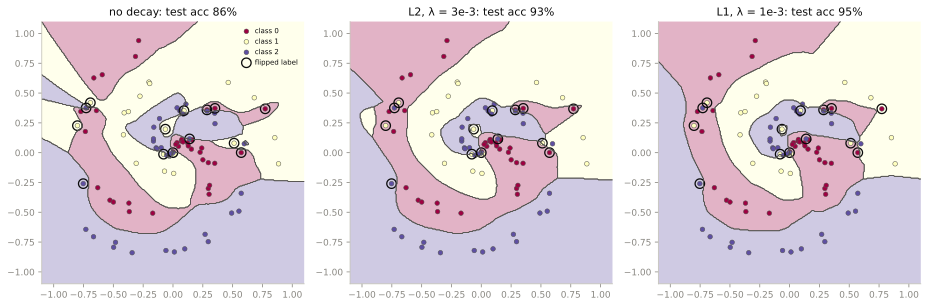

In [121]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Three decision-region plots of the 90 noisy training points, with flipped labels circled. Without decay, the boundary bends around flipped points. With L2 decay and with L1 decay, the regions are smoother spiral arms and most flipped points are left inside the region of their true class."
# plot helper: decision regions without decay, with L2 and with L1
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, key, name in zip(axes, [("none", 0.0), ("l2", 3e-3), ("l1", 1e-3)], ["no decay", "L2, λ = 3e-3", "L1, λ = 1e-3"]):
    model, history = wd_runs[key]
    plot_boundary(ax, model, small_X, small_Y, f"{name}: test acc {history['test_acc'][-1]:.0%}", highlight=flipped)
axes[0].legend(loc="upper right", fontsize=7, handletextpad=0.2)
fig.tight_layout()
plt.show()

*Figure 20: The same 90 noisy points, with and without weight decay. With decay, the network can no longer afford the sharp detours around flipped points (circled), so it leaves them misclassified and draws smoother arms that match the clean test set better.*
{.caption}

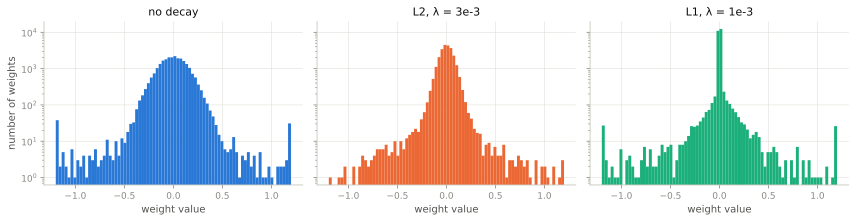

In [122]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Three histograms of all weight values, with a log-scaled count axis. No decay: a wide spread out to about plus or minus 1. L2: a narrower spread. L1: a tall spike at exactly zero holding most weights, plus a thin spread of larger weights."
# plot helper: where the weights end up
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
bins = np.linspace(-1.2, 1.2, 81)
for ax, key, name, color in zip(axes, [("none", 0.0), ("l2", 3e-3), ("l1", 1e-3)], ["no decay", "L2, λ = 3e-3", "L1, λ = 1e-3"],
                                [SERIES[0], SERIES[1], SERIES[2]]):
    model = wd_runs[key][0]
    ws = np.concatenate([model.weights[k].weights.ravel() for k in model.weights])
    ax.hist(np.clip(ws, -1.2, 1.2), bins=bins, color=color)
    ax.set_yscale("log"); ax.set_title(name); ax.set_xlabel("weight value")
axes[0].set_ylabel("number of weights")
fig.tight_layout()
plt.show()

*Figure 21: Where the weights end up. L2 pulls the whole distribution in towards zero; L1 sends most weights to (almost exactly) zero and keeps a few large ones, the sparsity predicted by its constant pull. (Values beyond ±1.2 are counted in the end bins.)*
{.caption}

**✓ End of Part 3: Train it well.** You know why deep networks explode, vanish or overfit, and how Kaiming initialisation and weight decay prevent it. Part 4 makes training robust with BatchNorm and AdamW.
{.checkpoint}

---

## Batch Normalisation

Kaiming initialisation gave us a network that trains smoothly at learning rates from 0.03 to 0.3. Can it train faster still, with less tuning? Two things stand in the way.

### What initialisation cannot fix

**It only holds at step 0.** Equation (33) assumes the weights are independent, zero-mean random numbers. Once training starts, the weights are shaped by the data and that assumption no longer holds, so the scale of each layer's output is free to drift, and the drift compounds through the layers. We measure the spread of every hidden layer's pre-activations on the training set after each epoch.

In [ ]:
# log the spread of each hidden layer's pre-activations once per epoch
def with_layer_std_log(cls):
    class Tracked(cls):
        def evaluate(self, x, y):
            mode = getattr(self, "training", None)
            self.training = False                          # inference mode for BatchNorm models (no effect otherwise)
            out = self.forward_pass(train_X)
            self.training = mode
            # the input to each ReLU: Z_l, or the BatchNorm output when the layer has one
            self.std_log.append([getattr(out[l], "z_bn", out[l].z).std() for l in range(1, self.n_layers)])
            return super().evaluate(x, y)
    return Tracked

drift_kaiming = with_layer_std_log(NeuralNetworkKaiming)(layers); drift_kaiming.std_log = []
quiet_train(drift_kaiming, train_X, train_Y, test_X, test_Y, lr=0.1, epochs=150)
log = np.array(drift_kaiming.std_log)
print("std of the input to each ReLU, after epoch 1:  ", log[0].round(2))
print("std of the input to each ReLU, after epoch 150:", log[-1].round(2))

std of the input to each ReLU, after epoch 1:   [0.46 0.42 0.39 0.33]
std of the input to each ReLU, after epoch 150: [0.56 0.95 1.7  3.77]


After the first epoch the four hidden layers sit at a similar scale. By epoch 150 the spread grows from layer to layer, roughly doubling at each one. Initialisation set the scale once; training is free to undo it.

**It leaves the learning rate fragile.** The sweep in the weight-initialisation section showed that Kaiming trains only within a window of learning rates, 0.03 to 0.3. Below it, training crawls; above it, it fails. Picking the learning rate is still a careful search.

What if, instead of setting the scale once, we *reset* it at every layer, at every step?

### Batch normalisation: the forward pass

**Batch normalisation** (BN; [Ioffe & Szegedy, 2015](https://arxiv.org/abs/1502.03167)) standardises each feature over the current mini-batch. Take one feature (one column of $Z_l$) with values $x_1,\dots,x_B$ across the batch. Compute its batch mean and variance,

$$\mu_B = \frac1B\sum_{n=1}^{B}x_n,\qquad \sigma_B^2 = \frac1B\sum_{n=1}^{B}(x_n - \mu_B)^2,\tag{40}$$

standardise it, with a small $\epsilon$ (we use $10^{-5}$) to avoid dividing by zero,

$$\hat x_n = \frac{x_n - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}},\tag{41}$$

and then apply a learnable scale and shift, one pair per feature:

$$y_n = \gamma\,\hat x_n + \beta.\tag{42}$$

After equation (41) every feature has mean 0 and variance 1 over the batch, *whatever the weights have drifted to*. Note that it fixes only the mean and variance, not the shape of the distribution. Equation (42) gives the network its flexibility back: without $\gamma$ and $\beta$, every layer would be forced to zero mean and unit variance. With them, the layer can learn any scale and offset, including undoing the normalisation entirely ($\gamma = \sqrt{\sigma_B^2 + \epsilon}$, $\beta = \mu_B$). They start at $\gamma = 1$, $\beta = 0$ and are learned by gradient descent like any other parameter.

**Where it goes.** We place BN between each hidden layer's linear map and its ReLU: linear → BN → ReLU. The last layer stays a plain linear map that outputs logits. The bias of a linear layer followed by BN is redundant, because subtracting $\mu_B$ removes any constant shift and $\beta$ takes over its job. We keep it to reuse `linear` unchanged, and we will see that it receives a gradient of exactly zero.

**Inference.** At test time we may predict one sample at a time, and a prediction should not depend on which other samples share its batch. So during training, BN also keeps exponential running averages of the batch statistics,

$$\mu_{\text{run}} \leftarrow (1 - m)\,\mu_{\text{run}} + m\,\mu_B,\qquad \sigma^2_{\text{run}} \leftarrow (1 - m)\,\sigma^2_{\text{run}} + m\,\sigma_B^2,\tag{43}$$

with momentum $m = 0.1$, and in inference mode it standardises with $\mu_{\text{run}}$ and $\sigma^2_{\text{run}}$ instead of the batch's own statistics.

In [124]:
def batch_norm(x, gamma, beta, eps=1e-5):
    # x -> (B, n): statistics over the batch axis, one per feature
    mu = x.mean(axis=0)                            # (n,)    eq. (40)
    var = x.var(axis=0)                            # (n,)    biased variance, eq. (40)
    x_hat = (x - mu) / np.sqrt(var + eps)          # (B, n)  eq. (41)
    out = gamma * x_hat + beta                     # (B, n)  eq. (42)
    return out, x_hat, mu, var

In [ ]:
# a batch of 4 samples, 2 features on very different scales -> each column comes out with mean 0, std 1
z_demo = np.array([[1.0, 200.0], [2.0, 100.0], [3.0, 400.0], [6.0, 300.0]])
out_demo, x_hat_demo, mu_demo, var_demo = batch_norm(z_demo, gamma=np.ones(2), beta=np.zeros(2))
print("x_hat =\n", x_hat_demo.round(3))
print("mean per feature:", x_hat_demo.mean(axis=0).round(6), "  std per feature:", x_hat_demo.std(axis=0).round(4))

x_hat =
 [[-1.069 -0.447]
 [-0.535 -1.342]
 [ 0.     1.342]
 [ 1.604  0.447]]
mean per feature: [-0.  0.]   std per feature: [1. 1.]


### Batch normalisation: the backward pass

Given the upstream gradient $g_n = \partial L/\partial y_n$, we need gradients for $\gamma$, $\beta$ and the input $x_n$. Write $s = \sqrt{\sigma_B^2 + \epsilon}$.

**Scale and shift.** From equation (42), $\gamma$ and $\beta$ are used by every sample in the batch, so their gradients sum over it (as with $db$ in equation 18):

$$d\gamma = \sum_{n} g_n\,\hat x_n,\qquad d\beta = \sum_{n} g_n,\qquad d\hat x_n = g_n\,\gamma.\tag{44}$$

**The input: three paths.** This is the subtle part. Each $x_n$ affects the loss along three paths: directly through its own $\hat x_n$, through the mean $\mu_B$ (which every $\hat x_m$ uses), and through the variance $\sigma_B^2$ (likewise). By equation (14), we add up all three.

- *Through the variance.* $\partial\hat x_m/\partial\sigma_B^2 = (x_m - \mu_B)\cdot(-\tfrac12)(\sigma_B^2 + \epsilon)^{-3/2} = -\hat x_m/(2s^2)$, so
  $$\frac{\partial L}{\partial\sigma_B^2} = -\frac{1}{2s^2}\sum_m d\hat x_m\,\hat x_m.$$
- *Through the mean.* $\partial\hat x_m/\partial\mu_B = -1/s$. The mean also enters $\sigma_B^2$, but $\partial\sigma_B^2/\partial\mu_B = -\tfrac2B\sum_m(x_m - \mu_B) = 0$, so
  $$\frac{\partial L}{\partial\mu_B} = -\frac1s\sum_m d\hat x_m.$$
- *Combine.* With $\partial\hat x_n/\partial x_n = 1/s$, $\partial\mu_B/\partial x_n = 1/B$ and $\partial\sigma_B^2/\partial x_n = 2(x_n - \mu_B)/B = 2s\hat x_n/B$:
  $$\frac{\partial L}{\partial x_n} = \frac{d\hat x_n}{s} - \frac{1}{2s^2}\Big(\sum_m d\hat x_m\hat x_m\Big)\frac{2s\,\hat x_n}{B} - \frac1s\Big(\sum_m d\hat x_m\Big)\frac1B.$$

Collecting the terms over a common factor $1/(Bs)$:

$$\boxed{\frac{\partial L}{\partial x_n} = \frac{1}{B\,s}\Big(B\,d\hat x_n - \sum_m d\hat x_m - \hat x_n\sum_m d\hat x_m\,\hat x_m\Big)}\tag{45}$$

Read it as: take the incoming gradient, remove its batch mean, and remove its component along $\hat x$. Two consequences follow. The input gradients of a batch always sum to zero, $\sum_n \partial L/\partial x_n = 0$, which is why the bias before BN gets exactly zero gradient. And the gradient is blind to any change that only shifts or rescales the batch, because BN would undo that change anyway.

In [126]:
def batch_norm_backward(grad_out, x_hat, var, gamma, eps=1e-5):
    B = grad_out.shape[0]
    dgamma = (grad_out * x_hat).sum(axis=0)        # eq. (44)
    dbeta = grad_out.sum(axis=0)                   # eq. (44)
    dx_hat = grad_out * gamma                      # eq. (44)
    dx = (B * dx_hat - dx_hat.sum(axis=0) - x_hat * (dx_hat * x_hat).sum(axis=0)) / (B * np.sqrt(var + eps))   # eq. (45)
    return dx, dgamma, dbeta

In [ ]:
# finite-difference check of eqs. (44)-(45). L = sum(batch_norm(x) * G)
rng = np.random.default_rng(7)
x_t, G = rng.normal(size=(6, 4)) * 3 + 1, rng.normal(size=(6, 4))
gamma_t, beta_t = rng.normal(size=4), rng.normal(size=4)
_, x_hat_t, _, var_t = batch_norm(x_t, gamma_t, beta_t)
dx, dgamma, dbeta = batch_norm_backward(G, x_hat_t, var_t, gamma_t)
errs = {
    "dx (45)": rel_error(dx, numerical_grad(lambda x_: (batch_norm(x_, gamma_t, beta_t)[0] * G).sum(), x_t)),
    "dgamma (44)": rel_error(dgamma, numerical_grad(lambda g_: (batch_norm(x_t, g_, beta_t)[0] * G).sum(), gamma_t)),
    "dbeta (44)": rel_error(dbeta, numerical_grad(lambda b_: (batch_norm(x_t, gamma_t, b_)[0] * G).sum(), beta_t)),
}
for k, v in errs.items():
    print(f"{k}: max relative error vs finite differences = {v:.1e}")
print("sum of dx over the batch, per feature:", dx.sum(axis=0).round(12))
assert max(errs.values()) < 1e-6

dx (45): max relative error vs finite differences = 3.3e-10
dgamma (44): max relative error vs finite differences = 1.6e-10
dbeta (44): max relative error vs finite differences = 8.2e-11
sum of dx over the batch, per feature: [ 0. -0. -0.  0.]


### Batch normalisation in the library

BN needs more than an override of one method: each hidden layer now has extra parameters ($\gamma$, $\beta$), extra state (running statistics), extra values to remember for the backward pass ($\hat x$ and $\sigma_B^2$), and two modes. The layer containers grow to hold the new values:

In [128]:
class LayerOutputBN(LayerOutput):
    def __init__(self, z=np.array([]), z_bn=np.array([]), x_hat=np.array([]), var=np.array([]), act=np.array([]), nm=""):
        super().__init__(z, act, nm)
        self.z_bn = z_bn          # BatchNorm output, the input to ReLU
        self.x_hat = x_hat        # standardised z, needed by eq. (45)
        self.var = var            # batch variance, needed by eq. (45)

    def __repr__(self):
        return f"LayerOutputBN: z -> {self.z.shape}; z_bn -> {self.z_bn.shape}; activation -> {self.activation.shape}; type -> {self.nm}"


class LayerGradBN(LayerGrad):
    def __init__(self, dw=np.array([]), db=np.array([]), dz=np.array([]), d_act=np.array([]), dgamma=np.array([]), dbeta=np.array([]), nm=""):
        super().__init__(dw, db, dz, d_act, nm)
        self.dgamma = dgamma
        self.dbeta = dbeta

    def __repr__(self):
        return f"LayerGradBN: dw -> {self.dw.shape}; dgamma -> {self.dgamma.shape}; dbeta -> {self.dbeta.shape}; type -> {self.nm}"

| Method | Change | Why |
|---|---|---|
| `bn_init` (new) | $\gamma = 1$, $\beta = 0$, running mean 0, running variance 1 for every hidden layer | BN starts as pure standardisation |
| `forward_pass` | linear → `batch_norm` → ReLU for hidden layers; batch statistics in training mode, running statistics in inference mode | equations (40)–(43) |
| `backward_pass` | ReLU's gradient now flows into `batch_norm_backward`, then into `linear_backward` | equations (44)–(45) |
| `update_parameters` | weights and biases as before (with weight decay), plus an SGD step for $\gamma$ and $\beta$ | $\gamma$ and $\beta$ are learned, and not decayed |
| `predict`, `evaluate` | switch to inference mode | predictions must not depend on the batch |
| `train` | calls `bn_init` first | fresh BN parameters for every run |

In [129]:
class NeuralNetworkBN(NeuralNetworkWD):
    def __init__(self, layers, momentum=0.1, eps=1e-5):
        super().__init__(layers)
        self.momentum = momentum
        self.eps = eps
        self.training = True
        self.gamma, self.beta = None, None
        self.running_mean, self.running_var = None, None


    def bn_init(self):
        # one (gamma, beta) pair and one set of running statistics per hidden layer
        hidden = range(1, self.n_layers)
        self.gamma = {l: Parameters(n_in=1, n_out=self.layers[l - 1], mean=1, std=0) for l in hidden}
        self.beta = {l: Parameters(n_in=1, n_out=self.layers[l - 1], mean=0, std=0) for l in hidden}
        self.running_mean = {l: np.zeros(self.layers[l - 1]) for l in hidden}
        self.running_var = {l: np.ones(self.layers[l - 1]) for l in hidden}


    def forward_pass(self, x):
        nn_layer_out = {0: LayerOutput(z=x, act=x, nm="input")}

        for l_i in range(self.n_layers):
            l_key = l_i + 1
            w = self.weights[l_key].weights
            x = nn_layer_out[l_key - 1].activation
            b = self.bias[l_key].weights
            z = linear(x, w, b)
            if l_key < self.n_layers:
                gamma, beta = self.gamma[l_key].weights, self.beta[l_key].weights
                if self.training:
                    z_bn, x_hat, mu, var = batch_norm(z, gamma, beta, self.eps)
                    m = self.momentum                                                   # eq. (43)
                    self.running_mean[l_key] = (1 - m) * self.running_mean[l_key] + m * mu
                    self.running_var[l_key] = (1 - m) * self.running_var[l_key] + m * var
                else:
                    var = self.running_var[l_key]
                    x_hat = (z - self.running_mean[l_key]) / np.sqrt(var + self.eps)
                    z_bn = gamma * x_hat + beta
                out = relu(z_bn)
                nn_layer_out[l_key] = LayerOutputBN(z=z, z_bn=z_bn, x_hat=x_hat, var=var, act=out, nm=f"{l_key}_output")
            else:
                nn_layer_out[l_key] = LayerOutput(z=z, nm=f"{l_key}_output")
        return nn_layer_out


    def backward_pass(self, nn_layer_out, y):
        nn_layer_grad = {}
        l_i = self.n_layers

        while l_i > 0:
            a_prev = nn_layer_out[l_i - 1].activation
            d_act, dgamma, dbeta = np.array([]), np.array([]), np.array([])

            if l_i == self.n_layers:
                # output layer: loss -> logits, no BatchNorm
                dz = cross_entropy_backward(1.0, nn_layer_out[l_i].z, y)
            else:
                # hidden layer: next layer's dz -> activation -> ReLU -> BatchNorm -> z
                out = nn_layer_out[l_i]
                W_next = self.weights[l_i + 1].weights
                d_act = np.matmul(nn_layer_grad[l_i + 1].dz, W_next)                   # eq. (25)
                dz_bn = relu_backward(d_act, out.z_bn)                                 # ReLU now sits after BN
                dz, dgamma, dbeta = batch_norm_backward(dz_bn, out.x_hat, out.var, self.gamma[l_i].weights, self.eps)

            dw, db = linear_backward(dz, a_prev)
            nn_layer_grad[l_i] = LayerGradBN(dw, db, dz, d_act, dgamma, dbeta, nm=f"{l_i}_gradients")
            l_i -= 1

        return nn_layer_grad


    def update_parameters(self, grad):
        super().update_parameters(grad)                     # weights (with weight decay) and biases
        for l_key in range(1, self.n_layers):
            self.gamma[l_key].weights = sgd(self.gamma[l_key].weights, grad[l_key].dgamma, self.lr)
            self.beta[l_key].weights = sgd(self.beta[l_key].weights, grad[l_key].dbeta, self.lr)


    def predict(self, x):
        self.training = False
        pred = super().predict(x)
        self.training = True
        return pred


    def evaluate(self, x, y):
        self.training = False
        result = super().evaluate(x, y)
        self.training = True
        return result


    def train(self, train_x, train_y, test_x, test_y, **kwargs):
        self.bn_init()
        return super().train(train_x, train_y, test_x, test_y, **kwargs)

In [ ]:
# finite-difference check of the whole BatchNorm network (training mode) on a small net and batch
bn_check = NeuralNetworkBN([16, 8, 3])
bn_check.weights = bn_check.weight_init([16, 8, 3], 2)
bn_check.bias = bn_check.bias_init([16, 8, 3])
bn_check.bn_init()
x16, y16 = train_X[:16], train_Y[:16]
bn_grad = bn_check.backward_pass(bn_check.forward_pass(x16), y16)

def bn_loss_with(params, l_key, value):
    saved = params[l_key].weights
    params[l_key].weights = value
    loss_ = cross_entropy(bn_check.forward_pass(x16)[bn_check.n_layers].z, y16)
    params[l_key].weights = saved
    return loss_

for name, params, attr in [("W", bn_check.weights, "dw"), ("gamma", bn_check.gamma, "dgamma"), ("beta", bn_check.beta, "dbeta")]:
    for l_key in params:
        err = rel_error(getattr(bn_grad[l_key], attr), numerical_grad(lambda v: bn_loss_with(params, l_key, v), params[l_key].weights))
        print(f"layer {l_key} {name:5s}: max relative error {err:.1e}")
        assert err < 1e-5
print("gradient of the biases before BatchNorm:", [float(np.abs(bn_grad[l].db).max()) for l in (1, 2)])

layer 1 W    : max relative error 3.3e-09
layer 2 W    : max relative error 2.2e-09
layer 3 W    : max relative error 7.7e-10
layer 1 gamma: max relative error 3.8e-09
layer 2 gamma: max relative error 1.2e-09
layer 1 beta : max relative error 3.0e-09
layer 2 beta : max relative error 4.5e-10
gradient of the biases before BatchNorm: [5.898059818321144e-17, 2.5804011705155006e-17]


Every gradient matches, and the biases in front of BN receive a gradient of (numerically) zero, as equation (45) predicts.

### What BatchNorm buys us

**1. Stable scales, by construction.** The drift experiment again, now with BN. The input to each ReLU is $\gamma\hat x + \beta$, so its spread is set by $\gamma$, a parameter that learns slowly and deliberately, not by the accumulated drift of every earlier layer.

In [ ]:
# the drift experiment with BatchNorm
drift_bn = with_layer_std_log(NeuralNetworkBN)(layers); drift_bn.std_log = []
quiet_train(drift_bn, train_X, train_Y, test_X, test_Y, lr=0.1, epochs=150)
print("BatchNorm, std of the input to each ReLU, after epoch 1:  ", np.array(drift_bn.std_log[0]).round(2))
print("BatchNorm, std of the input to each ReLU, after epoch 150:", np.array(drift_bn.std_log[-1]).round(2))

BatchNorm, std of the input to each ReLU, after epoch 1:   [0.8  0.8  0.8  0.83]
BatchNorm, std of the input to each ReLU, after epoch 150: [1.04 1.08 1.19 1.49]


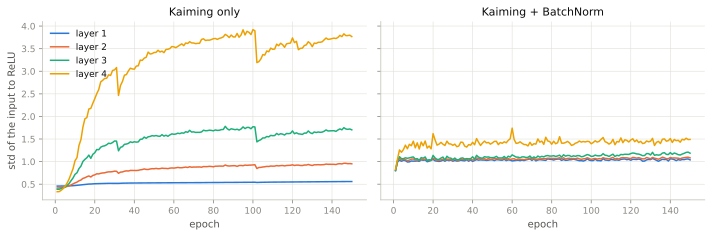

In [132]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Two line charts of the spread of the input to each of the four ReLU layers over 150 epochs. Left, Kaiming only: the lines fan out over training, the deepest layer rising to several times the first. Right, Kaiming with BatchNorm: all four lines stay close together near 1 to 2."
# plot helper: per-layer spread of the ReLU inputs during training, with and without BN
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, model, title in [(axes[0], drift_kaiming, "Kaiming only"), (axes[1], drift_bn, "Kaiming + BatchNorm")]:
    log = np.array(model.std_log)
    for l, color in zip(range(log.shape[1]), [SERIES[0], SERIES[1], SERIES[2], "#eda100"]):
        ax.plot(np.arange(1, len(log) + 1), log[:, l], color=color, lw=1.5, label=f"layer {l + 1}")
    ax.set_title(title); ax.set_xlabel("epoch")
axes[0].set_ylabel("std of the input to ReLU"); axes[0].legend(loc="upper left")
fig.tight_layout()
plt.show()

*Figure 22: The spread of each hidden layer's ReLU input during training (lr 0.1). Without BN, the scales drift apart and the deeper layers drift most. With BN, every layer stays near the scale its $\gamma$ chooses.*
{.caption}

**2. Insensitive to the learning rate.** The learning-rate sweep, extended to a range of 1000× (0.001 to 3), for Kaiming with and without BN, 50 epochs each:

In [ ]:
# learning-rate sweep with and without BatchNorm, 50 epochs each
bn_lrs = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
bn_sweep = {}
for name, cls in [("Kaiming", NeuralNetworkKaiming), ("Kaiming + BN", NeuralNetworkBN)]:
    for lr in bn_lrs:
        model = cls(layers)
        bn_sweep[name, lr] = (model, quiet_train(model, train_X, train_Y, test_X, test_Y, lr=lr, epochs=50))
    print(f"{name:13s} test acc after 50 epochs:", " ".join(f"lr {lr}: {bn_sweep[name, lr][1]['test_acc'][-1]:.2f}" for lr in bn_lrs))

Kaiming       test acc after 50 epochs: lr 0.001: 0.32 lr 0.003: 0.37 lr 0.01: 0.44 lr 0.03: 0.92 lr 0.1: 0.98 lr 0.3: 0.98 lr 1.0: 0.33 lr 3.0: 0.40


Kaiming + BN  test acc after 50 epochs: lr 0.001: 0.77 lr 0.003: 0.93 lr 0.01: 0.99 lr 0.03: 0.98 lr 0.1: 0.99 lr 0.3: 0.97 lr 1.0: 0.99 lr 3.0: 0.40


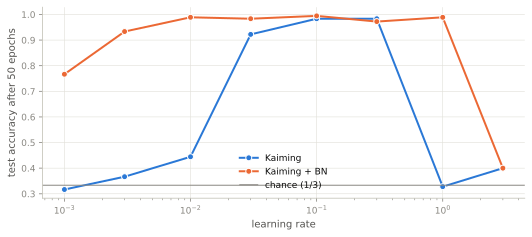

In [134]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Line chart of test accuracy after 50 epochs against learning rate on a log axis from 0.001 to 3. Kaiming alone is near chance below 0.03, near 98% from 0.03 to 0.3, and back near chance at 1 and 3. Kaiming with BatchNorm is above 75% from 0.001 and above 93% from 0.003 to 1, failing only at 3."
# plot helper: test accuracy vs learning rate
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for name, color in [("Kaiming", SERIES[0]), ("Kaiming + BN", SERIES[1])]:
    ax.plot(bn_lrs, [bn_sweep[name, lr][1]["test_acc"][-1] for lr in bn_lrs], "-o", color=color, ms=6, mec="white", label=name)
ax.axhline(1 / 3, color=MUTED, lw=1, label="chance (1/3)")
ax.set_xscale("log"); ax.set_xlabel("learning rate"); ax.set_ylabel("test accuracy after 50 epochs")
ax.legend(loc="lower center")
fig.tight_layout()
plt.show()

*Figure 23: BatchNorm widens the range of learning rates that work from 10× (0.03 to 0.3) to about 300× (0.003 to 1). Picking a learning rate stops being a careful search.*
{.caption}

**3. Why it works: not covariate shift.** Ioffe and Szegedy motivated BN by *internal covariate shift*: as earlier layers update, the distribution of each layer's input keeps changing, so every layer chases a moving target. It is an appealing story, but [Santurkar et al. (2018)](https://arxiv.org/abs/1805.11604) tested it directly. They injected random noise *after* each BN layer, so that the input distributions shifted heavily at every step, and the networks still trained almost as fast as with plain BN. BN networks also do not show markedly less covariate shift than networks without it. Their explanation is that BN makes the **loss landscape smoother**: the loss and its gradient change more slowly as the weights move, so the gradient stays a good guide over a longer step, and larger steps become safe.

A second mechanism is easy to derive. Scale the weights feeding a BN layer by $c \gt 0$. The pre-activations scale by $c$, and so do their batch mean and standard deviation, so equation (41) cancels it (up to the tiny $\epsilon$):

$$L(c\,W) = L(W).\tag{46}$$

Differentiating both sides with respect to $W$ gives $c\,\nabla L(cW) = \nabla L(W)$, so

$$\nabla L(cW) = \frac{1}{c}\,\nabla L(W).\tag{47}$$

Larger weights get proportionally smaller gradients, and the effective learning rate on the *direction* of $W$ falls like $\eta/\lVert W\rVert^2$. If a large learning rate inflates the weights, their own gradients shrink to compensate. This automatic damping is one reason BN tolerates large learning rates ([Arora et al., 2018](https://arxiv.org/abs/1812.03981)).

**Measuring smoothness.** Following Santurkar et al., at every training step we take the current gradient $g$, try steps of several sizes $\eta \in \{0.05, 0.1, 0.2, 0.4\}$ along it, and record two things: the *range of losses* reached (a smooth landscape changes little), and the **effective β-smoothness**, the largest change in the gradient per unit distance moved,

$$\beta_{\text{eff}} = \max_{\eta}\frac{\lVert\nabla L(\theta - \eta g) - \nabla L(\theta)\rVert}{\eta\,\lVert g\rVert}.\tag{48}$$

A small $\beta_{\text{eff}}$ means the gradient barely changes along the step, so it can be trusted further.

In [ ]:
# read and write every trainable parameter of a model, and get all their gradients
import copy

def all_params(model):
    params = [model.weights[k].weights for k in model.weights] + [model.bias[k].weights for k in model.bias]
    if getattr(model, "gamma", None):
        params += [model.gamma[k].weights for k in model.gamma] + [model.beta[k].weights for k in model.beta]
    return params

def set_all_params(model, values):
    containers = list(model.weights.values()) + list(model.bias.values())
    if getattr(model, "gamma", None):
        containers += list(model.gamma.values()) + list(model.beta.values())
    for container, value in zip(containers, values):
        container.weights = value

def all_grads(model, x, y):
    out = model.forward_pass(x)
    grad = model.backward_pass(out, y)
    grads = [grad[k].dw for k in model.weights] + [grad[k].db for k in model.bias]
    if getattr(model, "gamma", None):
        grads += [grad[k].dgamma for k in model.gamma] + [grad[k].dbeta for k in model.beta]
    return cross_entropy(out[model.n_layers].z, y), grads

def norm(arrays):
    return np.sqrt(sum((a ** 2).sum() for a in arrays))

def landscape_run(cls, arch, lr=0.1, epochs=10, etas=(0.05, 0.1, 0.2, 0.4)):
    # train with SGD; before every full-batch step, probe the loss and gradient along the gradient direction, eq. (48)
    model = cls(arch)
    model.lr, model.batch = lr, 32
    model.weights, model.bias = model.weight_init(arch, 2), model.bias_init(arch)
    if hasattr(model, "bn_init"):
        model.bn_init()
    rng, rows = np.random.default_rng(42), []
    for epoch in range(epochs):
        for xb, yb in data_iterator((train_X, train_Y), model.batch, shuffle=True, rng=rng):
            if len(yb) == model.batch:
                theta = [p.copy() for p in all_params(model)]
                stats = copy.deepcopy((getattr(model, "running_mean", None), getattr(model, "running_var", None)))
                loss0, g0 = all_grads(model, xb, yb)
                losses, betas = [loss0], []
                for eta in etas:
                    set_all_params(model, [t - eta * g for t, g in zip(theta, g0)])
                    loss_eta, g_eta = all_grads(model, xb, yb)
                    losses.append(loss_eta)
                    betas.append(norm([a - b for a, b in zip(g_eta, g0)]) / (eta * norm(g0)))
                set_all_params(model, theta)                           # undo the probe
                model.running_mean, model.running_var = stats          # (and its effect on BN's running statistics)
                rows.append((min(losses), max(losses), max(betas)))
            model.train_step(xb, yb)
    return np.array(rows)

deep_layers = [64] * 8 + [3]
landscape = {}
for arch_name, arch in [("5 layers", layers), ("9 layers", deep_layers)]:
    for name, cls in [("Kaiming", NeuralNetworkKaiming), ("Kaiming + BN", NeuralNetworkBN)]:
        rows = landscape[arch_name, name] = landscape_run(cls, arch)
        print(f"{arch_name}, {name:13s}| loss range along the gradient: median {np.median(rows[:, 1] - rows[:, 0]):.3f}, "
              f"90th pct {np.percentile(rows[:, 1] - rows[:, 0], 90):.3f} | effective beta: median {np.median(rows[:, 2]):5.1f}, 90th pct {np.percentile(rows[:, 2], 90):5.1f}")

5 layers, Kaiming      | loss range along the gradient: median 0.033, 90th pct 0.081 | effective beta: median   4.7, 90th pct   8.9


5 layers, Kaiming + BN | loss range along the gradient: median 0.178, 90th pct 0.425 | effective beta: median   9.6, 90th pct  14.0


9 layers, Kaiming      | loss range along the gradient: median 0.784, 90th pct 3.606 | effective beta: median  17.0, 90th pct  24.4


9 layers, Kaiming + BN | loss range along the gradient: median 0.309, 90th pct 0.622 | effective beta: median  12.0, 90th pct  17.1


An honest result first: on our 5-layer network, BN does *not* make the landscape smoother by these measures. It is rougher, with a median loss range about five times larger, partly because BN's gradients are larger. On a deeper network with nine layers ($2\to64\times8\to3$), the picture flips. Without BN the loss along the gradient varies about 2.5 times more at the median and almost 6 times more at the 90th percentile, and the gradient changes faster per unit distance, while with BN both measures stay moderate and steady. The smoothing grows with depth, which matches where BN matters in practice: in deep networks, where small distortions compound layer after layer.

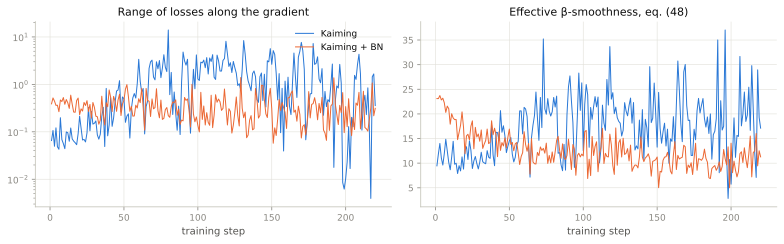

In [136]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Two charts over about 220 training steps of the 9-layer network. Left, the range of losses reached along the gradient at each step, on a log scale: for the first 50 steps both are small; after that, without BatchNorm it often jumps to between 1 and 10, while with BatchNorm it stays mostly between 0.1 and 1. Right, effective beta-smoothness: after the first 50 steps, without BatchNorm it is higher and much spikier than with it."
# plot helper: Santurkar-style landscape measurements on the 9-layer network
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
for name, color in [("Kaiming", SERIES[0]), ("Kaiming + BN", SERIES[1])]:
    rows = landscape["9 layers", name]
    steps = np.arange(1, len(rows) + 1)
    ax1.plot(steps, rows[:, 1] - rows[:, 0], color=color, lw=1, label=name)
    ax2.plot(steps, rows[:, 2], color=color, lw=1, label=name)
ax1.set_yscale("log"); ax1.set_title("Range of losses along the gradient"); ax2.set_title("Effective β-smoothness, eq. (48)")
for ax in (ax1, ax2):
    ax.set_xlabel("training step")
ax1.legend(loc="upper right")
fig.tight_layout()
plt.show()

*Figure 24: The loss landscape seen from each training step of the 9-layer network (lr 0.1, 10 epochs). Near initialisation both networks sit in a smooth region. Once training moves the weights, the network without BN finds itself in rough terrain where a step along the gradient can change the loss by 1 to 10, while with BatchNorm the landscape stays smooth, so the gradient remains a reliable guide over larger steps (after Santurkar et al., 2018, Figure 4).*
{.caption}

**4. A side effect: regularisation.** In training mode, each sample is standardised with the statistics of whichever samples happen to share its batch, so its output carries a little batch-dependent noise. Like other forms of noise injection, this discourages the network from relying on the exact value of any single activation, and it acts as a mild regulariser. It also explains a puzzle in the next run: the *training* loss logged in training mode stays well above the loss the same network achieves in inference mode.

**5. The full run.** Kaiming with and without BN, both at lr 0.1, for 50 epochs:

In [ ]:
# training curves at lr 0.1, and the BatchNorm model's loss in training vs inference mode
for name in ["Kaiming", "Kaiming + BN"]:
    model, history = bn_sweep[name, 0.1]
    first95 = next((i + 1 for i, a in enumerate(history["test_acc"]) if a >= 0.95), None)
    print(f"{name:13s} test acc {history['test_acc'][-1]:.3f} | first epoch with test acc >= 95%: {first95}")
model_bn = bn_sweep["Kaiming + BN", 0.1][0]
print(f"BatchNorm model, final epoch: logged train loss (training mode) {bn_sweep['Kaiming + BN', 0.1][1]['train_loss'][-1]:.3f} "
      f"| train loss in inference mode {model_bn.evaluate(train_X, train_Y)[1]:.3f}")

Kaiming       test acc 0.983 | first epoch with test acc >= 95%: 15
Kaiming + BN  test acc 0.994 | first epoch with test acc >= 95%: 6
BatchNorm model, final epoch: logged train loss (training mode) 0.340 | train loss in inference mode 0.099


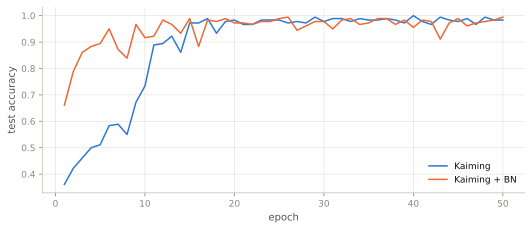

In [138]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Test accuracy over 50 epochs at learning rate 0.1. Kaiming with BatchNorm passes 95% within the first few epochs; Kaiming alone takes noticeably longer and fluctuates more."
# plot helper: test accuracy per epoch at lr 0.1, with and without BN
fig, ax = plt.subplots(figsize=(7.5, 3.3))
for name, color in [("Kaiming", SERIES[0]), ("Kaiming + BN", SERIES[1])]:
    history = bn_sweep[name, 0.1][1]
    ax.plot(np.arange(1, len(history["test_acc"]) + 1), history["test_acc"], color=color, lw=1.5, label=name)
ax.set_xlabel("epoch"); ax.set_ylabel("test accuracy"); ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

*Figure 25: At the same learning rate, the BatchNorm network learns the spiral in fewer epochs.*
{.caption}

The puzzle from point 4 shows up in the output above: the BatchNorm model's logged training loss (training mode, batch statistics) is 0.34, while the same weights score 0.10 on the same training data in inference mode. The gap is the batch noise that acts as a regulariser.

---

## Adam and AdamW

### The limits of one learning rate

SGD moves every parameter with the same learning rate, $\theta \leftarrow \theta - \eta\nabla L$. That is fine if the landscape curves the same way in every direction, but loss landscapes rarely do. Take the 2-D bowl $L(w) = a_1w_1^2 + a_2w_2^2$ with $a_2 \gg a_1$, a narrow *ravine*. The two coordinates do not interact, so equation (28) applies to each one separately:

$$w_i \leftarrow (1 - 2\eta a_i)\,w_i,\qquad i = 1, 2.\tag{49}$$

Stability needs $\lvert 1 - 2\eta a_i\rvert \lt 1$ for *both*, so $\eta \lt 1/a_2$, a limit set by the *steepest* direction. With that $\eta$, the shallow direction shrinks by $1 - 2\eta a_1 \gt 1 - 2a_1/a_2$ per step. The ratio $\kappa = a_2/a_1$ is the **condition number**. For $\kappa = 100$, the shallow coordinate keeps at least 98% of its distance every step, so it needs over 100 steps just to shrink tenfold, while the steep coordinate bounces from wall to wall. Real networks have condition numbers far larger than 100.

The fix is to give each parameter its own step size: large where the gradient is consistently small (shallow), small where it is large (steep).

### Adam

Adam ([Kingma & Ba, 2015](https://arxiv.org/abs/1412.6980)) keeps two running averages for every parameter, of the gradient and of the squared gradient:

$$m_t = \beta_1\,m_{t-1} + (1 - \beta_1)\,g_t,\qquad v_t = \beta_2\,v_{t-1} + (1 - \beta_2)\,g_t^2,\tag{50}$$

with $m_0 = v_0 = 0$ and typically $\beta_1 = 0.9$, $\beta_2 = 0.999$. (These $\beta$s are averaging rates, unrelated to BatchNorm's $\beta$.)

- $m_t$ is **momentum** ([Polyak, 1964](https://doi.org/10.1016/0041-5553(64)90137-5)): averaging the gradient over the last $\approx 1/(1 - \beta_1) = 10$ steps cancels components that flip sign from step to step (the bouncing across the ravine) and accumulates components that persist (the slope along it).
- $\sqrt{v_t}$ is a running estimate of the **size of each parameter's gradient**, the idea behind RMSProp ([Tieleman & Hinton, 2012](https://www.cs.toronto.edu/~tijmen/csc321/slides/lecture_slides_lec6.pdf)).

**Bias correction.** Starting from zero biases both averages towards zero early on: $m_1 = 0.1\,g_1$. Unrolling equation (50),

$$m_t = (1 - \beta_1)\sum_{i=1}^{t}\beta_1^{\,t-i}g_i\quad\Longrightarrow\quad \mathbb{E}[m_t] = \mathbb{E}[g]\,(1 - \beta_1)\sum_{i=1}^{t}\beta_1^{\,t-i} = \mathbb{E}[g]\,(1 - \beta_1^{\,t}),\tag{51}$$

assuming the gradients share one expectation, and using the geometric sum $(1 - \beta_1)\sum_{k=0}^{t-1}\beta_1^k = 1 - \beta_1^t$. Dividing by $(1 - \beta_1^t)$ removes the bias: $\hat m_t = m_t/(1 - \beta_1^t)$, and likewise $\hat v_t = v_t/(1 - \beta_2^t)$. The correction matters only for the first few hundred steps.

**The update.** Each parameter moves by its averaged gradient divided by its own gradient scale:

$$\theta \leftarrow \theta - \eta\,\frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.\tag{52}$$

Three properties follow:

- **Per-parameter steps.** In the ravine, the steep coordinate's large gradients are divided by a large $\sqrt{\hat v}$ and the shallow coordinate's small gradients by a small one, so both move at a similar speed.
- **Bounded steps.** When the gradient is consistent, $\lvert\hat m\rvert/\sqrt{\hat v} \approx 1$, so each parameter moves by about $\eta$ per step, whatever the size of its gradient. The learning rate becomes a step length.
- **Scale invariance.** Multiplying every gradient by a constant $c$ multiplies both $\hat m$ and $\sqrt{\hat v}$ by $c$, so the update does not change. Adam does not care about the units of the loss.

### AdamW: weight decay done right

For SGD, the L2 penalty and weight decay are the same thing (equation 38). With Adam they are not. The L2 penalty's gradient $\lambda\theta$ is added to $g_t$, so it enters $m_t$ and $v_t$ and gets divided by $\sqrt{\hat v_t}$ along with everything else. The decay a weight actually receives is roughly

$$\eta\,\frac{\lambda\,\theta}{\sqrt{\hat v_t} + \epsilon}.\tag{53}$$

Weights with large gradients, which have large $\sqrt{\hat v_t}$, are barely decayed at all, while weights with small gradients are decayed hard. That is not what a penalty on weight size is supposed to do. AdamW ([Loshchilov & Hutter, 2019](https://arxiv.org/abs/1711.05101)) *decouples* the decay from the gradient statistics and applies it directly, as in equation (38):

$$\theta \leftarrow \theta - \eta\Big(\frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon} + \lambda\,\theta\Big).\tag{54}$$

Every weight shrinks by the same factor $(1 - \eta\lambda)$ per step, whatever its gradient history.

### Code: the AdamW update

Like `sgd`, `adamw` updates one parameter array. It also needs that array's moment estimates and the step count, and returns the new moments along with the new weights:

In [139]:
def adamw(w, grad, m, v, t, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8, weight_decay=0.0):
    m = beta1 * m + (1 - beta1) * grad                     # first moment, eq. (50)
    v = beta2 * v + (1 - beta2) * grad ** 2                # second moment, eq. (50)
    m_hat = m / (1 - beta1 ** t)                           # bias correction, eq. (51)
    v_hat = v / (1 - beta2 ** t)
    w = w - lr * (m_hat / (np.sqrt(v_hat) + eps) + weight_decay * w)    # eq. (54): decoupled weight decay
    return w, m, v

**SGD vs AdamW in the ravine.** Take $L(w) = w_1^2 + 100\,w_2^2$ ($\kappa = 100$), starting at $(-4, 0.6)$. We give SGD the largest learning rate it tolerates, $\eta = 0.0099$, just under $1/a_2 = 0.01$, and AdamW $\eta = 0.1$, for 100 steps each.

In [ ]:
# SGD and AdamW on two hand-made landscapes
def optimise(grad_fn, w0, optimizer, lr, steps):
    w = np.array(w0, dtype=float)
    m, v = np.zeros_like(w), np.zeros_like(w)
    path = [w.copy()]
    with np.errstate(all="ignore"):
        for t in range(1, steps + 1):
            g = grad_fn(w)
            if optimizer == "sgd":
                w = sgd(w, g, lr)
            else:
                w, m, v = adamw(w, g, m, v, t, lr)
            path.append(w.copy())
    return np.array(path)

ravine = lambda w: w[0] ** 2 + 100 * w[1] ** 2
ravine_grad = lambda w: np.array([2 * w[0], 200 * w[1]])
ravine_paths = {"SGD, lr 0.0099": optimise(ravine_grad, [-4.0, 0.6], "sgd", 0.0099, 100),
                "AdamW, lr 0.1": optimise(ravine_grad, [-4.0, 0.6], "adamw", 0.1, 100)}
for name, path in ravine_paths.items():
    print(f"ravine, {name:15s}: loss after 20 / 50 / 100 steps = {ravine(path[20]):.3g} / {ravine(path[50]):.3g} / {ravine(path[100]):.3g}")

ravine, SGD, lr 0.0099 : loss after 20 / 50 / 100 steps = 23.2 / 6.94 / 0.926
ravine, AdamW, lr 0.1  : loss after 20 / 50 / 100 steps = 4.44 / 0.0755 / 0.00119


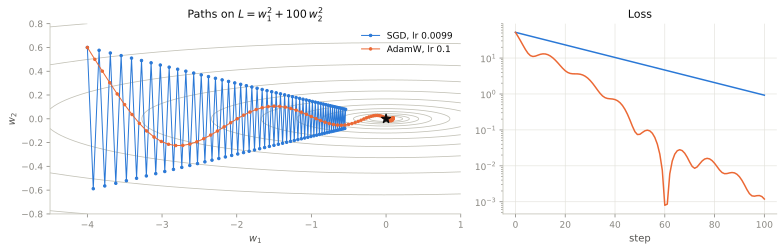

In [141]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Left: contour plot of an elongated ravine with two optimisation paths from the left. SGD zig-zags vertically across the narrow valley while creeping slowly to the right; AdamW moves diagonally and smoothly to the minimum at the origin. Right: loss against step on a log scale; AdamW drops to about 0.01 within about 60 steps while SGD is still near 1 after 100."
# plot helper: paths on the ravine's contours, and loss per step
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.5, 1]})
g1, g2 = np.meshgrid(np.linspace(-4.5, 1.0, 300), np.linspace(-0.8, 0.8, 300))
ax1.contour(g1, g2, g1 ** 2 + 100 * g2 ** 2, levels=np.geomspace(0.05, 80, 12), colors=HAIRLINE, linewidths=0.8)
for (name, path), color in zip(ravine_paths.items(), [SERIES[0], SERIES[1]]):
    ax1.plot(path[:, 0], path[:, 1], "-o", color=color, lw=1, ms=2.5, label=name)
    ax2.plot(np.arange(len(path)), [ravine(w) for w in path], color=color, lw=1.5, label=name)
ax1.plot(0, 0, "*", color=INK, ms=10); ax1.set_xlabel("$w_1$"); ax1.set_ylabel("$w_2$"); ax1.set_title("Paths on $L = w_1^2 + 100\\,w_2^2$")
ax1.legend(loc="upper right"); ax1.grid(False)
ax2.set_yscale("log"); ax2.set_xlabel("step"); ax2.set_title("Loss")
fig.tight_layout()
plt.show()

*Figure 26: A ravine with condition number 100. SGD's learning rate is capped by the steep direction, so it bounces across the valley and creeps along it. AdamW scales each coordinate by its own gradient size and heads almost straight for the minimum.*
{.caption}

**The Rosenbrock function** ([Rosenbrock, 1960](https://doi.org/10.1093/comjnl/3.3.175)), $L(w) = (1 - w_1)^2 + 100\,(w_2 - w_1^2)^2$, is a classic hard case: a long, curved, narrow valley whose floor descends very gently to the minimum at $(1, 1)$. The valley's steepness changes along the way, so no single learning rate suits it. We start at the traditional point $(-1.2, 1)$ and run 1000 steps, giving SGD the best of five learning rates.

In [ ]:
# Rosenbrock's valley
rosen = lambda w: (1 - w[0]) ** 2 + 100 * (w[1] - w[0] ** 2) ** 2
rosen_grad = lambda w: np.array([-2 * (1 - w[0]) - 400 * w[0] * (w[1] - w[0] ** 2), 200 * (w[1] - w[0] ** 2)])
print("SGD, loss after 1000 steps by learning rate:",
      {lr: round(float(rosen(optimise(rosen_grad, [-1.2, 1.0], "sgd", lr, 1000)[-1])), 3) for lr in [0.001, 0.002, 0.003, 0.004, 0.005]})
rosen_paths = {"SGD, lr 0.003": optimise(rosen_grad, [-1.2, 1.0], "sgd", 0.003, 1000),
               "AdamW, lr 0.1": optimise(rosen_grad, [-1.2, 1.0], "adamw", 0.1, 1000)}
for name, path in rosen_paths.items():
    print(f"Rosenbrock, {name:13s}: loss after 50 / 200 / 1000 steps = {rosen(path[50]):.3g} / {rosen(path[200]):.3g} / {rosen(path[1000]):.2g}, ends at {path[-1].round(3)}")

SGD, loss after 1000 steps by learning rate: {0.001: 0.454, 0.002: 0.071, 0.003: 0.045, 0.004: 0.501, 0.005: 0.741}
Rosenbrock, SGD, lr 0.003: loss after 50 / 200 / 1000 steps = 1.68 / 0.369 / 0.045, ends at [0.788 0.622]
Rosenbrock, AdamW, lr 0.1: loss after 50 / 200 / 1000 steps = 3.73 / 0.998 / 1.2e-05, ends at [0.996 0.993]


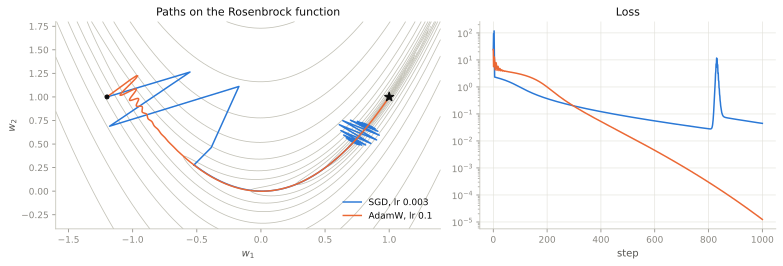

In [143]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Left: contour plot of the curved Rosenbrock valley with two paths from (-1.2, 1). SGD drops into the valley quickly and then crawls a short way along its floor; AdamW follows the curved floor all the way to the minimum at (1, 1). Right: loss against step on a log scale; SGD falls fast at first, then flattens, with a brief spike near step 830 where it is thrown out of the valley, ending near 0.05; AdamW is slower early but falls steadily to about 1e-5."
# plot helper: paths on Rosenbrock's contours, and loss per step
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
g1, g2 = np.meshgrid(np.linspace(-1.6, 1.4, 300), np.linspace(-0.4, 1.8, 300))
ax1.contour(g1, g2, (1 - g1) ** 2 + 100 * (g2 - g1 ** 2) ** 2, levels=np.geomspace(0.01, 300, 14), colors=HAIRLINE, linewidths=0.8)
for (name, path), color in zip(rosen_paths.items(), [SERIES[0], SERIES[1]]):
    ax1.plot(path[:, 0], path[:, 1], "-", color=color, lw=1.5, label=name)
    ax2.plot(np.arange(len(path)), [rosen(w) for w in path], color=color, lw=1.5, label=name)
ax1.plot(1, 1, "*", color=INK, ms=10); ax1.plot(-1.2, 1, "o", color=INK, ms=4)
ax1.set_xlabel("$w_1$"); ax1.set_ylabel("$w_2$"); ax1.set_title("Paths on the Rosenbrock function"); ax1.legend(loc="lower right"); ax1.grid(False)
ax2.set_yscale("log"); ax2.set_xlabel("step"); ax2.set_title("Loss")
fig.tight_layout()
plt.show()

*Figure 27: SGD at its best learning rate drops into the valley faster than AdamW but then crawls along the gently sloping floor, still far from the minimum after 1000 steps, and its step is so close to the stability limit that it is briefly thrown out of the valley near step 830. AdamW's per-coordinate step sizes let it follow the curved floor all the way to $(1, 1)$.*
{.caption}

### AdamW in the library

The optimiser is chosen in `train`, and the per-parameter moment estimates live on the model. Weight decay is applied, decoupled, to the weights only; biases, $\gamma$ and $\beta$ are not decayed. `optimizer="sgd"` falls back to the parent class's update unchanged, so the same class runs both optimisers.

| Method | Change | Why |
|---|---|---|
| `train` | reads `optimizer` (`"adamw"` or `"sgd"`) and `betas`; resets the moment estimates and the step count | a fresh optimiser state for every run |
| `adamw_step` (new) | runs `adamw` for one parameter array, keeping its $(m, v)$ in `self.state` | each parameter needs its own running averages |
| `update_parameters` | AdamW for every weight, bias, $\gamma$ and $\beta$; or the parent's SGD update | equation (54) |

In [144]:
class NeuralNetworkAdamW(NeuralNetworkBN):
    def __init__(self, layers, momentum=0.1, eps=1e-5):
        super().__init__(layers, momentum, eps)
        self.optimizer = "adamw"
        self.betas = (0.9, 0.999)
        self.state = {}       # (m, v) for every parameter array
        self.t = 0            # step count, for bias correction


    def train(self, train_x, train_y, test_x, test_y, **kwargs):
        self.optimizer = kwargs.get("optimizer", "adamw")      # "adamw" or "sgd"
        self.betas = kwargs.get("betas", (0.9, 0.999))
        self.state, self.t = {}, 0
        return super().train(train_x, train_y, test_x, test_y, **kwargs)


    def adamw_step(self, key, w, grad, weight_decay):
        m, v = self.state.get(key, (np.zeros_like(w), np.zeros_like(w)))
        w, m, v = adamw(w, grad, m, v, self.t, self.lr, *self.betas, weight_decay=weight_decay)
        self.state[key] = (m, v)
        return w


    def update_parameters(self, grad):
        if self.optimizer == "sgd":
            return super().update_parameters(grad)
        self.t += 1
        for l_key in range(1, self.n_layers + 1):
            self.weights[l_key].weights = self.adamw_step(("w", l_key), self.weights[l_key].weights, grad[l_key].dw, self.weight_decay)
            self.bias[l_key].weights = self.adamw_step(("b", l_key), self.bias[l_key].weights, grad[l_key].db, 0.0)
        for l_key in range(1, self.n_layers):
            self.gamma[l_key].weights = self.adamw_step(("gamma", l_key), self.gamma[l_key].weights, grad[l_key].dgamma, 0.0)
            self.beta[l_key].weights = self.adamw_step(("beta", l_key), self.beta[l_key].weights, grad[l_key].dbeta, 0.0)

**The full run.** SGD and AdamW on the spiral, both with Kaiming initialisation and BatchNorm, for 50 epochs. Note that AdamW's learning rate is a step length per parameter, so its good values are much smaller than SGD's.

In [ ]:
# SGD vs AdamW on the spiral, both with Kaiming init and BatchNorm
opt_runs = {}
for name, kwargs in [("SGD, lr 0.1", dict(optimizer="sgd", lr=0.1)), ("AdamW, lr 0.003", dict(optimizer="adamw", lr=0.003)),
                     ("AdamW, lr 0.01", dict(optimizer="adamw", lr=0.01))]:
    model = NeuralNetworkAdamW(layers)
    history = quiet_train(model, train_X, train_Y, test_X, test_Y, epochs=50, **kwargs)
    opt_runs[name] = history
    first95 = next((i + 1 for i, a in enumerate(history["test_acc"]) if a >= 0.95), None)
    print(f"{name:16s} test acc {history['test_acc'][-1]:.3f} | test loss {history['test_loss'][-1]:.3f} | first epoch with test acc >= 95%: {first95}")

SGD, lr 0.1      test acc 0.994 | test loss 0.079 | first epoch with test acc >= 95%: 6


AdamW, lr 0.003  test acc 1.000 | test loss 0.071 | first epoch with test acc >= 95%: 4


AdamW, lr 0.01   test acc 0.972 | test loss 0.082 | first epoch with test acc >= 95%: 4


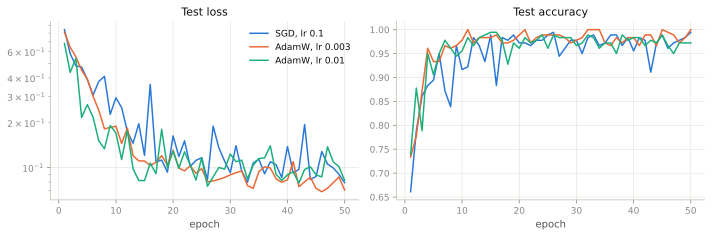

In [146]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Two charts over 50 epochs comparing SGD at learning rate 0.1 with AdamW at 0.003 and 0.01, all with BatchNorm. Left, test loss on a log scale: both AdamW runs fall faster in the first epochs. Right, test accuracy: the AdamW runs pass 95% a little earlier; all three end between 97% and 100%."
# plot helper: test loss and accuracy per epoch for both optimisers
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
for (name, history), color in zip(opt_runs.items(), [SERIES[0], SERIES[1], SERIES[2]]):
    epochs = np.arange(1, len(history["test_loss"]) + 1)
    ax1.plot(epochs, history["test_loss"], color=color, lw=1.5, label=name)
    ax2.plot(epochs, history["test_acc"], color=color, lw=1.5, label=name)
ax1.set_yscale("log"); ax1.set_title("Test loss"); ax2.set_title("Test accuracy")
for ax in (ax1, ax2):
    ax.set_xlabel("epoch")
ax1.legend(loc="upper right")
fig.tight_layout()
plt.show()

*Figure 28: On the spiral, AdamW gets there a few epochs sooner; with BatchNorm already smoothing the landscape, the gap is small. Adam's advantage grows with the condition number of the problem, which is why it is the default for large models.*
{.caption}

**✓ End of Part 4: Make it robust.** The library now has Kaiming initialisation, weight decay, BatchNorm and AdamW. Part 5 puts all of it to the test on MNIST.
{.checkpoint}

---

## From Spirals to MNIST

Everything we built so far was tested on 720 two-dimensional points. Now for a real dataset: **MNIST** ([LeCun et al., 1998](https://doi.org/10.1109/5.726791)), 70,000 handwritten digits, each a $28\times28$ grayscale image, so each sample has 784 input features and one of 10 labels. As a reference we build the *identical* network in PyTorch and train both side by side.

In [147]:
#| echo: false
# setup: read MNIST from the local Hugging Face cache without contacting the Hub, and keep its log messages
# (which include local cache paths) out of the published output
import os
os.environ["HF_DATASETS_OFFLINE"] = "1"
import datasets
datasets.logging.set_verbosity_error()
datasets.disable_progress_bars()

In [ ]:
# load MNIST (downloads ~20 MB the first time, then reads from the local cache)
from datasets import load_dataset

mnist = load_dataset("ylecun/mnist")

def to_numpy(split):
    d = mnist[split].with_format("numpy")
    x = np.asarray(d["image"], dtype=np.float32).reshape(len(d), -1) / 255.0    # (N, 784), pixels in [0, 1]
    y = np.asarray(d["label"])
    return x, y

mnist_train_X, mnist_train_Y = to_numpy("train")
mnist_test_X, mnist_test_Y = to_numpy("test")
pixel_mean, pixel_std = mnist_train_X.mean(), mnist_train_X.std()
mnist_train_X = (mnist_train_X - pixel_mean) / pixel_std     # standardise with training-set statistics
mnist_test_X = (mnist_test_X - pixel_mean) / pixel_std
print(mnist_train_X.shape, mnist_test_X.shape, "| digits per class (train):", np.bincount(mnist_train_Y))

(60000, 784) (10000, 784) | digits per class (train): [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


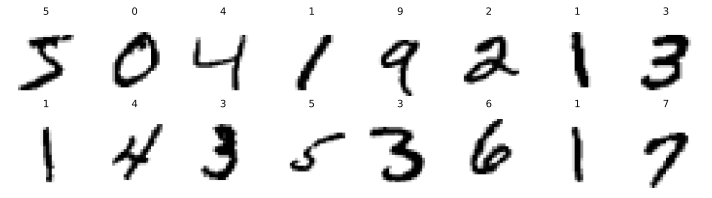

In [149]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "A grid of 16 handwritten digits from the MNIST training set, two rows of eight, each labelled with its class."
# plot helper: a few training digits
fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))
for ax, i in zip(axes.ravel(), range(16)):
    ax.imshow(mnist_train_X[i].reshape(28, 28), cmap="gray_r")
    ax.set_title(str(mnist_train_Y[i]), fontsize=10); ax.axis("off")
fig.tight_layout()
plt.show()

*Figure 29: Sixteen MNIST training digits with their labels.*
{.caption}

**The network.** $784\to512\to256\to10$ with BatchNorm and ReLU after each hidden layer, Kaiming initialisation, and AdamW (learning rate $10^{-3}$, weight decay $10^{-4}$), trained for 10 epochs with mini-batches of 128. That is 537,354 trainable parameters, including BatchNorm's $\gamma$ and $\beta$.

In [ ]:
# the full library on MNIST
import time

mnist_layers = [512, 256, 10]
mnist_config = dict(lr=1e-3, epochs=10, batch_size=128, weight_decay=1e-4, optimizer="adamw", log_every=1)
numpy_model = NeuralNetworkAdamW(mnist_layers)
start = time.perf_counter()
numpy_history = numpy_model.train(mnist_train_X, mnist_train_Y, mnist_test_X, mnist_test_Y, **mnist_config)
numpy_seconds = (time.perf_counter() - start) / mnist_config["epochs"]
print(f"NumPy: {numpy_seconds:.2f} s per epoch")

epoch    1/10 | train loss 0.1845 acc 0.945 | test loss 0.0908 acc 0.972


epoch    2/10 | train loss 0.0681 acc 0.980 | test loss 0.0677 acc 0.979


epoch    3/10 | train loss 0.0433 acc 0.987 | test loss 0.0669 acc 0.979


epoch    4/10 | train loss 0.0287 acc 0.991 | test loss 0.0831 acc 0.973


epoch    5/10 | train loss 0.0243 acc 0.992 | test loss 0.0720 acc 0.978


epoch    6/10 | train loss 0.0174 acc 0.995 | test loss 0.0698 acc 0.979


epoch    7/10 | train loss 0.0136 acc 0.996 | test loss 0.0673 acc 0.981


epoch    8/10 | train loss 0.0140 acc 0.996 | test loss 0.0680 acc 0.980


epoch    9/10 | train loss 0.0133 acc 0.995 | test loss 0.0773 acc 0.978


epoch   10/10 | train loss 0.0119 acc 0.996 | test loss 0.0725 acc 0.982
NumPy: 1.79 s per epoch


**The PyTorch twin.** For a fair comparison, everything is the same except the library: the same layers, the same initial weights (copied from our initialisers), BatchNorm with the same momentum and $\epsilon$, AdamW with the same hyperparameters, decaying only the weights, and the same mini-batches in the same order (our `data_iterator` with the same seed). Both run on the CPU in `float64`.

In [ ]:
# the identical network in PyTorch
import torch

class TorchMLP(torch.nn.Module):
    def __init__(self, sizes):                          # sizes = [784, 512, 256, 10]
        super().__init__()
        mods = []
        for i in range(len(sizes) - 1):
            mods.append(torch.nn.Linear(sizes[i], sizes[i + 1]))
            if i < len(sizes) - 2:
                mods += [torch.nn.BatchNorm1d(sizes[i + 1], momentum=0.1, eps=1e-5), torch.nn.ReLU()]
        self.net = torch.nn.Sequential(*mods)

    def forward(self, x):
        return self.net(x)

torch_model = TorchMLP([784] + mnist_layers).double()
init_w = NeuralNetworkAdamW.weight_init(mnist_layers, 784)      # our Kaiming initial weights
init_b = NeuralNetworkAdamW.bias_init(mnist_layers)
linears = [m for m in torch_model.net if isinstance(m, torch.nn.Linear)]
with torch.no_grad():
    for l_key, lin in enumerate(linears, start=1):
        lin.weight.copy_(torch.from_numpy(init_w[l_key].weights))     # both store W as (n_out, n_in)
        lin.bias.copy_(torch.from_numpy(init_b[l_key].weights))

decay = [lin.weight for lin in linears]
no_decay = [p for name, p in torch_model.named_parameters() if not (name.endswith("weight") and p.dim() == 2)]
torch_opt = torch.optim.AdamW([{"params": decay, "weight_decay": 1e-4}, {"params": no_decay, "weight_decay": 0.0}],
                              lr=1e-3, betas=(0.9, 0.999), eps=1e-8)

def torch_eval(x, y):
    torch_model.eval()
    with torch.no_grad():
        logits = torch_model(torch.from_numpy(x).double())
        loss = torch.nn.functional.cross_entropy(logits, torch.from_numpy(y)).item()
        acc = (logits.argmax(dim=-1).numpy() == y).mean()
    torch_model.train()
    return acc, loss

torch_history = defaultdict(list)
rng = np.random.default_rng(42)                        # the same seed train() uses -> the same batches
start = time.perf_counter()
for epoch in range(1, mnist_config["epochs"] + 1):
    epoch_loss, n_seen = 0.0, 0
    for xb, yb in data_iterator((mnist_train_X, mnist_train_Y), 128, shuffle=True, rng=rng):
        logits = torch_model(torch.from_numpy(xb).double())
        loss = torch.nn.functional.cross_entropy(logits, torch.from_numpy(yb))
        torch_opt.zero_grad()
        loss.backward()
        torch_opt.step()
        epoch_loss += loss.item() * len(yb)
        n_seen += len(yb)
    test_acc, test_loss = torch_eval(mnist_test_X, mnist_test_Y)
    torch_history["train_loss"].append(epoch_loss / n_seen)
    torch_history["test_acc"].append(test_acc)
    torch_history["test_loss"].append(test_loss)
    print(f"epoch {epoch:>4}/{mnist_config['epochs']} | train loss {epoch_loss / n_seen:.4f} | test loss {test_loss:.4f} acc {test_acc:.3f}")
torch_seconds = (time.perf_counter() - start) / mnist_config["epochs"]
print(f"PyTorch: {torch_seconds:.2f} s per epoch")

epoch    1/10 | train loss 0.1845 | test loss 0.0909 acc 0.973


epoch    2/10 | train loss 0.0681 | test loss 0.0678 acc 0.979


epoch    3/10 | train loss 0.0433 | test loss 0.0668 acc 0.979


epoch    4/10 | train loss 0.0287 | test loss 0.0824 acc 0.973


epoch    5/10 | train loss 0.0243 | test loss 0.0718 acc 0.978


epoch    6/10 | train loss 0.0174 | test loss 0.0698 acc 0.979


epoch    7/10 | train loss 0.0136 | test loss 0.0673 acc 0.980


epoch    8/10 | train loss 0.0140 | test loss 0.0677 acc 0.980


epoch    9/10 | train loss 0.0133 | test loss 0.0770 acc 0.978


epoch   10/10 | train loss 0.0119 | test loss 0.0721 acc 0.982
PyTorch: 1.17 s per epoch


In [ ]:
# side by side
print(f"{'epoch':>5s} | {'NumPy train loss':>16s} {'PyTorch':>9s} | {'NumPy test acc':>14s} {'PyTorch':>8s}")
for e in range(mnist_config["epochs"]):
    print(f"{e + 1:>5d} | {numpy_history['train_loss'][e]:16.5f} {torch_history['train_loss'][e]:9.5f} | "
          f"{numpy_history['test_acc'][e]:14.4f} {torch_history['test_acc'][e]:8.4f}")
print(f"largest difference in epoch train loss: {np.max(np.abs(np.array(numpy_history['train_loss']) - np.array(torch_history['train_loss']))):.1e}")

epoch | NumPy train loss   PyTorch | NumPy test acc  PyTorch
    1 |          0.18451   0.18451 |         0.9722   0.9725
    2 |          0.06809   0.06809 |         0.9786   0.9786
    3 |          0.04326   0.04326 |         0.9788   0.9787
    4 |          0.02872   0.02872 |         0.9726   0.9727
    5 |          0.02429   0.02429 |         0.9783   0.9783
    6 |          0.01743   0.01743 |         0.9786   0.9786
    7 |          0.01356   0.01356 |         0.9805   0.9803
    8 |          0.01402   0.01402 |         0.9798   0.9799
    9 |          0.01330   0.01330 |         0.9784   0.9782
   10 |          0.01187   0.01187 |         0.9823   0.9822
largest difference in epoch train loss: 1.1e-12


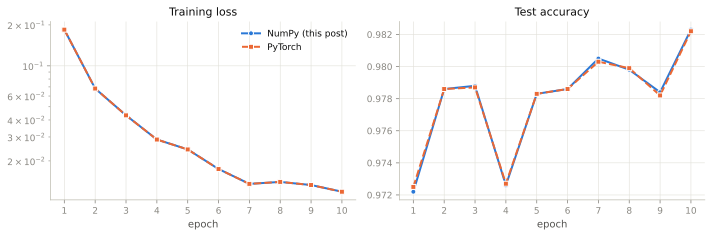

In [153]:
#| code-fold: true
#| code-summary: "Plot code"
#| fig-alt: "Two charts over 10 epochs comparing our NumPy network with its PyTorch twin. Left, training loss: the two lines lie on top of each other, falling from about 0.2 to below 0.02. Right, test accuracy: both lines lie on top of each other at about 98%."
# plot helper: NumPy vs PyTorch on MNIST
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
epochs = np.arange(1, mnist_config["epochs"] + 1)
for history, name, color, style in [(numpy_history, "NumPy (this post)", SERIES[0], "-o"), (torch_history, "PyTorch", SERIES[1], "--s")]:
    ax1.plot(epochs, history["train_loss"], style, color=color, ms=5, mec="white", label=name)
    ax2.plot(epochs, history["test_acc"], style, color=color, ms=5, mec="white", label=name)
ax1.set_yscale("log"); ax1.set_title("Training loss"); ax2.set_title("Test accuracy")
for ax in (ax1, ax2):
    ax.set_xlabel("epoch"); ax.set_xticks(epochs)
ax1.legend(loc="upper right")
fig.tight_layout()
plt.show()

*Figure 30: Our NumPy library and PyTorch, trained from the same initial weights on the same batches. The curves lie on top of each other.*
{.caption}

The two implementations agree step for step: the epoch losses differ only in the last digits, which is floating-point rounding (the two libraries add numbers in different orders). Test accuracies can differ very slightly because PyTorch's BatchNorm stores the *unbiased* variance in its running statistics, while ours stores the biased one. With about 98% test accuracy, a simple MLP written from scratch matches what PyTorch produces for the same model. Even the speed is in the same league on a CPU: in this run PyTorch needed 1.2 s per epoch and our NumPy code 1.9 s, because NumPy's matrix products call the same kind of optimised linear-algebra routines. What PyTorch adds is everything around the maths: automatic differentiation instead of hand-written backward passes, GPU kernels, and `float32` or lower precision for speed.

**✓ End of Part 5: Prove it.** A library you wrote line by line matches PyTorch on a real dataset. You have built, trained and stabilised a neural network from scratch, and you know what every line does.
{.checkpoint}

---

## Cite this post

```{=html}
<div class="citation-box">
```

### Blog link

Raj, Pratosh. "Neural Networks from Scratch in NumPy, Verified Against PyTorch." *PR Blogs*, November 11, 2026. [https://pratoshraj-pr.github.io/posts/nn-from-scratch-numpy/](https://pratoshraj-pr.github.io/posts/nn-from-scratch-numpy/)

### BibTeX

```bibtex
@article{raj2026nnnumpy,
  title   = {Neural Networks from Scratch in NumPy, Verified Against PyTorch},
  author  = {Raj, Pratosh},
  journal = {PR Blogs},
  year    = {2026},
  month   = nov,
  url     = {https://pratoshraj-pr.github.io/posts/nn-from-scratch-numpy/}
}
```

```{=html}
</div>
```

---

## Further Reading

We now have a complete, if small, training stack: forward and backward passes for linear layers, ReLU, softmax and cross-entropy; SGD and AdamW; Kaiming initialisation; weight decay; and BatchNorm. Here is what a full-scale training setup adds, and where to read about it.

- **More regularisation.** *Dropout* randomly zeroes activations during training ([Srivastava et al., 2014](https://jmlr.org/papers/v15/srivastava14a.html)); *data augmentation* trains on transformed copies of the data; *early stopping* keeps the weights from the epoch with the lowest validation loss (the minimum in Figure 18); *label smoothing* softens one-hot targets ([Szegedy et al., 2016](https://arxiv.org/abs/1512.00567)).
- **Other normalisations.** BatchNorm depends on the batch. *LayerNorm* normalises over the features of each sample instead and is the standard choice in transformers ([Ba et al., 2016](https://arxiv.org/abs/1607.06450)); *GroupNorm* suits small batches in vision ([Wu & He, 2018](https://arxiv.org/abs/1803.08494)).
- **Residual connections.** Adding a layer's input to its output, $x_{l+1} = x_l + f(x_l)$, gives gradients a direct path back through the network and makes networks with hundreds of layers trainable ([He et al., 2016](https://arxiv.org/abs/1512.03385)).
- **Learning-rate schedules and clipping.** Warmup followed by a decaying (often cosine) schedule ([Loshchilov & Hutter, 2017](https://arxiv.org/abs/1608.03983); [Goyal et al., 2017](https://arxiv.org/abs/1706.02677)), and clipping the gradient norm to survive occasional spikes ([Pascanu et al., 2013](https://arxiv.org/abs/1211.5063)).
- **Architectures beyond the MLP.** Convolutional networks share weights across image positions ([LeCun et al., 1998](https://doi.org/10.1109/5.726791)); transformers use attention to mix information across a sequence ([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)).
- **Automatic differentiation.** Instead of writing a backward function for every operation, record the operations as a graph during the forward pass and apply the chain rule to it automatically, as PyTorch does. Andrej Karpathy's [micrograd](https://github.com/karpathy/micrograd) builds one in about 100 lines.
- **Scale.** Mixed-precision training ([Micikevicius et al., 2018](https://arxiv.org/abs/1710.03740)) and data, tensor and pipeline parallelism across many GPUs, with optimiser-state sharding such as ZeRO ([Rajbhandari et al., 2020](https://arxiv.org/abs/1910.02054)).

For a longer path: [CS231n's course notes](https://cs231n.github.io/), [*Dive into Deep Learning*](https://d2l.ai/), and Karpathy's [Neural Networks: Zero to Hero](https://karpathy.ai/zero-to-hero.html) series.

---

## References

1. Cybenko, G. (1989). [Approximation by superpositions of a sigmoidal function](https://doi.org/10.1007/BF02551274). *Mathematics of Control, Signals and Systems*, 2(4), 303–314.
2. Hornik, K., Stinchcombe, M., & White, H. (1989). [Multilayer feedforward networks are universal approximators](https://doi.org/10.1016/0893-6080(89)90020-8). *Neural Networks*, 2(5), 359–366.
3. Leshno, M., Lin, V. Y., Pinkus, A., & Schocken, S. (1993). [Multilayer feedforward networks with a nonpolynomial activation function can approximate any function](https://doi.org/10.1016/S0893-6080(05)80131-5). *Neural Networks*, 6(6), 861–867.
4. Nair, V., & Hinton, G. E. (2010). [Rectified linear units improve restricted Boltzmann machines](https://www.cs.toronto.edu/~hinton/absps/reluICML.pdf). *ICML*.
5. Glorot, X., Bordes, A., & Bengio, Y. (2011). [Deep sparse rectifier neural networks](https://proceedings.mlr.press/v15/glorot11a.html). *AISTATS*.
6. Montúfar, G., Pascanu, R., Cho, K., & Bengio, Y. (2014). [On the number of linear regions of deep neural networks](https://arxiv.org/abs/1402.1869). *NeurIPS*.
7. Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep Learning*. MIT Press. [Chapter 6: Deep feedforward networks](https://www.deeplearningbook.org/contents/mlp.html); [Chapter 7: Regularization](https://www.deeplearningbook.org/contents/regularization.html); [Chapter 8: Optimization for training deep models](https://www.deeplearningbook.org/contents/optimization.html).
8. Rumelhart, D. E., Hinton, G. E., & Williams, R. J. (1986). [Learning representations by back-propagating errors](https://doi.org/10.1038/323533a0). *Nature*, 323, 533–536.
9. Baydin, A. G., Pearlmutter, B. A., Radul, A. A., & Siskind, J. M. (2018). [Automatic differentiation in machine learning: a survey](https://jmlr.org/papers/v18/17-468.html). *JMLR*, 18(153), 1–43.
10. Olah, C. (2015). [Calculus on computational graphs: backpropagation](https://colah.github.io/posts/2015-08-Backprop/). *colah's blog*.
11. Rosser, J. [Forward, backward, and hooks in PyTorch](https://jrosser.co.uk/knowledge_base/content/ml/hooks_explainer.html). *Notebooks on Maths, ML & AI*.
12. Robbins, H., & Monro, S. (1951). [A stochastic approximation method](https://doi.org/10.1214/aoms/1177729586). *The Annals of Mathematical Statistics*, 22(3), 400–407.
13. Bottou, L. (2010). [Large-scale machine learning with stochastic gradient descent](https://doi.org/10.1007/978-3-7908-2604-3_16). *COMPSTAT*.
14. PyTorch documentation: [`torch.nn.Linear`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html) and [`torch.nn.functional.cross_entropy`](https://pytorch.org/docs/stable/generated/torch.nn.functional.cross_entropy.html).
15. Glorot, X., & Bengio, Y. (2010). [Understanding the difficulty of training deep feedforward neural networks](https://proceedings.mlr.press/v9/glorot10a.html). *AISTATS*.
16. He, K., Zhang, X., Ren, S., & Sun, J. (2015). [Delving deep into rectifiers: surpassing human-level performance on ImageNet classification](https://arxiv.org/abs/1502.01852). *ICCV*.
17. Bartlett, P. L., Foster, D. J., & Telgarsky, M. (2017). [Spectrally-normalized margin bounds for neural networks](https://arxiv.org/abs/1706.08498). *NeurIPS*.
18. Tibshirani, R. (1996). [Regression shrinkage and selection via the lasso](https://doi.org/10.1111/j.2517-6161.1996.tb02080.x). *Journal of the Royal Statistical Society: Series B*, 58(1), 267–288.
19. Ioffe, S., & Szegedy, C. (2015). [Batch normalization: accelerating deep network training by reducing internal covariate shift](https://arxiv.org/abs/1502.03167). *ICML*.
20. Santurkar, S., Tsipras, D., Ilyas, A., & Madry, A. (2018). [How does batch normalization help optimization?](https://arxiv.org/abs/1805.11604) *NeurIPS*.
21. Arora, S., Li, Z., & Lyu, K. (2019). [Theoretical analysis of auto rate-tuning by batch normalization](https://arxiv.org/abs/1812.03981). *ICLR*.
22. Polyak, B. T. (1964). [Some methods of speeding up the convergence of iteration methods](https://doi.org/10.1016/0041-5553(64)90137-5). *USSR Computational Mathematics and Mathematical Physics*, 4(5), 1–17.
23. Tieleman, T., & Hinton, G. (2012). [Lecture 6.5, RMSProp: divide the gradient by a running average of its recent magnitude](https://www.cs.toronto.edu/~tijmen/csc321/slides/lecture_slides_lec6.pdf). *COURSERA: Neural Networks for Machine Learning*.
24. Kingma, D. P., & Ba, J. (2015). [Adam: a method for stochastic optimization](https://arxiv.org/abs/1412.6980). *ICLR*.
25. Loshchilov, I., & Hutter, F. (2019). [Decoupled weight decay regularization](https://arxiv.org/abs/1711.05101). *ICLR*.
26. Rosenbrock, H. H. (1960). [An automatic method for finding the greatest or least value of a function](https://doi.org/10.1093/comjnl/3.3.175). *The Computer Journal*, 3(3), 175–184.
27. LeCun, Y., Bottou, L., Bengio, Y., & Haffner, P. (1998). [Gradient-based learning applied to document recognition](https://doi.org/10.1109/5.726791). *Proceedings of the IEEE*, 86(11), 2278–2324.
28. Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). [Dropout: a simple way to prevent neural networks from overfitting](https://jmlr.org/papers/v15/srivastava14a.html). *JMLR*, 15(56), 1929–1958.
29. Szegedy, C., Vanhoucke, V., Ioffe, S., Shlens, J., & Wojna, Z. (2016). [Rethinking the Inception architecture for computer vision](https://arxiv.org/abs/1512.00567). *CVPR*.
30. Ba, J. L., Kiros, J. R., & Hinton, G. E. (2016). [Layer normalization](https://arxiv.org/abs/1607.06450). *arXiv*.
31. Wu, Y., & He, K. (2018). [Group normalization](https://arxiv.org/abs/1803.08494). *ECCV*.
32. He, K., Zhang, X., Ren, S., & Sun, J. (2016). [Deep residual learning for image recognition](https://arxiv.org/abs/1512.03385). *CVPR*.
33. Loshchilov, I., & Hutter, F. (2017). [SGDR: stochastic gradient descent with warm restarts](https://arxiv.org/abs/1608.03983). *ICLR*.
34. Goyal, P., et al. (2017). [Accurate, large minibatch SGD: training ImageNet in 1 hour](https://arxiv.org/abs/1706.02677). *arXiv*.
35. Pascanu, R., Mikolov, T., & Bengio, Y. (2013). [On the difficulty of training recurrent neural networks](https://arxiv.org/abs/1211.5063). *ICML*.
36. Vaswani, A., et al. (2017). [Attention is all you need](https://arxiv.org/abs/1706.03762). *NeurIPS*.
37. Micikevicius, P., et al. (2018). [Mixed precision training](https://arxiv.org/abs/1710.03740). *ICLR*.
38. Rajbhandari, S., Rasley, J., Ruwase, O., & He, Y. (2020). [ZeRO: memory optimizations toward training trillion parameter models](https://arxiv.org/abs/1910.02054). *SC20*.